# Feature geometry and hypotheses

Inspect distributions and temporal structure, then specify and test hypotheses about future behavior.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `Phase 3.ipynb`, original cells 0–165 (zero-based).


In [ ]:
from pathlib import Path
import os
import sys

# Locate the repository from its root or any notebook subdirectory.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "tradinguni_paths.py").is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from inside the TradingUni repository.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from tradinguni_paths import data_path, output_path
os.chdir(REPO_ROOT)


Scientific Loop: Feature → Hypothesis → Evidence

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

df = pl.read_parquet(str(data_path("0.Data -> Facts/phase_data/phase_2-1_ETH_1min_Market_Structure_Behavior_Feature.parquet")))

In [2]:
df.columns

['t',
 'open',
 'high',
 'low',
 'close',
 'vol_base',
 'vol_quote',
 'trade_count',
 'buy_count',
 'sell_count',
 'buy_quote',
 'sell_quote',
 'signed_quote',
 'vwap',
 'trade_rate',
 'imbalance',
 'range',
 'hl_pct',
 'prev_close',
 'ret_inbar',
 'ret_cc',
 'gap_oc',
 'dt_mean_ms',
 'dt_median_ms',
 'dt_p90_ms',
 'frac_dt0',
 'active_ms',
 'intensity_peak_1s',
 'realized_var_inbar',
 'dp0_frac',
 'n_price_changes',
 'up_ticks',
 'down_ticks',
 'max_up_move',
 'max_down_move',
 'n_returns',
 'avg_trade_q',
 'avg_trade_notional',
 'q_p50',
 'q_p90',
 'q_p99',
 'notional_p90',
 'notional_p99',
 'top1_share',
 'sign_persistence_inbar',
 'flip_count',
 'sign_entropy',
 'n_trans',
 'run_max',
 'run_mean',
 'is_sparse_stats',
 'is_sparse_seq',
 'is_sparse_top1',
 'gap_ms_from_last_trade',
 'is_no_trade_fill',
 'is_missing_fill',
 'A_t',
 'F_t',
 'P_t',
 'C_t',
 'V_t',
 'I_t',
 'eps_I',
 'I_t_filled',
 'V_log',
 'F_raw',
 'Fabs_log',
 'A_raw',
 'P_raw',
 'C_raw',
 'I_raw',
 'rk_V_fast',
 'rk

# Feature Geometry Understanding

In [2]:
import pandas as pd

In [3]:
def to_pandas(df):
    try:
        import polars as pl
        if isinstance(df, pl.DataFrame):
            return df.to_pandas()
    except Exception:
        pass
    if isinstance(df, pd.DataFrame):
        return df
    raise TypeError("df must be a pandas.DataFrame or polars.DataFrame")


def _series(df_pd: pd.DataFrame, col: str) -> pd.Series:
    if col not in df_pd.columns:
        raise KeyError(f"Missing col: {col}")
    return df_pd[col]


def _is_boolish(s: pd.Series) -> bool:
    # flags often are bool / {0,1} with possible null
    x = s.dropna()
    if len(x) == 0:
        return False
    if x.dtype == bool:
        return True
    uniq = pd.unique(x)
    if len(uniq) <= 3 and set(uniq).issubset({0, 1, True, False}):
        return True
    return False


def _nanfrac(s: pd.Series) -> float:
    return float(s.isna().mean())


def _zerofrac(s: pd.Series) -> float:
    x = s.dropna()
    if len(x) == 0:
        return np.nan
    # only makes sense for numeric
    try:
        return float((x == 0).mean())
    except Exception:
        return np.nan

## distribution + null/zero rates

In [4]:
def summarize_distribution(df, cols, quantiles=(0.01, 0.05, 0.5, 0.95, 0.99)):
    """
    Returns a summary table:
    n, nan_frac, zero_frac, mean/std (numeric), min/max, quantiles, unique_count (for flags)
    """
    df_pd = to_pandas(df)
    rows = []
    for c in cols:
        s = _series(df_pd, c)
        nanf = _nanfrac(s)
        zerof = _zerofrac(s)
        x = s.dropna()

        row = {"col": c, "n": int(len(s)), "n_nonnull": int(len(x)), "nan_frac": nanf, "zero_frac": zerof}

        if _is_boolish(s):
            # treat as flag
            if len(x) > 0:
                row["flag_mean"] = float(x.astype(float).mean())
                row["unique"] = int(pd.Series(x).nunique())
            else:
                row["flag_mean"] = np.nan
                row["unique"] = 0
        else:
            # numeric
            xnum = pd.to_numeric(x, errors="coerce").dropna()
            if len(xnum) > 0:
                row["mean"] = float(xnum.mean())
                row["std"] = float(xnum.std(ddof=1)) if len(xnum) > 1 else 0.0
                row["min"] = float(xnum.min())
                row["max"] = float(xnum.max())
                for q in quantiles:
                    row[f"q{int(q*100):02d}"] = float(xnum.quantile(q))
            else:
                row["mean"] = row["std"] = row["min"] = row["max"] = np.nan
                for q in quantiles:
                    row[f"q{int(q*100):02d}"] = np.nan

        rows.append(row)

    out = pd.DataFrame(rows).set_index("col").sort_values(["nan_frac", "zero_frac"], ascending=[False, False])
    return out

In [5]:
def plot_hist_ecdf(df, col, bins=80, clip=None, logy=False):
    """
    Histogram + ECDF in separate figures (simple + readable).
    clip: (lo, hi) in value space, to avoid insane tails.
    """
    df_pd = to_pandas(df)
    s = _series(df_pd, col).dropna()

    if len(s) == 0:
        print(f"[plot_hist_ecdf] {col}: all null")
        return

    x = pd.to_numeric(s, errors="coerce").dropna().values
    if clip is not None:
        lo, hi = clip
        x = x[(x >= lo) & (x <= hi)]
        if len(x) == 0:
            print(f"[plot_hist_ecdf] {col}: empty after clip")
            return

    # Histogram
    plt.figure()
    plt.hist(x, bins=bins)
    plt.title(f"Histogram: {col}  (n={len(x)})")
    if logy:
        plt.yscale("log")
    plt.grid(True, alpha=0.25)
    plt.show()

    # ECDF
    xs = np.sort(x)
    ys = np.arange(1, len(xs) + 1) / len(xs)
    plt.figure()
    plt.plot(xs, ys)
    plt.title(f"ECDF: {col}")
    plt.grid(True, alpha=0.25)
    plt.show()

## continuity/persistence (ACF-ish, lag corr)

In [6]:
def autocorr_at_lags(x: np.ndarray, lags=(1,2,3,5,10,30,60,240)):
    """
    Simple lag autocorrelation (Pearson) ignoring NaNs by pairwise drop.
    """
    x = np.asarray(x, dtype=float)
    out = {}
    for k in lags:
        if k <= 0 or k >= len(x):
            out[k] = np.nan
            continue
        a = x[:-k]
        b = x[k:]
        m = np.isfinite(a) & np.isfinite(b)
        if m.sum() < 10:
            out[k] = np.nan
            continue
        aa = a[m] - a[m].mean()
        bb = b[m] - b[m].mean()
        denom = (np.sqrt((aa**2).mean()) * np.sqrt((bb**2).mean()))
        out[k] = float((aa * bb).mean() / denom) if denom > 0 else np.nan
    return out

In [7]:
def plot_timeseries_slice(df, col, start=None, end=None, n=3000):
    """
    Plot a slice to visually inspect continuity.
    start/end: index positions (ints) OR timestamp strings if your df has 't' column as datetime.
    If no start/end given, plots last n points.
    """
    df_pd = to_pandas(df)
    s = _series(df_pd, col)

    # If user has 't' column and passes start/end as timestamp-like strings, try filtering by time.
    if "t" in df_pd.columns and (isinstance(start, str) or isinstance(end, str)):
        tt = pd.to_datetime(df_pd["t"], errors="coerce")
        m = pd.Series(True, index=df_pd.index)
        if start is not None:
            m &= (tt >= pd.to_datetime(start))
        if end is not None:
            m &= (tt <= pd.to_datetime(end))
        ss = s[m]
        tt2 = tt[m]
        if len(ss) == 0:
            print(f"[plot_timeseries_slice] {col}: empty for given time range")
            return
        plt.figure()
        plt.plot(tt2, ss)
        plt.title(f"Time series: {col} ({start}..{end})")
        plt.grid(True, alpha=0.25)
        plt.show()
        return

    # Otherwise slice by index
    if start is None and end is None:
        ss = s.iloc[-n:]
        xx = ss.index
    else:
        i0 = 0 if start is None else int(start)
        i1 = len(s) if end is None else int(end)
        ss = s.iloc[i0:i1]
        xx = ss.index

    plt.figure()
    plt.plot(xx, ss)
    plt.title(f"Time series (index slice): {col}")
    plt.grid(True, alpha=0.25)
    plt.show()

In [8]:
def persistence_report(df, cols, lags=(1,2,3,5,10,30,60,240)):
    """
    For each col: prints lag-autocorr table (rough 'continuity' score).
    Useful mainly for continuous state/memory series (mean/p90/frac/runlen).
    """
    df_pd = to_pandas(df)
    rows = []
    for c in cols:
        s = pd.to_numeric(_series(df_pd, c), errors="coerce").values
        ac = autocorr_at_lags(s, lags=lags)
        row = {"col": c}
        row.update({f"acf_{k}": v for k, v in ac.items()})
        rows.append(row)
    return pd.DataFrame(rows).set_index("col")

## temporal structure (runlen dist, flip rate check, spike interarrival sanity)

In [9]:
def runlen_distribution(df, runlen_col, bins=80, clip=None, logy=False):
    """
    For precomputed runlen_* columns: plot histogram
    """
    df_pd = to_pandas(df)
    s = pd.to_numeric(_series(df_pd, runlen_col), errors="coerce").dropna()
    if len(s) == 0:
        print(f"[runlen_distribution] {runlen_col}: all null")
        return
    x = s.values
    if clip is not None:
        lo, hi = clip
        x = x[(x >= lo) & (x <= hi)]
    plt.figure()
    plt.hist(x, bins=bins)
    plt.title(f"Runlen histogram: {runlen_col} (n={len(x)})")
    if logy:
        plt.yscale("log")
    plt.grid(True, alpha=0.25)
    plt.show()

In [10]:
def flip_rate_sanity(df, flag_col, L=60):
    """
    Quick sanity: compute flip rate from raw flag and compare its distribution.
    This helps you see if your provided *_flip_rate_* columns look plausible.
    flip_rate over last L = (# of changes in flag) / L
    """
    df_pd = to_pandas(df)
    f = _series(df_pd, flag_col)

    # coerce to {0,1} with NaN kept
    x = f.copy()
    if x.dtype == bool:
        x = x.astype(float)
    else:
        x = pd.to_numeric(x, errors="coerce")

    # changes: |x - x.shift(1)| == 1
    ch = (x - x.shift(1)).abs()
    ch = (ch == 1).astype(float)

    fr = ch.rolling(L, min_periods=max(10, L//4)).mean()
    return fr

In [11]:
def plot_feature_pack(df, cols, bins=80, clip_map=None):
    """
    Convenience: for each col, plot histogram + ECDF (skips if flag-ish)
    clip_map: dict {col: (lo, hi)}
    """
    df_pd = to_pandas(df)
    for c in cols:
        s = _series(df_pd, c)
        if _is_boolish(s):
            # For flags: show bar of mean (occupancy)
            x = s.dropna()
            if len(x) == 0:
                print(f"[flag] {c}: all null")
                continue
            m = float(pd.to_numeric(x, errors="coerce").mean())
            plt.figure()
            plt.bar([0], [m])
            plt.ylim(0, 1)
            plt.title(f"Flag occupancy (mean): {c} = {m:.3f}")
            plt.grid(True, alpha=0.25)
            plt.show()
        else:
            clip = clip_map.get(c) if clip_map else None
            plot_hist_ecdf(df_pd, c, bins=bins, clip=clip)

## Group

In [12]:
REGISTRY = {
    "G1_A_Activity": {
        "A_state": [
            "rk_slow_A_mean_60m",
            "rk_slow_A_p90_60m",
            "rk_slow_A_mean_240m",
            "rk_slow_A_p90_240m",
        ],
        "B_flag": [
            "rk_slow_A_hi",
            "rk_slow_A_xhi",
            "rk_slow_A_lo",
        ],
        "C_frac": [
            "rk_slow_A_hi_frac_60m",
            "rk_slow_A_xhi_frac_60m",
            "rk_slow_A_hi_frac_240m",
            "rk_slow_A_xhi_frac_240m",
        ],
        "D_struct": [
            "runlen_rk_slow_A_hi",
            "maxrun_runlen_rk_slow_A_hi_60m",
            "maxrun_runlen_rk_slow_A_hi_240m",
            "rk_slow_A_hi_flip_rate_60m",
            "rk_slow_A_hi_flip_rate_240m",
        ],
    },

    "G2_V_Volatility": {
        "A_state": [
            "rk_slow_V_mean_60m",
            "rk_slow_V_p90_60m",
            "rk_slow_V_mean_240m",
            "rk_slow_V_p90_240m",
        ],
        "B_flag": [
            "rk_slow_V_hi",
            "rk_slow_V_xhi",
            "rk_fast_V_spike",
        ],
        "C_frac": [
            "rk_slow_V_hi_frac_60m",
            "rk_slow_V_xhi_frac_60m",
            "rk_slow_V_hi_frac_240m",
            "rk_slow_V_xhi_frac_240m",
            "rk_fast_V_spike_frac_60m",
        ],
        "D_struct": [
            "runlen_rk_slow_V_hi",
            "runlen_rk_slow_V_xhi",
            "maxrun_runlen_rk_slow_V_hi_60m",
            "maxrun_runlen_rk_slow_V_hi_240m",
            "maxrun_runlen_rk_slow_V_xhi_60m",
            "maxrun_runlen_rk_slow_V_xhi_240m",
            "rk_fast_V_spike_interarrival_mean_240m",
            "rk_fast_V_spike_interarrival_cv_240m",
            "rk_slow_V_hi_flip_rate_60m",
            "rk_slow_V_hi_flip_rate_240m",
        ],
    },

    "G3_F_FlowStress": {
        "A_state": [
            "rk_slow_Fabs_mean_60m",
            "rk_slow_Fabs_p90_60m",
            "rk_slow_Fabs_mean_240m",
            "rk_slow_Fabs_p90_240m",
        ],
        "B_flag": [
            "rk_slow_Fabs_hi",
            "rk_slow_Fabs_xhi",
            "rk_fast_Fabs_spike",
        ],
        "C_frac": [
            "rk_slow_Fabs_hi_frac_60m",
            "rk_slow_Fabs_xhi_frac_60m",
            "rk_slow_Fabs_hi_frac_240m",
            "rk_slow_Fabs_xhi_frac_240m",
            "rk_fast_Fabs_spike_frac_60m",
        ],
        "D_struct": [
            "runlen_rk_slow_Fabs_hi",
            "runlen_rk_slow_Fabs_xhi",
            "maxrun_runlen_rk_slow_Fabs_hi_60m",
            "maxrun_runlen_rk_slow_Fabs_hi_240m",
            "maxrun_runlen_rk_slow_Fabs_xhi_60m",
            "maxrun_runlen_rk_slow_Fabs_xhi_240m",
            "rk_fast_Fabs_spike_interarrival_mean_240m",
            "rk_fast_Fabs_spike_interarrival_cv_240m",
            "rk_slow_Fabs_hi_flip_rate_60m",
            "rk_slow_Fabs_hi_flip_rate_240m",
        ],
    },

    "G4_P_Persistence": {
        "A_state": [
            "rk_slow_P_mean_60m",
            "rk_slow_P_p90_60m",
            "rk_slow_P_mean_240m",
            "rk_slow_P_p90_240m",
        ],
        "B_flag": [
            "rk_slow_P_lo",
            "rk_slow_P_xlo",
        ],
        "C_frac": [
            "rk_slow_P_lo_frac_60m",
            "rk_slow_P_xlo_frac_60m",
            "rk_slow_P_lo_frac_240m",
            "rk_slow_P_xlo_frac_240m",
        ],
        "D_struct": [
            "runlen_rk_slow_P_lo",
            "maxrun_runlen_rk_slow_P_lo_60m",
            "maxrun_runlen_rk_slow_P_lo_240m",
            "rk_slow_P_lo_flip_rate_60m",
            "rk_slow_P_lo_flip_rate_240m",
        ],
    },

    "G5_C_Concentration": {
        "A_state": [
            "rk_slow_C_mean_60m",
            "rk_slow_C_p90_60m",
            "rk_slow_C_mean_240m",
            "rk_slow_C_p90_240m",
        ],
        "B_flag": [
            "rk_slow_C_hi",
            "rk_slow_C_xhi",
        ],
        "C_frac": [
            "rk_slow_C_hi_frac_60m",
            "rk_slow_C_xhi_frac_60m",
            "rk_slow_C_hi_frac_240m",
            "rk_slow_C_xhi_frac_240m",
        ],
        "D_struct": [
            "runlen_rk_slow_C_hi",
            "maxrun_runlen_rk_slow_C_hi_60m",
            "maxrun_runlen_rk_slow_C_hi_240m",
            "rk_slow_C_hi_flip_rate_60m",
            "rk_slow_C_hi_flip_rate_240m",
        ],
    },
}

In [12]:
REGISTRY = {

    "G1_A_Activity_raw": {
        "A_state": [
            "A_raw_mean_60m",
            "A_raw_p90_60m",
            "A_raw_mean_240m",
            "A_raw_p90_240m",
        ],
        "B_flag": [
            "A_raw_hi",
            "A_raw_xhi",
        ],
        "C_frac": [
            "A_raw_hi_frac_60m",
            "A_raw_xhi_frac_60m",
            "A_raw_hi_frac_240m",
            "A_raw_xhi_frac_240m",
        ],
    },

    "G2_V_Volatility_raw": {
        "A_state": [
            "V_log_mean_60m",
            "V_log_p90_60m",
            "V_log_mean_240m",
            "V_log_p90_240m",
        ],
        "B_flag": [
            "V_log_hi",
        ],
        "C_frac": [
            "V_log_hi_frac_60m",
            "V_log_hi_frac_240m",
        ],
    },

    "G3_F_FlowStress_raw": {
        "A_state": [
            "Fabs_log_mean_60m",
            "Fabs_log_p90_60m",
            "Fabs_log_mean_240m",
            "Fabs_log_p90_240m",
        ],
        "B_flag": [
            "Fabs_log_hi",
        ],
        "C_frac": [
            "Fabs_log_hi_frac_60m",
            "Fabs_log_hi_frac_240m",
        ],
    },

    "G4_P_Persistence_raw": {
        "A_state": [
            "P_raw_mean_60m",
            "P_raw_p90_60m",
            "P_raw_mean_240m",
            "P_raw_p90_240m",
        ],
        "B_flag": [
            "P_raw_lo",
            "P_raw_hi",
        ],
        "C_frac": [
            "P_raw_lo_frac_60m",
            "P_raw_hi_frac_60m",
            "P_raw_lo_frac_240m",
            "P_raw_hi_frac_240m",
        ],
        "D_struct": [
            "runlen_P_raw_lo",
            "runlen_P_raw_hi",
            "maxrun_runlen_P_raw_lo_60m",
            "maxrun_runlen_P_raw_lo_240m",
            "maxrun_runlen_P_raw_hi_60m",
            "maxrun_runlen_P_raw_hi_240m",
            "P_raw_lo_flip_rate_60m",
            "P_raw_lo_flip_rate_240m",
            "P_raw_hi_flip_rate_60m",
            "P_raw_hi_flip_rate_240m",
        ],
    },

    "G5_C_Concentration_raw": {
        "A_state": [
            "C_raw_mean_60m",
            "C_raw_p90_60m",
            "C_raw_mean_240m",
            "C_raw_p90_240m",
        ],
        "B_flag": [
            "C_raw_hi",
            "C_raw_xhi",
        ],
        "C_frac": [
            "C_raw_hi_frac_60m",
            "C_raw_xhi_frac_60m",
            "C_raw_hi_frac_240m",
            "C_raw_xhi_frac_240m",
        ],
        "D_struct": [
            "runlen_C_raw_hi",
            "runlen_C_raw_xhi",
            "maxrun_runlen_C_raw_hi_60m",
            "maxrun_runlen_C_raw_hi_240m",
            "maxrun_runlen_C_raw_xhi_60m",
            "maxrun_runlen_C_raw_xhi_240m",
            "C_raw_hi_flip_rate_60m",
            "C_raw_hi_flip_rate_240m",
            "C_raw_xhi_flip_rate_60m",
            "C_raw_xhi_flip_rate_240m",
        ],
    },

    "G6_I_Impact_raw": {
        "A_state": [
            "I_raw_mean_60m",
            "I_raw_p90_60m",
            "I_raw_mean_240m",
            "I_raw_p90_240m",
        ],
        "B_flag": [
            "I_raw_event",
        ],
        "C_frac": [
            "I_raw_event_frac_60m",
            "I_raw_event_frac_240m",
        ],
    },
}

In [13]:
ABCD_KEYS = ("A_state", "B_flag", "C_frac", "D_struct")

In [14]:
def _present_cols(df, cols):
    df_pd = to_pandas(df)
    return [c for c in cols if c in df_pd.columns]

def get_cols(group_key, abcd_key):
    return REGISTRY[group_key][abcd_key]

In [15]:
def step2_summaries_by_group(df, quantiles=(0.01, 0.05, 0.5, 0.95, 0.99)):
    """
    Returns dict[(group, abcd)] -> summary DataFrame
    Uses your summarize_distribution().
    """
    out = {}
    for g in REGISTRY:
        for k in ABCD_KEYS:
            cols = _present_cols(df, REGISTRY[g][k])
            if not cols:
                continue
            out[(g, k)] = summarize_distribution(df, cols, quantiles=quantiles)
    return out

In [30]:
def step2_plots_by_group(df, group_key,
                         bins=80,
                         clip_map=None,
                         plot_A=True, plot_C=True, plot_D=True,
                         plot_flags_timeseries=True,
                         n_ts=3000):
    """
    Make plots for one group only (to avoid 1000 plots).
    clip_map: dict col->(lo,hi)
    """
    clip_map = clip_map or {}

    # A: continuous state
    if plot_A:
        for c in _present_cols(df, REGISTRY[group_key]["A_state"]):
            plot_hist_ecdf(df, c, bins=bins, clip=clip_map.get(c))

    # C: occupancy fractions
    if plot_C:
        for c in _present_cols(df, REGISTRY[group_key]["C_frac"]):
            plot_hist_ecdf(df, c, bins=bins, clip=clip_map.get(c))

    # D: structure
    if plot_D:
        for c in _present_cols(df, REGISTRY[group_key]["D_struct"]):
            if c.startswith("runlen_") or c.startswith("maxrun_"):
                runlen_distribution(df, c, bins=bins, clip=clip_map.get(c), logy=True)
            else:
                plot_hist_ecdf(df, c, bins=bins, clip=clip_map.get(c))

    # B: flags -> show as timeseries + optional flip sanity
    if plot_flags_timeseries:
        for c in _present_cols(df, REGISTRY[group_key]["B_flag"]):
            plot_timeseries_slice(df, c, n=n_ts)

In [32]:
def step3_persistence_by_group(df, group_key, lags=(1,2,3,5,10,30,60,240), include_flags=False):
    cols = []
    if "A_state" in REGISTRY[group_key]:
      cols += REGISTRY[group_key]["A_state"]
    if "C_frac" in REGISTRY[group_key]:
      cols += REGISTRY[group_key]["C_frac"]
    if "D_struct" in REGISTRY[group_key]:
      cols += REGISTRY[group_key]["D_struct"]
    if include_flags:
        cols += REGISTRY[group_key]["B_flag"]
    cols = _present_cols(df, cols)
    if not cols:
        return None
    return persistence_report(df, cols, lags=lags)

In [18]:
def step4_flip_sanity_by_group(df, group_key, L=60):
    out = {}
    for flag_col in _present_cols(df, REGISTRY[group_key]["B_flag"]):
        out[flag_col] = flip_rate_sanity(df, flag_col, L=L)
    return out

In [19]:
print(list(REGISTRY.keys()))

['G1_A_Activity_raw', 'G2_V_Volatility_raw', 'G3_F_FlowStress_raw', 'G4_P_Persistence_raw', 'G5_C_Concentration_raw', 'G6_I_Impact_raw']


## G1_A_Activity_raw

In [20]:
group_key = "G1_A_Activity_raw"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [28]:
for abcd in ABCD_KEYS:
        if abcd not in REGISTRY[group_key]:
            continue
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
A_raw_mean_60m,3156480,3153964,0.000797,0.0,0.005351,0.004820,0.000372,0.201288,0.000885,0.001302,0.003987,0.013810,0.023837
A_raw_p90_60m,3156480,3153964,0.000797,0.0,0.008768,0.008953,0.000500,0.306117,0.001383,0.002000,0.006133,0.023867,0.043450
A_raw_mean_240m,3156480,3154259,0.000704,0.0,0.005351,0.004198,0.000451,0.092781,0.000975,0.001403,0.004214,0.013003,0.021029
A_raw_p90_240m,3156480,3154259,0.000704,0.0,0.008887,0.007836,0.000717,0.208400,0.001567,0.002167,0.006700,0.022600,0.037883



--- B_flag (2 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
A_raw_xhi,3156480,3153978,0.000793,0.990003,0.009997,2
A_raw_hi,3156480,3153978,0.000793,0.950059,0.049941,2



--- C_frac (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
A_raw_xhi_frac_60m,3156480,3153964,0.000797,0.857078,0.009996,0.049024,0.0,1.0,0.0,0.0,0.000000,0.050000,0.200000
A_raw_hi_frac_60m,3156480,3153964,0.000797,0.627924,0.049940,0.134800,0.0,1.0,0.0,0.0,0.000000,0.283333,0.766667
A_raw_xhi_frac_240m,3156480,3154259,0.000704,0.648423,0.009995,0.036671,0.0,1.0,0.0,0.0,0.000000,0.045833,0.158333
A_raw_hi_frac_240m,3156480,3154259,0.000704,0.337053,0.049936,0.113334,0.0,1.0,0.0,0.0,0.008333,0.250000,0.612500


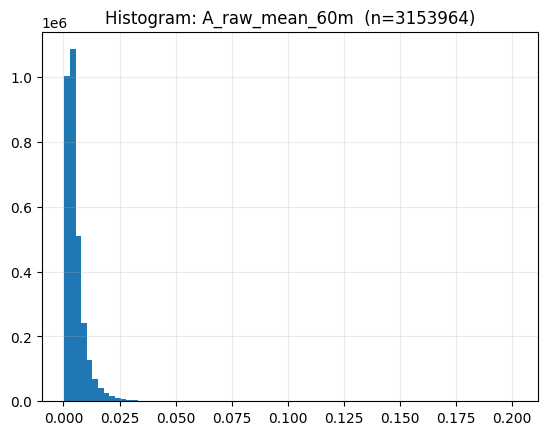

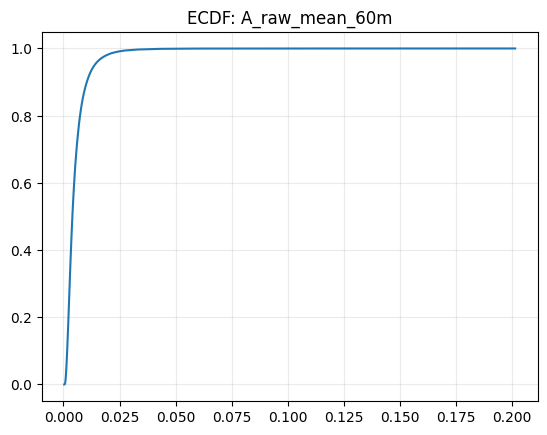

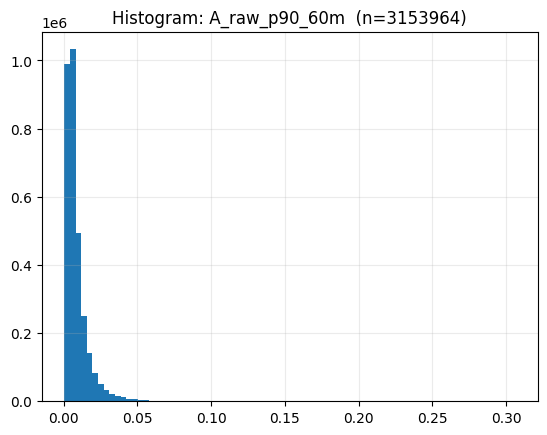

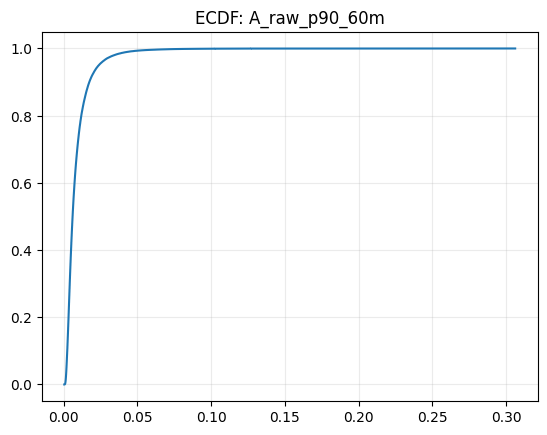

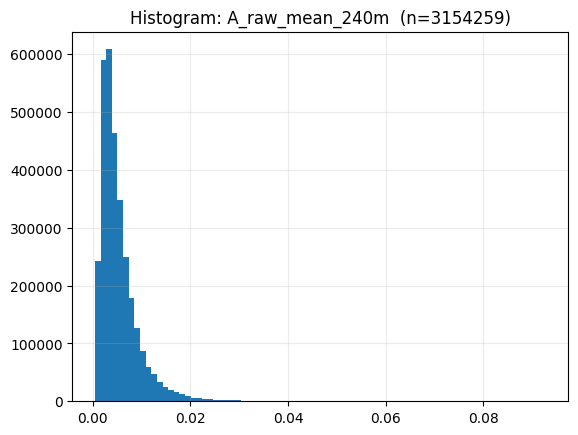

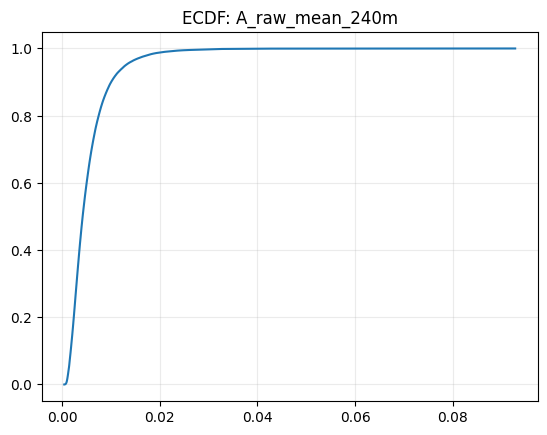

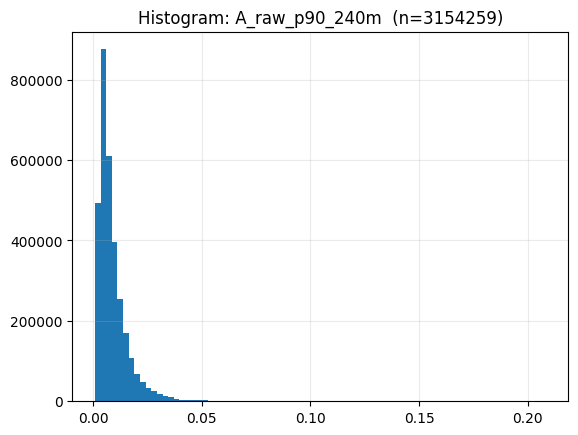

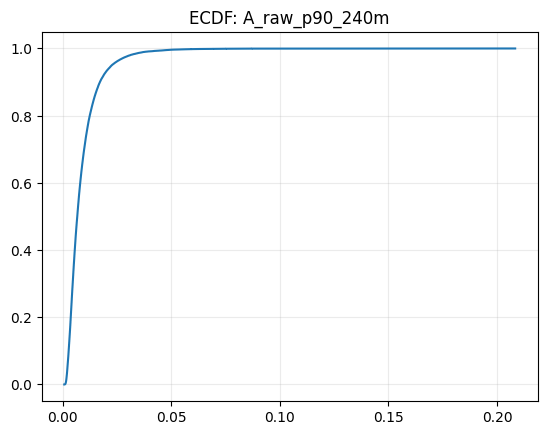

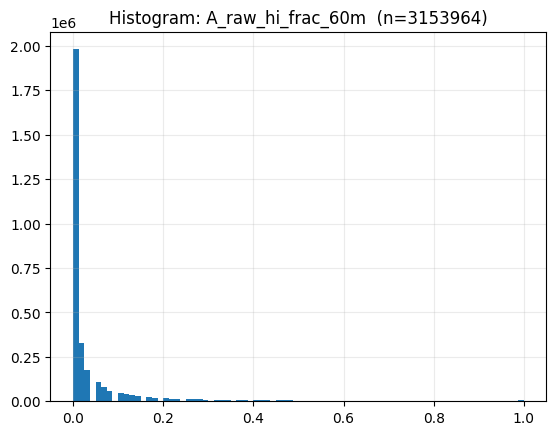

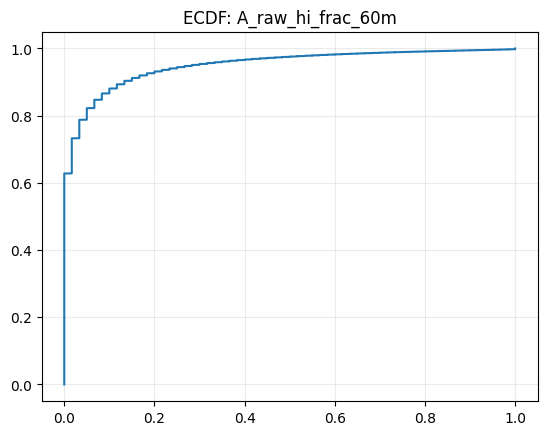

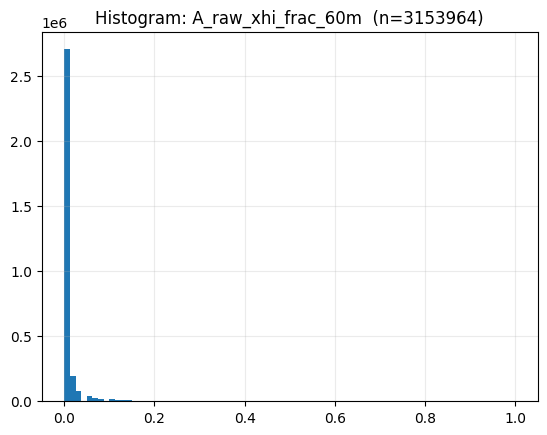

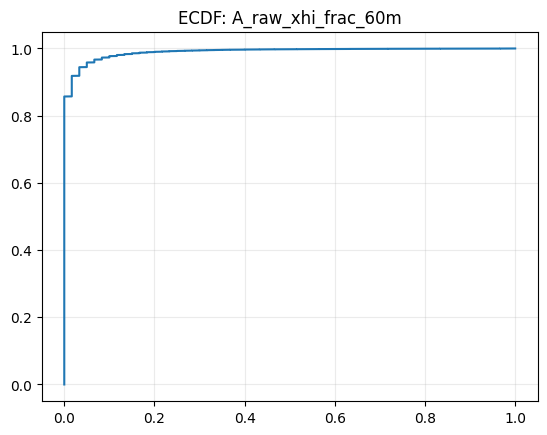

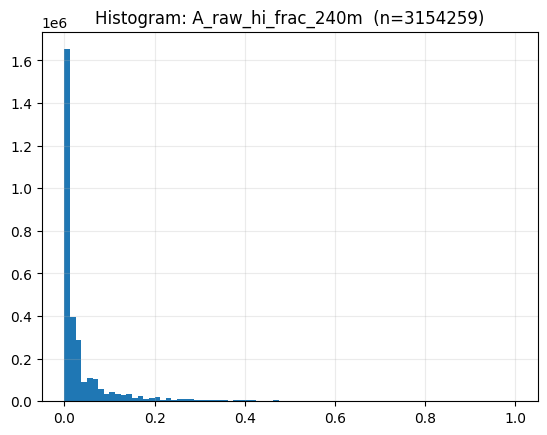

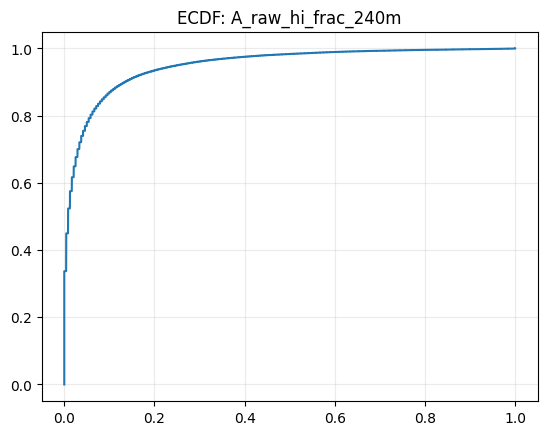

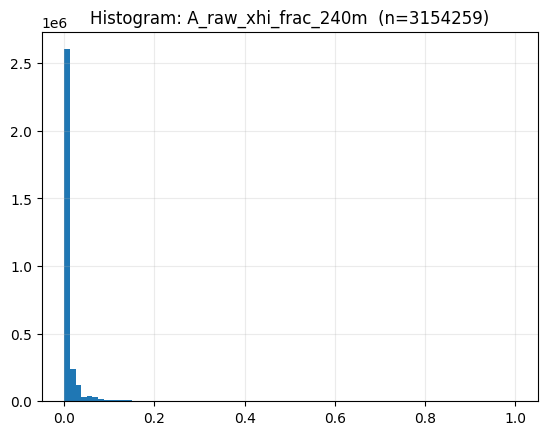

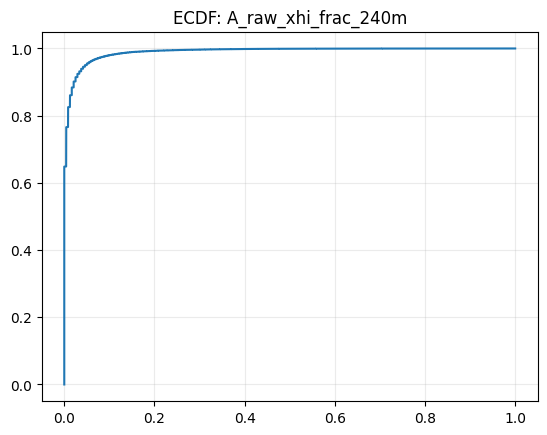

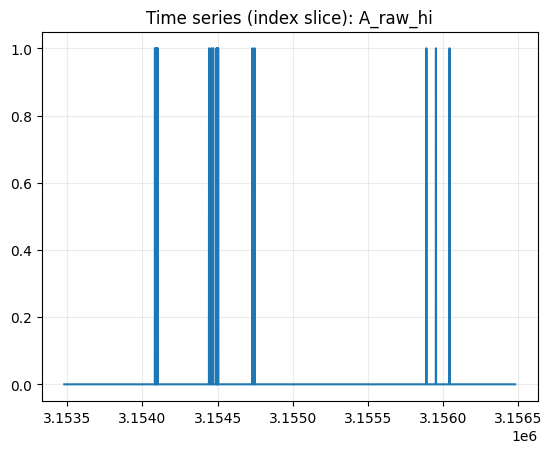

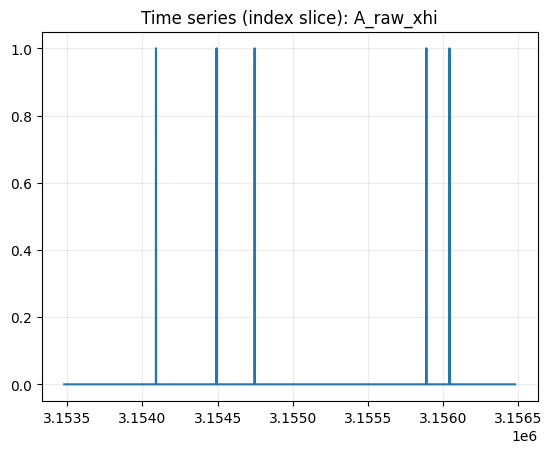

In [31]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map,plot_A=True, plot_C=True, plot_D=False)

In [33]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
A_raw_mean_60m,0.999687,0.998949,0.997876,0.994890,0.983545,0.904308,0.756349,0.520852
A_raw_p90_60m,0.998202,0.995520,0.992221,0.984343,0.959953,0.833575,0.624184,0.380234
A_raw_mean_240m,0.999969,0.999893,0.999780,0.999454,0.998145,0.987565,0.960530,0.716716
A_raw_p90_240m,0.999848,0.999597,0.999267,0.998404,0.995310,0.974461,0.930050,0.596798
A_raw_hi_frac_60m,0.999465,0.998404,0.996931,0.992959,0.978276,0.878555,0.695294,0.435058
A_raw_xhi_frac_60m,0.998995,0.997062,0.994446,0.987550,0.963119,0.807823,0.528730,0.225027
A_raw_hi_frac_240m,0.999947,0.999836,0.999677,0.999234,0.997503,0.983943,0.950051,0.652574
A_raw_xhi_frac_240m,0.999880,0.999639,0.999305,0.998403,0.995047,0.970800,0.913455,0.452289


In [34]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [35]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['A_raw_hi', 'A_raw_xhi']


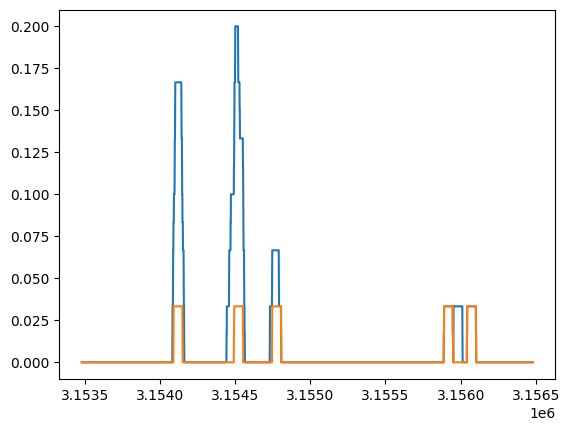

In [36]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G2_V_Volatility_raw

In [37]:
group_key = "G2_V_Volatility_raw"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [38]:
for abcd in ABCD_KEYS:
        if abcd not in REGISTRY[group_key]:
            continue
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
V_log_mean_60m,3156480,3153964,0.000797,0.0,0.000672,0.001281,0.000024,0.108611,0.000056,0.000081,0.000381,0.001986,0.004346
V_log_p90_60m,3156480,3153964,0.000797,0.0,0.001106,0.002682,0.000035,0.245165,0.000083,0.000123,0.000611,0.003283,0.007873
V_log_mean_240m,3156480,3154259,0.000704,0.0,0.000672,0.001077,0.000030,0.048825,0.000062,0.000090,0.000392,0.001952,0.004160
V_log_p90_240m,3156480,3154259,0.000704,0.0,0.001103,0.002199,0.000046,0.104022,0.000092,0.000137,0.000633,0.003224,0.007475



--- B_flag (1 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
V_log_hi,3156480,3153974,0.000794,0.95,0.05,2



--- C_frac (2 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
V_log_hi_frac_60m,3156480,3153964,0.000797,0.656934,0.049994,0.152060,0.0,1.0,0.0,0.0,0.000000,0.300000,0.916667
V_log_hi_frac_240m,3156480,3154259,0.000704,0.371221,0.049993,0.138677,0.0,1.0,0.0,0.0,0.004167,0.270833,0.829167


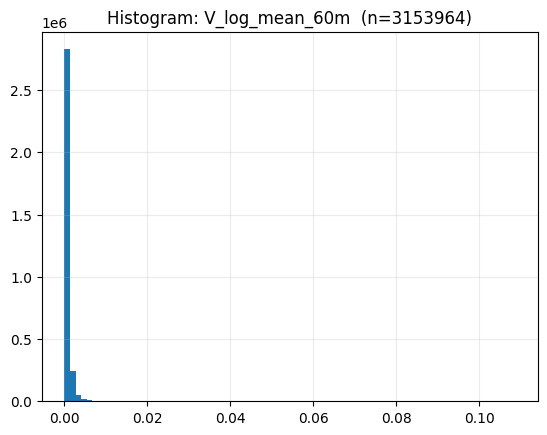

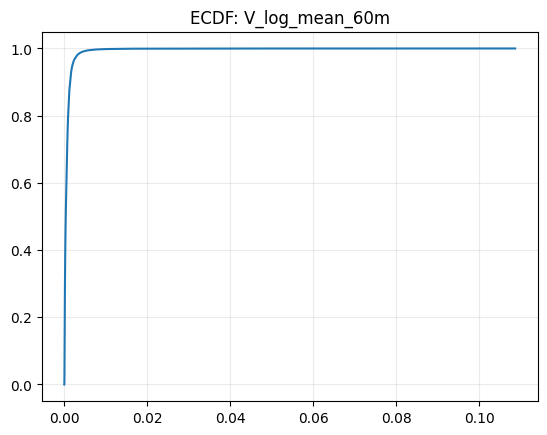

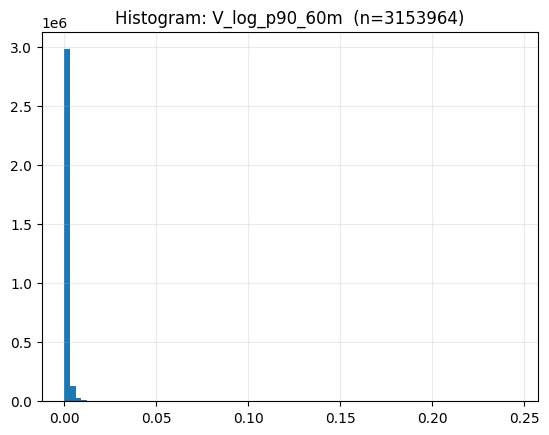

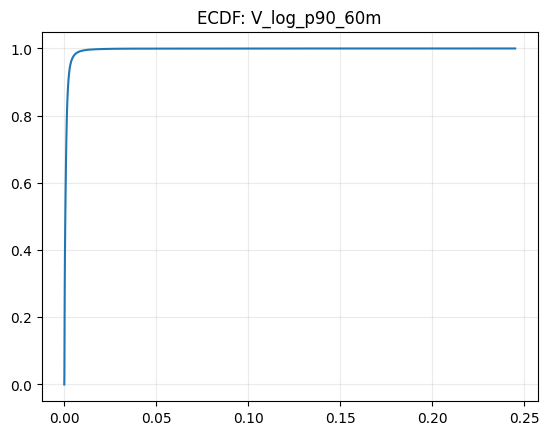

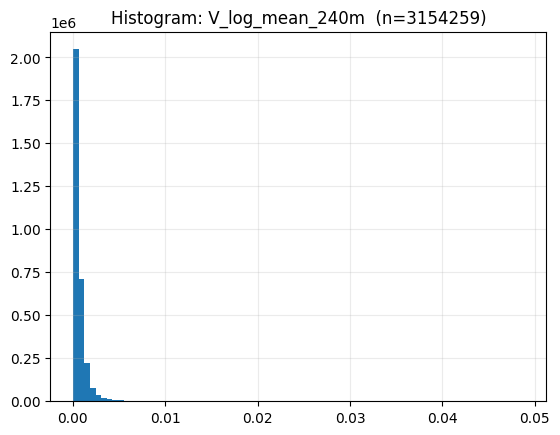

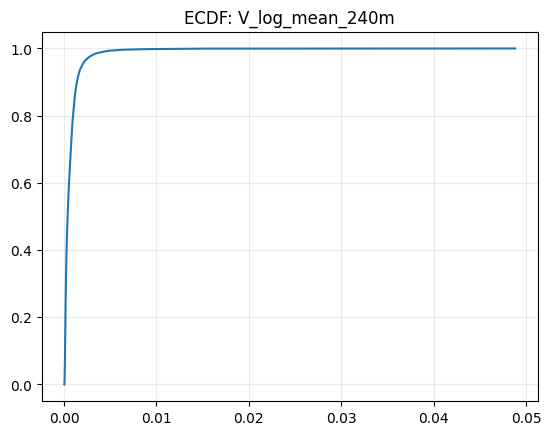

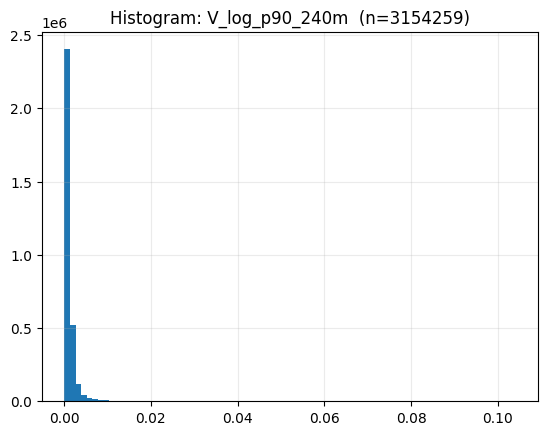

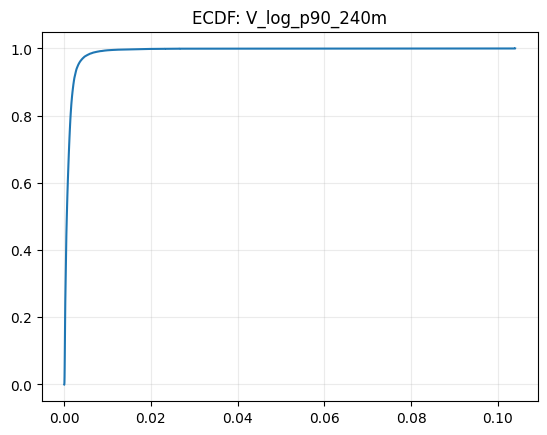

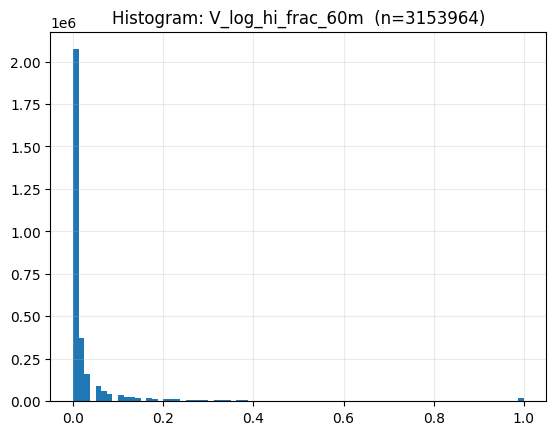

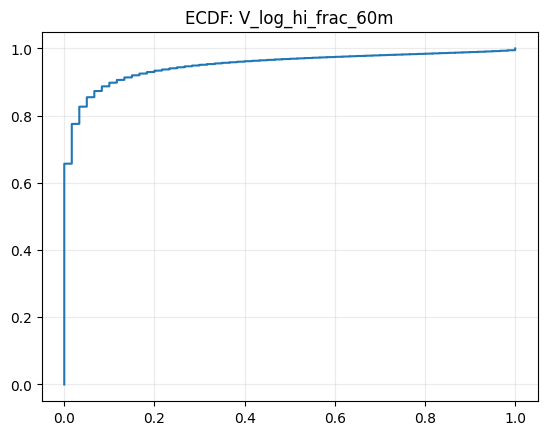

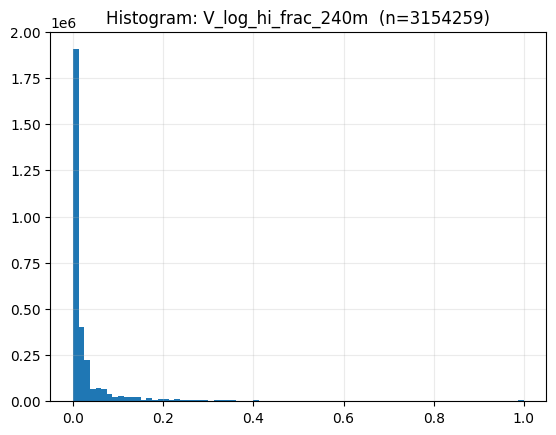

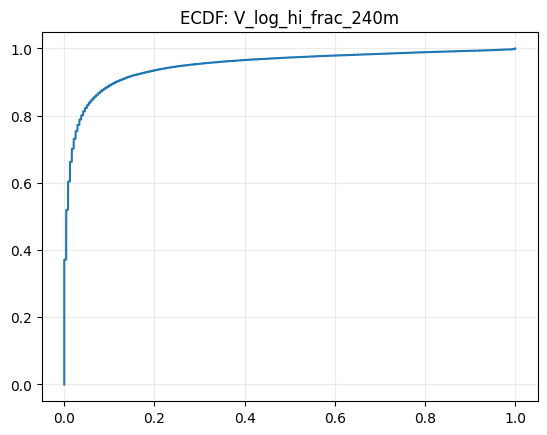

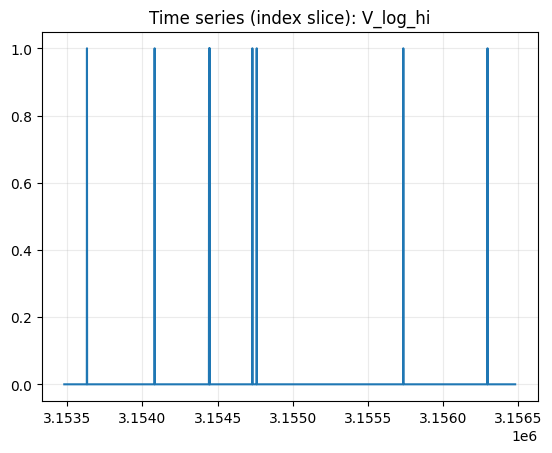

In [39]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map,plot_D=False)

In [40]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
V_log_mean_60m,0.999624,0.998715,0.997366,0.993550,0.978752,0.872784,0.680961,0.467506
V_log_p90_60m,0.997993,0.995102,0.991389,0.982295,0.953621,0.800581,0.531133,0.304542
V_log_mean_240m,0.999963,0.999870,0.999729,0.999325,0.997702,0.984728,0.952923,0.688639
V_log_p90_240m,0.999861,0.999616,0.999271,0.998310,0.994499,0.966621,0.911186,0.529068
V_log_hi_frac_60m,0.999657,0.999003,0.998112,0.995737,0.987124,0.929976,0.825963,0.666824
V_log_hi_frac_240m,0.999971,0.999913,0.999831,0.999604,0.998731,0.991960,0.974971,0.817818


In [41]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [42]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['V_log_hi']


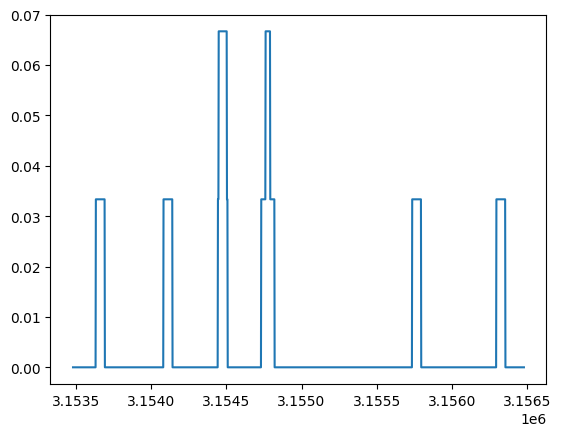

In [43]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G3_F_FlowStress_raw

In [44]:
group_key = "G3_F_FlowStress_raw"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [45]:
for abcd in ABCD_KEYS:
        if abcd not in REGISTRY[group_key]:
            continue
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
Fabs_log_mean_60m,3156480,2734841,0.133579,0.0,12.829207,0.466449,10.253572,15.541085,11.580810,12.061952,12.842213,13.585228,13.921424
Fabs_log_p90_60m,3156480,2734841,0.133579,0.0,14.194365,0.496485,11.708666,16.770188,12.922131,13.383037,14.197364,15.013311,15.413798
Fabs_log_mean_240m,3156480,2747971,0.129419,0.0,12.831464,0.420627,10.652365,14.393483,11.680782,12.148606,12.846478,13.525922,13.816648
Fabs_log_p90_240m,3156480,2747971,0.129419,0.0,14.189490,0.438270,12.142307,16.281281,13.039387,13.476955,14.201398,14.920756,15.257497



--- B_flag (1 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
Fabs_log_hi,3156480,2668868,0.15448,0.95,0.05,2



--- C_frac (2 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
Fabs_log_hi_frac_60m,3156480,2734841,0.133579,0.267678,0.050353,0.062079,0.0,0.95,0.0,0.0,0.033333,0.175439,0.283333
Fabs_log_hi_frac_240m,3156480,2747971,0.129419,0.077062,0.050536,0.052546,0.0,0.50,0.0,0.0,0.035874,0.161616,0.253165


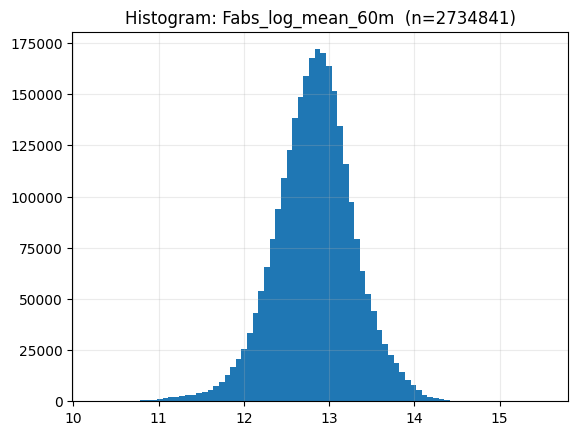

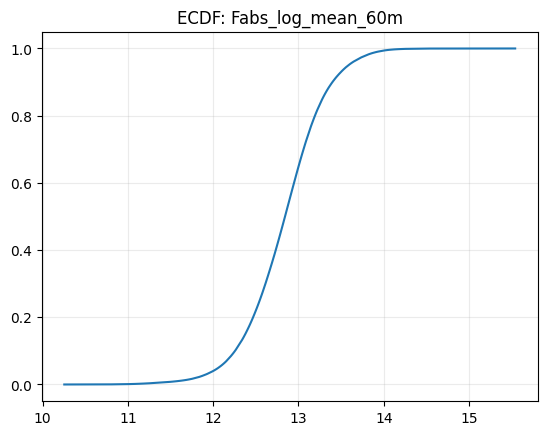

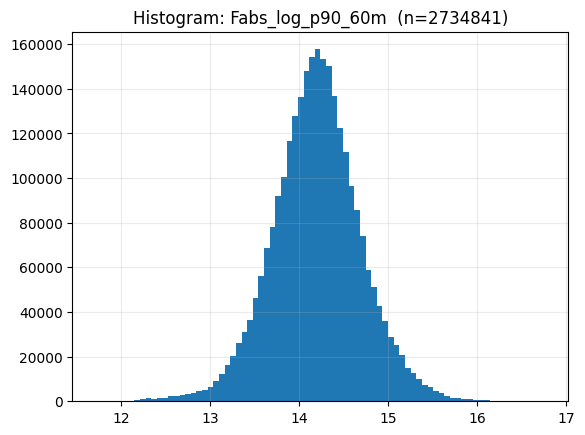

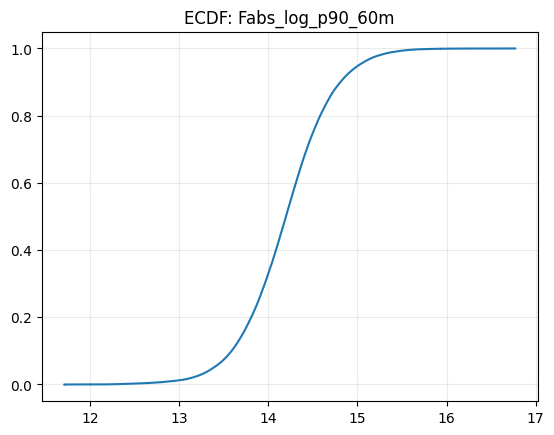

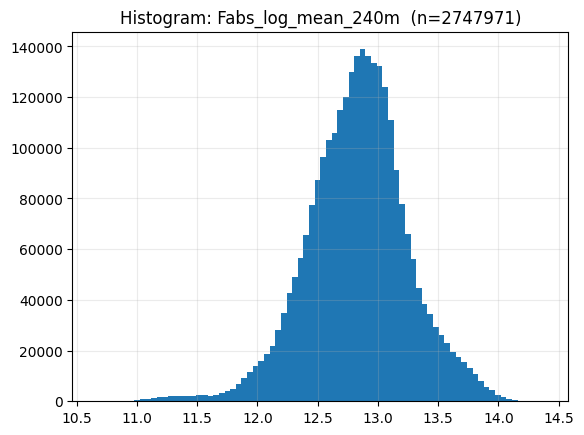

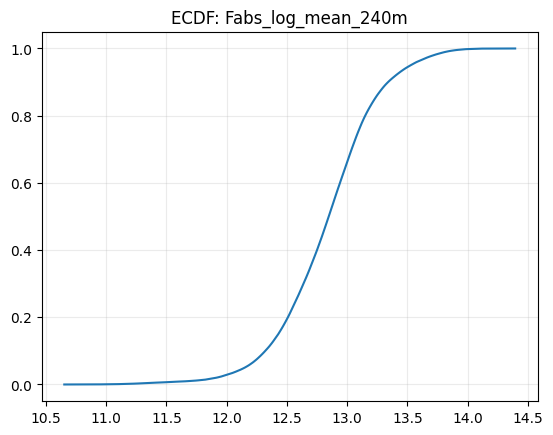

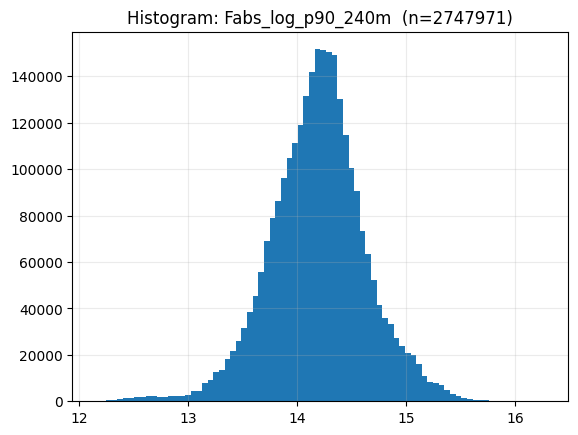

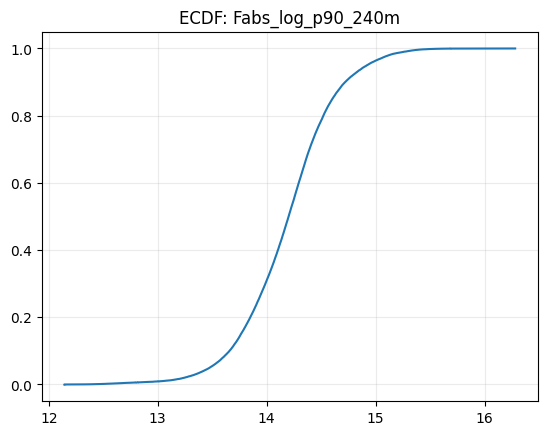

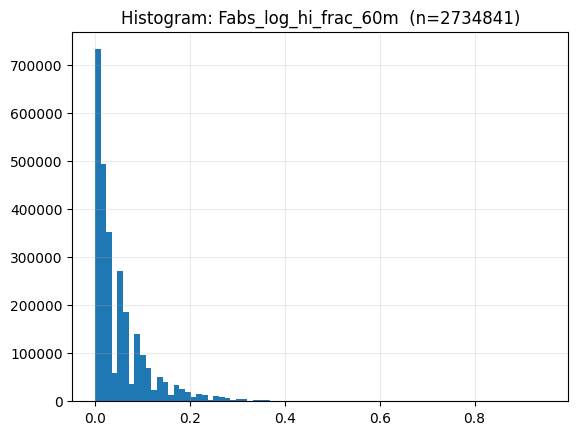

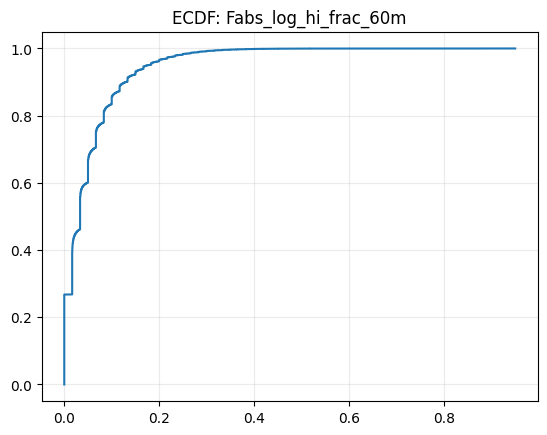

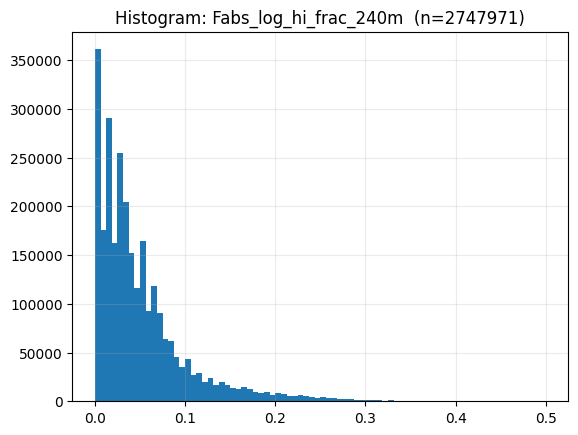

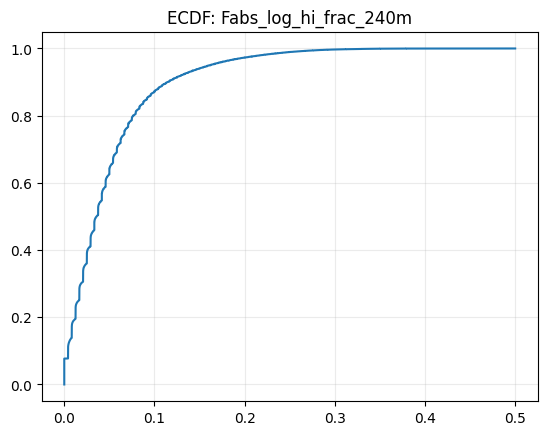

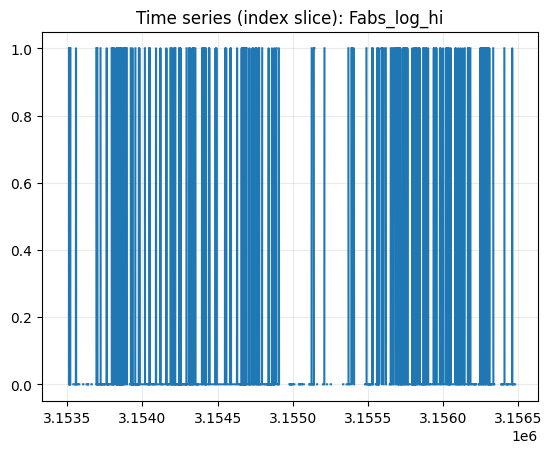

In [46]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map,plot_D=False)

In [47]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
Fabs_log_mean_60m,0.997879,0.995523,0.993008,0.987611,0.972505,0.898380,0.776199,0.697629
Fabs_log_p90_60m,0.994368,0.989083,0.984003,0.974180,0.950670,0.858024,0.726077,0.654829
Fabs_log_mean_240m,0.999834,0.999646,0.999443,0.999002,0.997725,0.990913,0.977386,0.867386
Fabs_log_p90_240m,0.999515,0.999049,0.998594,0.997700,0.995473,0.985704,0.968544,0.848801
Fabs_log_hi_frac_60m,0.996436,0.992437,0.988173,0.979045,0.953862,0.834842,0.645377,0.566055
Fabs_log_hi_frac_240m,0.999685,0.999327,0.998943,0.998114,0.995769,0.983915,0.961751,0.800976


In [48]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [49]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['Fabs_log_hi']


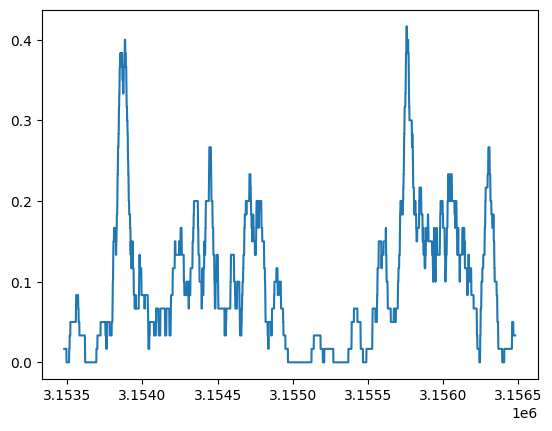

In [50]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G4_P_Persistence_raw

In [51]:
group_key = "G4_P_Persistence_raw"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [52]:
for abcd in ABCD_KEYS:
        if abcd not in REGISTRY[group_key]:
            continue
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
P_raw_mean_60m,3156480,3153944,0.000803,0.0,0.149331,0.088425,0.001818,0.622991,0.040235,0.059042,0.110965,0.325136,0.366059
P_raw_p90_60m,3156480,3153944,0.000803,0.0,0.239216,0.112914,0.004525,0.903260,0.087660,0.112791,0.198965,0.455405,0.543678
P_raw_mean_240m,3156480,3154229,0.000713,0.0,0.149317,0.086389,0.003073,0.423213,0.045580,0.064396,0.109699,0.322174,0.359929
P_raw_p90_240m,3156480,3154229,0.000713,0.0,0.237214,0.106006,0.006864,0.752548,0.098331,0.122074,0.196504,0.442316,0.513427



--- B_flag (2 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
P_raw_lo,3156480,3151751,0.001498,0.900004,0.099996,2
P_raw_hi,3156480,3151751,0.001498,0.900000,0.100000,2



--- C_frac (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
P_raw_hi_frac_60m,3156480,3153944,0.000803,0.451270,0.099977,0.180942,0.0,1.000000,0.0,0.0,0.016667,0.533333,0.816667
P_raw_lo_frac_60m,3156480,3153944,0.000803,0.344028,0.100065,0.136196,0.0,1.000000,0.0,0.0,0.050000,0.383333,0.600000
P_raw_hi_frac_240m,3156480,3154229,0.000713,0.204748,0.099949,0.173795,0.0,0.983333,0.0,0.0,0.016667,0.512500,0.762500
P_raw_lo_frac_240m,3156480,3154229,0.000713,0.202928,0.100062,0.125340,0.0,0.995833,0.0,0.0,0.054167,0.358333,0.558333



--- D_struct (10 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
runlen_P_raw_lo,3156480,3151751,0.001498,0.900004,0.190464,1.538081,0.0,188.000000,0.0,0.0,0.000000,1.000000,3.000000
runlen_P_raw_hi,3156480,3151751,0.001498,0.900000,0.317693,2.254934,0.0,158.000000,0.0,0.0,0.000000,1.000000,6.000000
maxrun_runlen_P_raw_hi_60m,3156480,3153944,0.000803,0.451270,1.790531,4.506359,0.0,158.000000,0.0,0.0,1.000000,7.000000,19.000000
maxrun_runlen_P_raw_lo_60m,3156480,3153944,0.000803,0.344028,1.540813,2.875320,0.0,188.000000,0.0,0.0,1.000000,5.000000,9.000000
maxrun_runlen_P_raw_hi_240m,3156480,3154229,0.000713,0.204748,3.056978,6.711357,0.0,158.000000,0.0,0.0,1.000000,11.000000,33.000000
maxrun_runlen_P_raw_lo_240m,3156480,3154229,0.000713,0.202928,2.443059,4.047100,0.0,188.000000,0.0,0.0,2.000000,7.000000,12.000000
P_raw_hi_flip_rate_240m,3156480,3156361,0.000038,0.204243,0.107979,0.147500,0.0,0.600000,0.0,0.0,0.033333,0.433333,0.487500
P_raw_lo_flip_rate_240m,3156480,3156361,0.000038,0.202585,0.136152,0.137198,0.0,0.575000,0.0,0.0,0.091667,0.408333,0.475000
P_raw_hi_flip_rate_60m,3156480,3156451,0.000009,0.449150,0.107990,0.155918,0.0,0.733333,0.0,0.0,0.033333,0.450000,0.533333


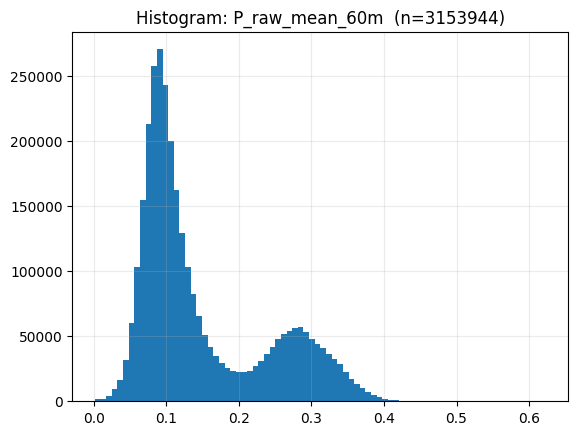

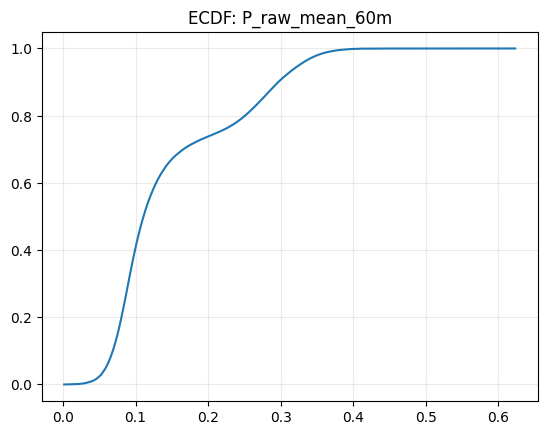

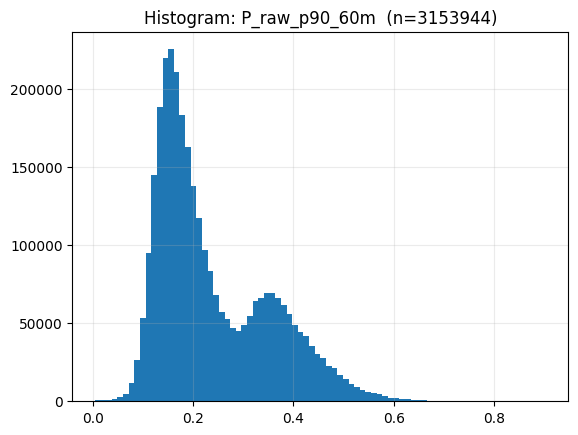

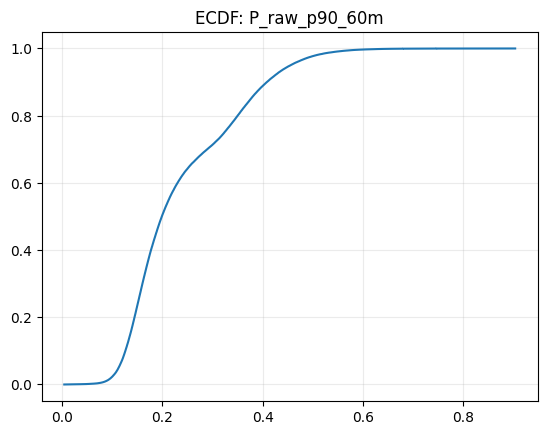

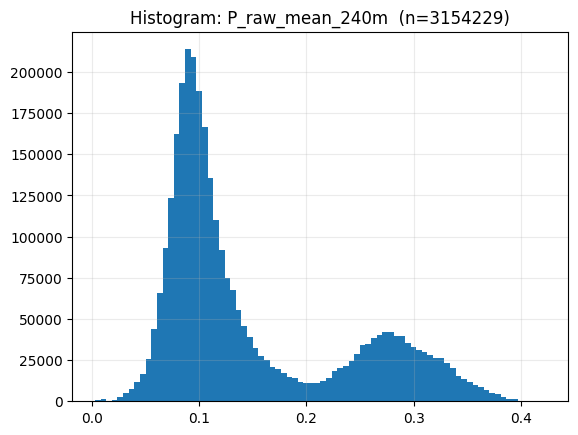

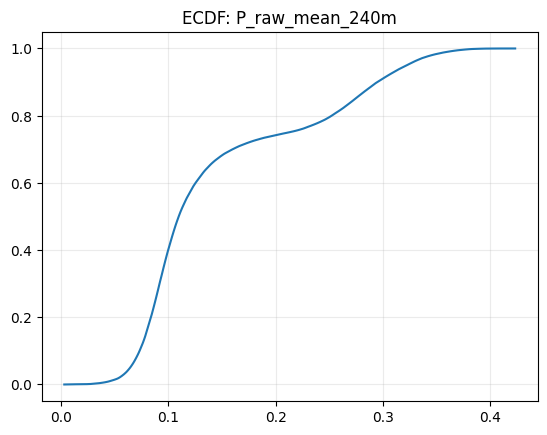

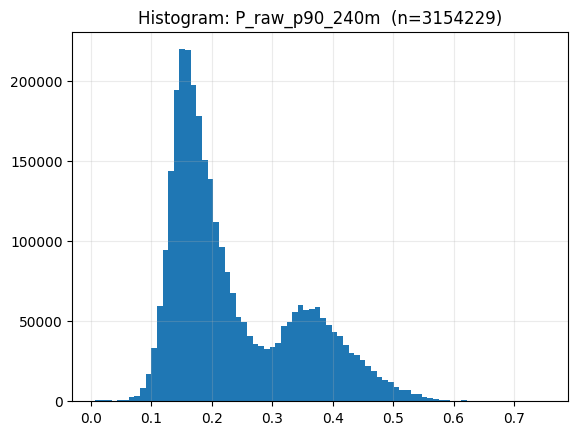

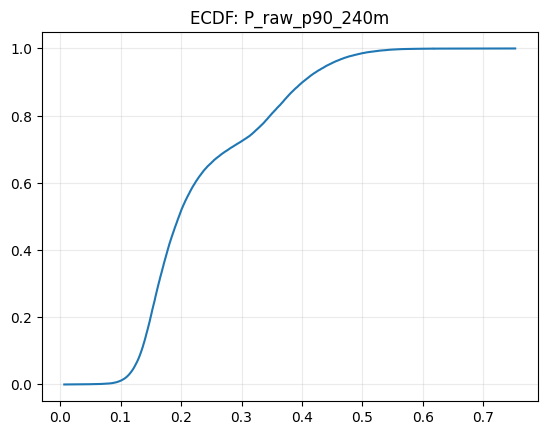

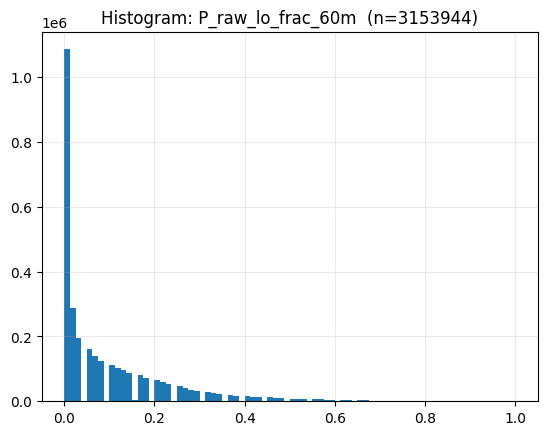

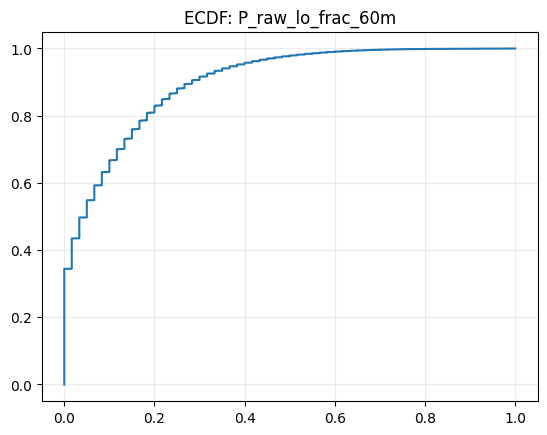

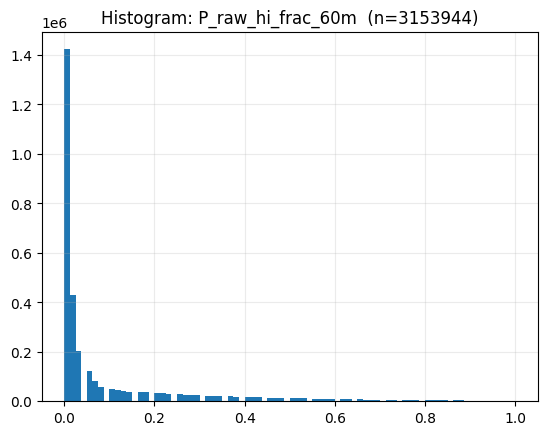

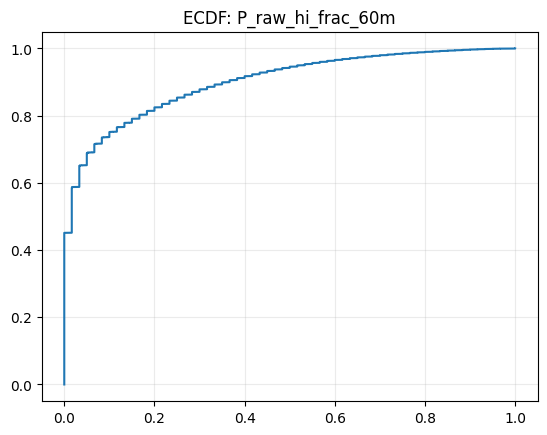

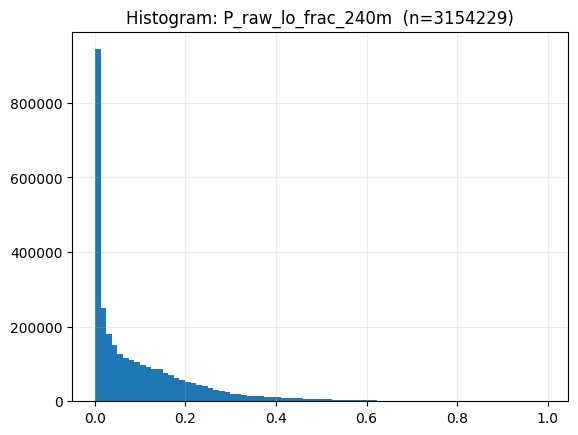

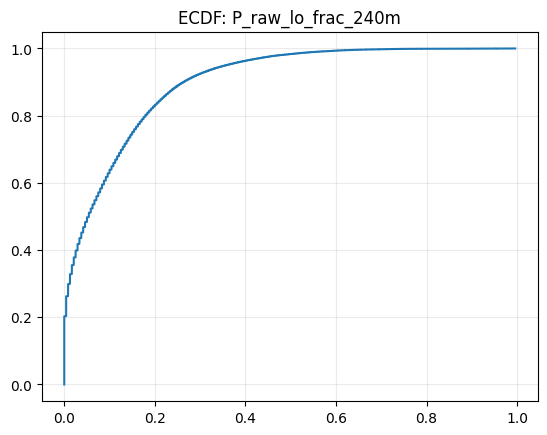

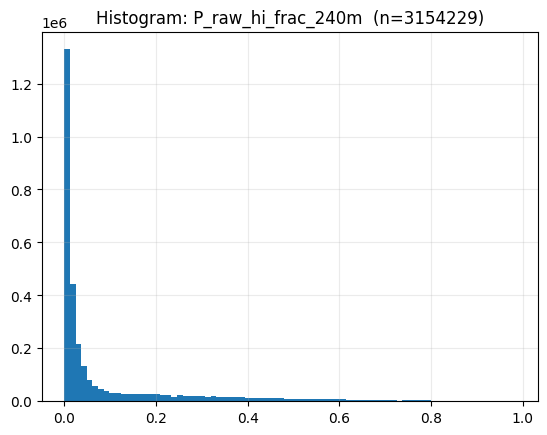

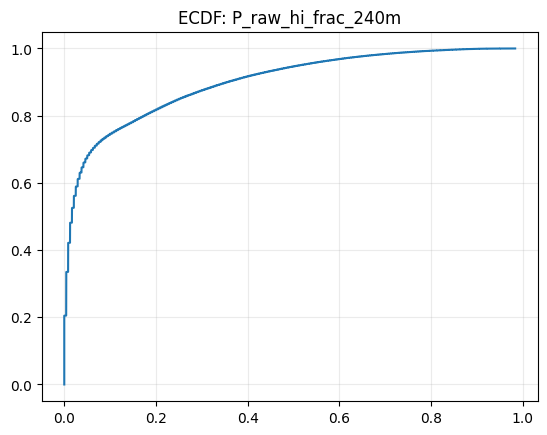

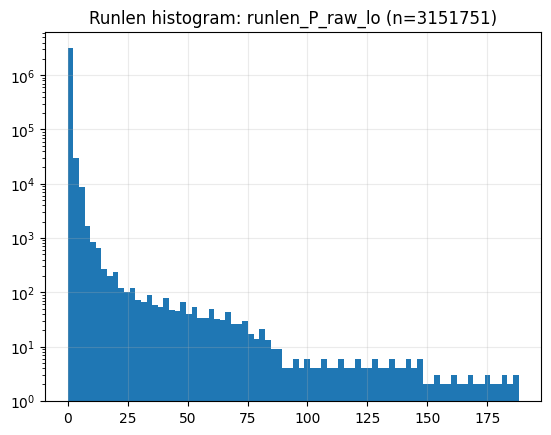

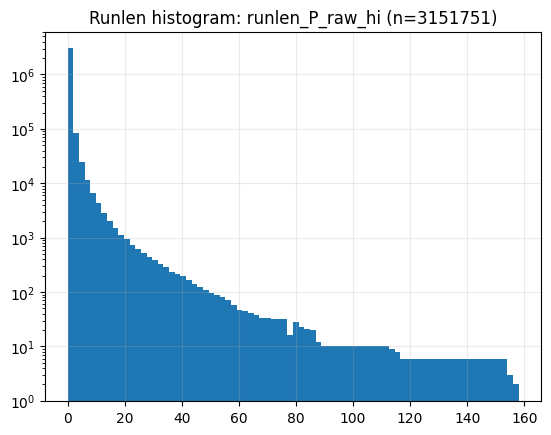

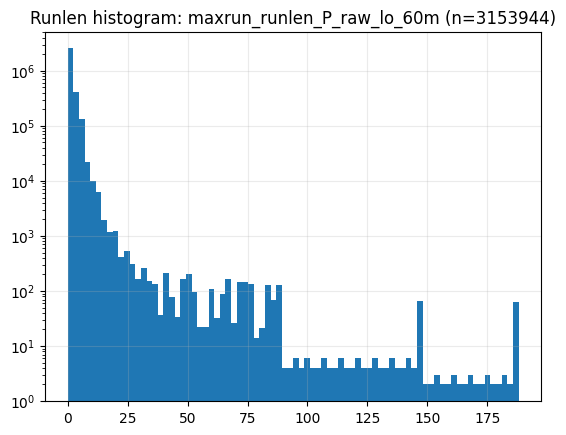

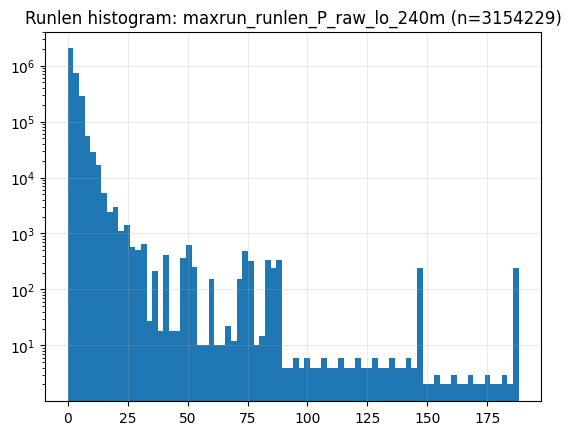

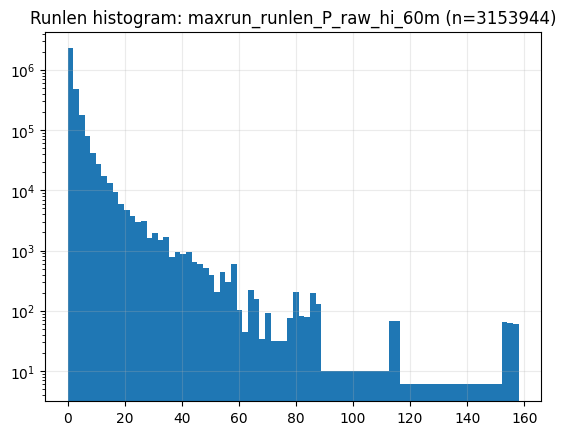

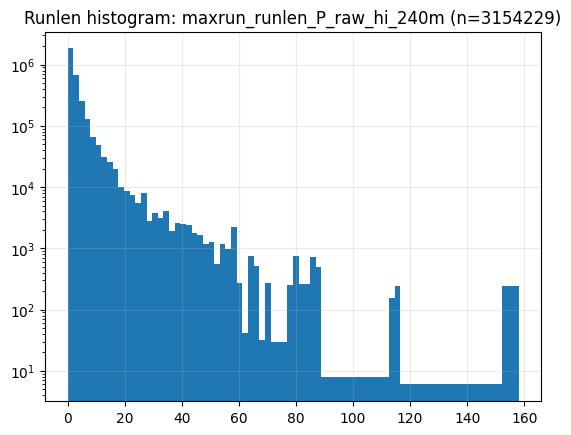

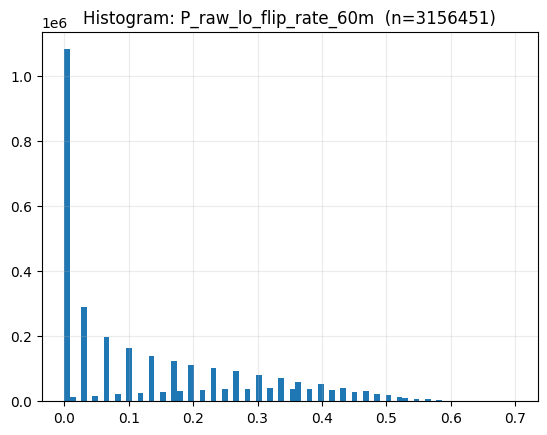

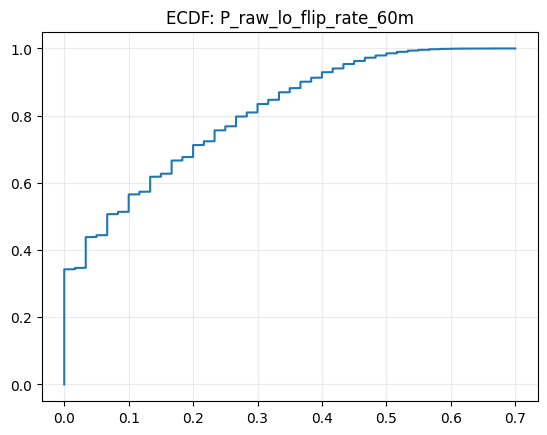

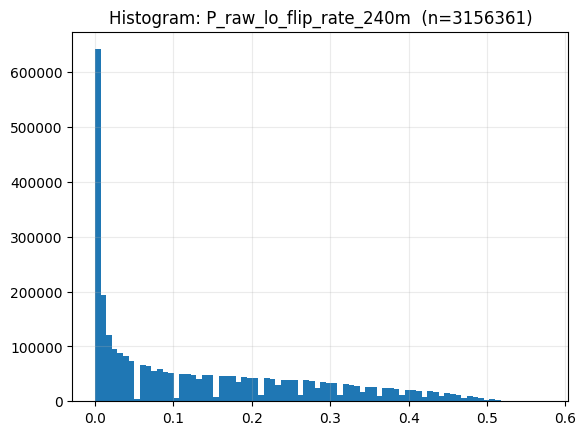

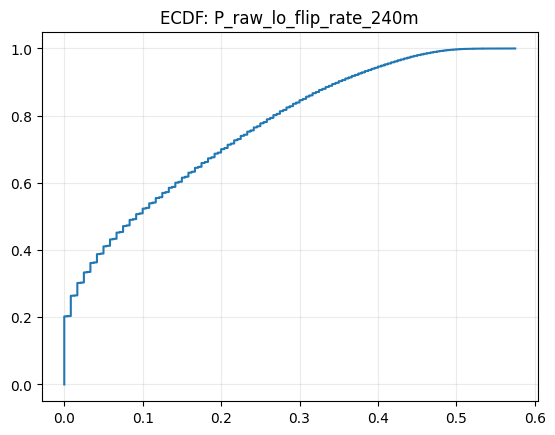

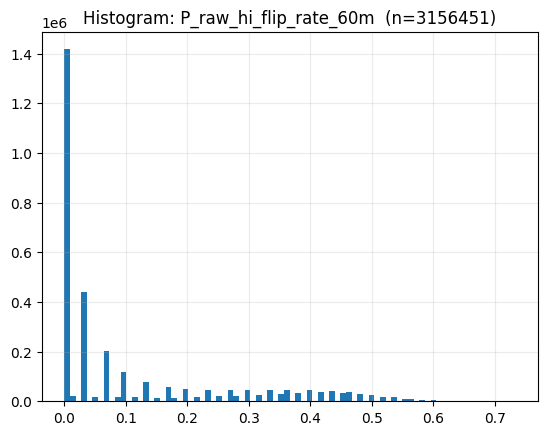

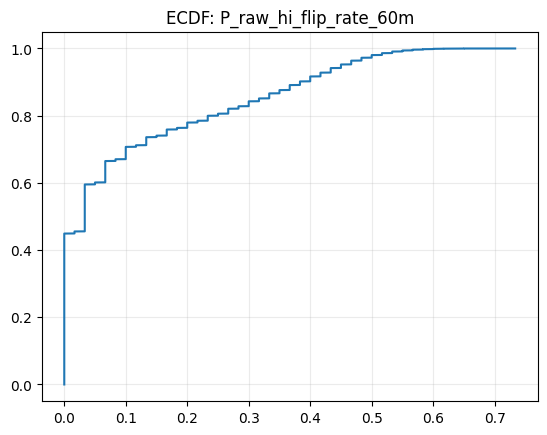

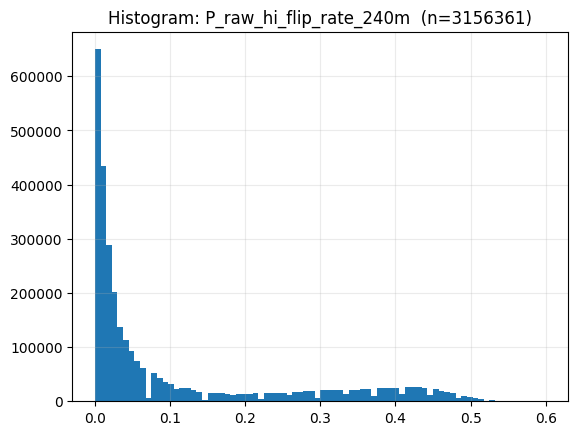

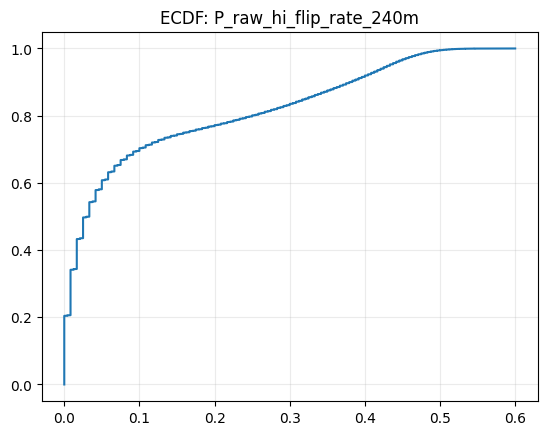

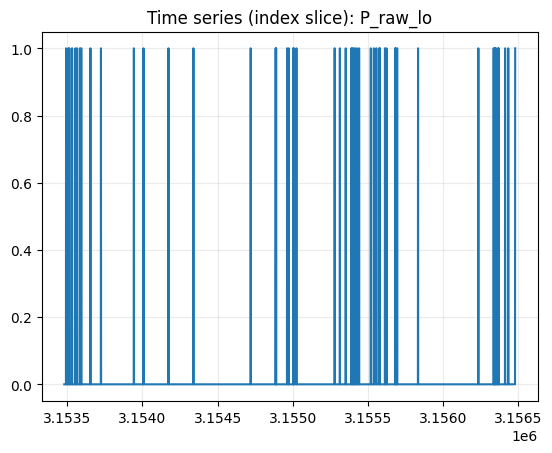

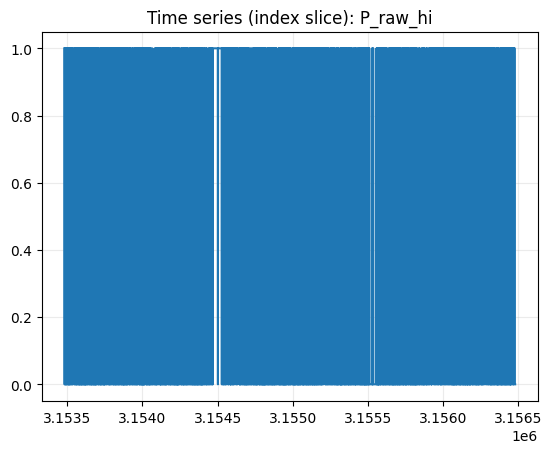

In [53]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map)

In [54]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
P_raw_mean_60m,0.999805,0.999536,0.999211,0.998423,0.995809,0.979791,0.951264,0.914365
P_raw_p90_60m,0.998374,0.996685,0.994949,0.991358,0.981767,0.937848,0.870852,0.809826
P_raw_mean_240m,0.999987,0.999967,0.999943,0.999882,0.999665,0.998121,0.994394,0.961343
P_raw_p90_240m,0.999879,0.999749,0.999611,0.999312,0.998436,0.993416,0.983047,0.907447
P_raw_lo_frac_60m,0.998882,0.997575,0.996120,0.992849,0.982957,0.927989,0.832555,0.713903
P_raw_hi_frac_60m,0.999493,0.998888,0.998203,0.996632,0.991782,0.964358,0.916153,0.850910
P_raw_lo_frac_240m,0.999915,0.999812,0.999693,0.999416,0.998518,0.992636,0.978888,0.855693
P_raw_hi_frac_240m,0.999964,0.999920,0.999868,0.999743,0.999329,0.996548,0.989904,0.925827
runlen_P_raw_lo,0.919550,0.880019,0.853779,0.816913,0.750944,0.581194,0.462096,0.330443


In [55]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [56]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['P_raw_lo', 'P_raw_hi']


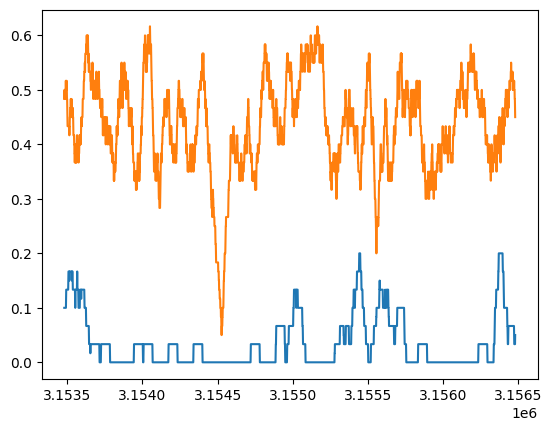

In [57]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G5_C_Concentration_raw

In [58]:
group_key = "G5_C_Concentration_raw"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [59]:
for abcd in ABCD_KEYS:
        if abcd not in REGISTRY[group_key]:
            continue
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
C_raw_mean_60m,3156480,3130715,0.008163,0.0,0.295016,0.078028,0.115107,0.623359,0.175050,0.194111,0.278549,0.433168,0.479053
C_raw_p90_60m,3156480,3130715,0.008163,0.0,0.426712,0.113820,0.166449,0.920351,0.239242,0.270638,0.411744,0.625349,0.704947
C_raw_mean_240m,3156480,3137014,0.006167,0.0,0.294895,0.075163,0.140741,0.570998,0.182028,0.198631,0.277005,0.426674,0.466358
C_raw_p90_240m,3156480,3137014,0.006167,0.0,0.424433,0.106542,0.203013,0.847805,0.253361,0.279896,0.409972,0.606010,0.674480



--- B_flag (2 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
C_raw_xhi,3156480,3093724,0.019882,0.99,0.01,2
C_raw_hi,3156480,3093724,0.019882,0.95,0.05,2



--- C_frac (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
C_raw_xhi_frac_60m,3156480,3130715,0.008163,0.743113,0.010005,0.024126,0.0,0.433333,0.0,0.0,0.000000,0.050847,0.116667
C_raw_hi_frac_60m,3156480,3130715,0.008163,0.413980,0.049916,0.075262,0.0,0.816667,0.0,0.0,0.016667,0.210526,0.333333
C_raw_xhi_frac_240m,3156480,3137014,0.006167,0.528779,0.009983,0.019969,0.0,0.227848,0.0,0.0,0.000000,0.050000,0.097458
C_raw_hi_frac_240m,3156480,3137014,0.006167,0.190674,0.049828,0.067486,0.0,0.658333,0.0,0.0,0.020833,0.191667,0.287500



--- D_struct (10 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
runlen_C_raw_xhi,3156480,3093724,0.019882,0.990000,0.010873,0.113499,0.0,9.000000,0.0,0.0,0.000000,0.000000,0.000000
runlen_C_raw_hi,3156480,3093724,0.019882,0.950000,0.063347,0.323685,0.0,32.000000,0.0,0.0,0.000000,0.000000,1.000000
maxrun_runlen_C_raw_xhi_60m,3156480,3130715,0.008163,0.743113,0.292448,0.541776,0.0,9.000000,0.0,0.0,0.000000,1.000000,2.000000
maxrun_runlen_C_raw_hi_60m,3156480,3130715,0.008163,0.413980,0.897657,1.057687,0.0,32.000000,0.0,0.0,1.000000,3.000000,4.000000
maxrun_runlen_C_raw_xhi_240m,3156480,3137014,0.006167,0.528779,0.576293,0.714318,0.0,9.000000,0.0,0.0,0.000000,2.000000,3.000000
maxrun_runlen_C_raw_hi_240m,3156480,3137014,0.006167,0.190674,1.473628,1.344864,0.0,32.000000,0.0,0.0,1.000000,4.000000,6.000000
C_raw_xhi_flip_rate_240m,3156480,3156361,0.000038,0.530595,0.017914,0.034148,0.0,0.375000,0.0,0.0,0.000000,0.091667,0.162500
C_raw_hi_flip_rate_240m,3156480,3156361,0.000038,0.190605,0.079287,0.096570,0.0,0.562500,0.0,0.0,0.033333,0.287500,0.375000
C_raw_xhi_flip_rate_60m,3156480,3156451,0.000009,0.743127,0.017914,0.041179,0.0,0.533333,0.0,0.0,0.000000,0.100000,0.200000


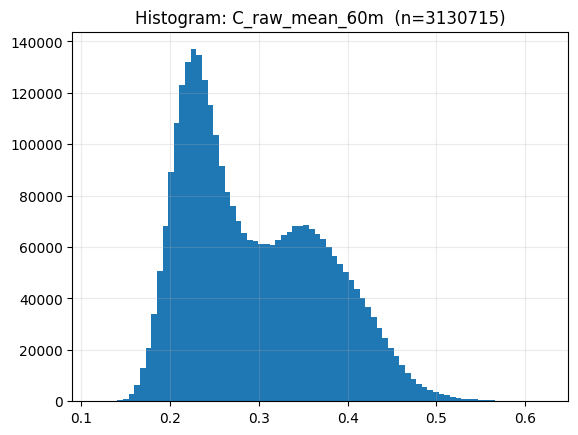

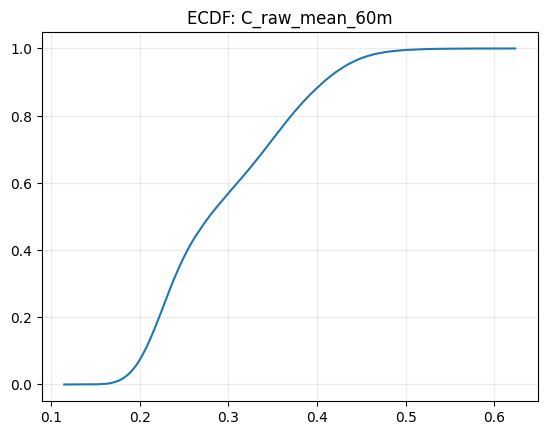

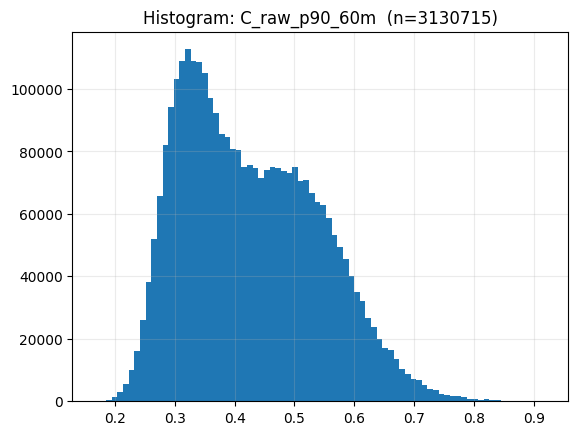

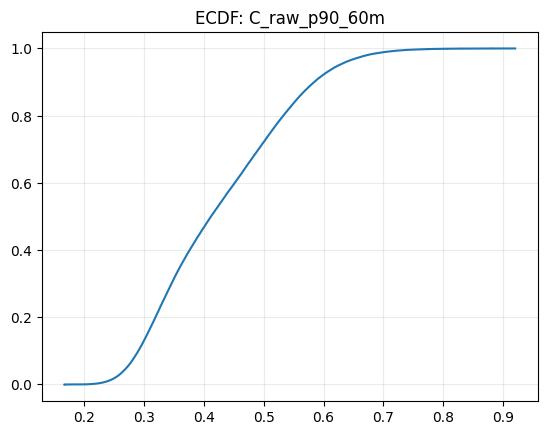

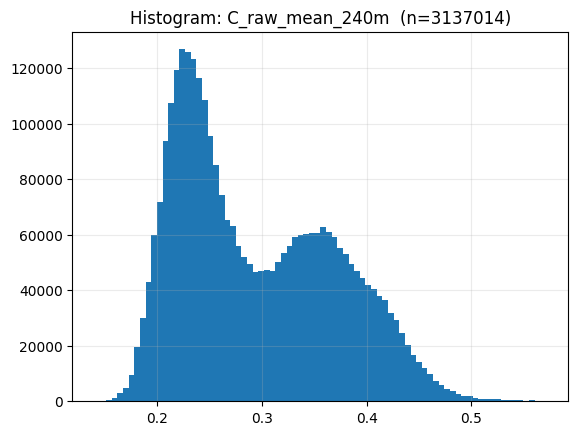

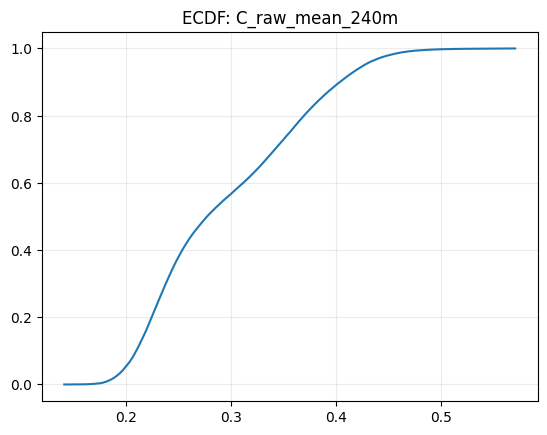

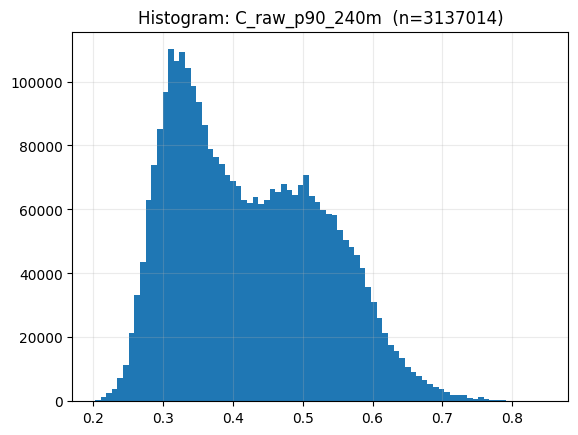

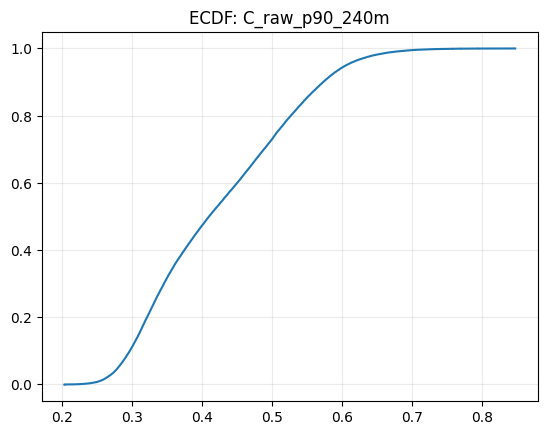

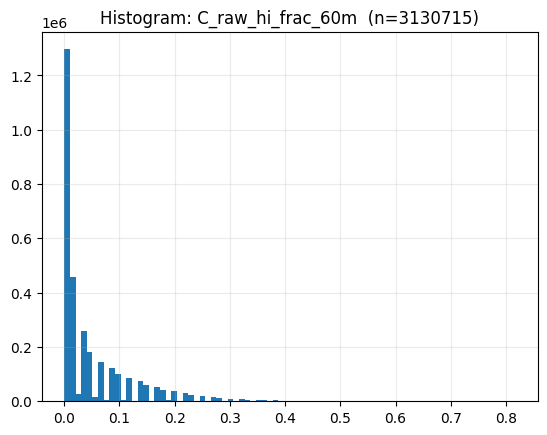

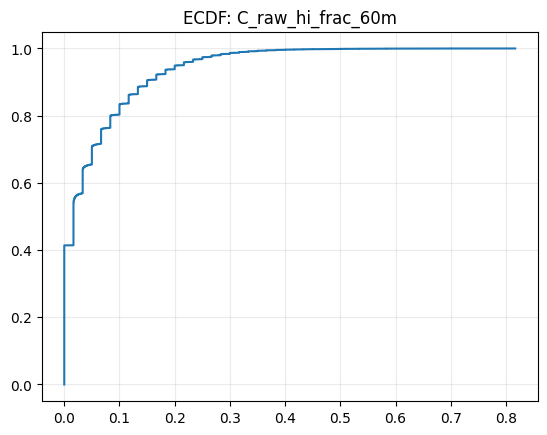

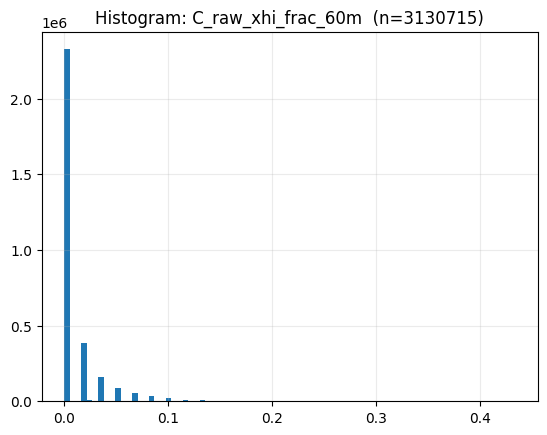

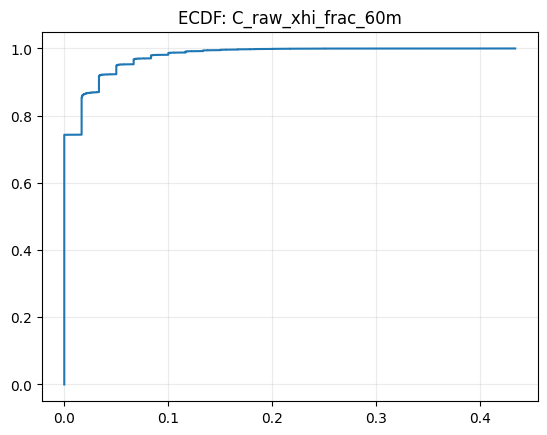

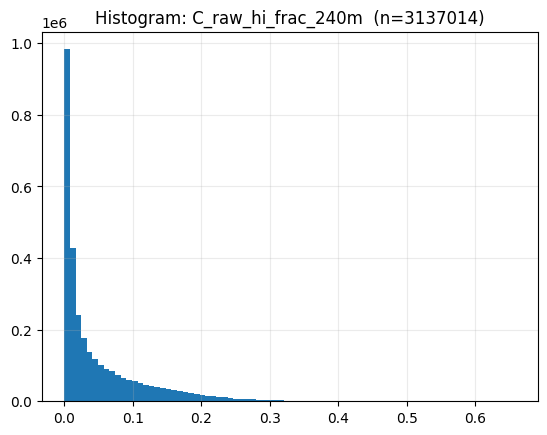

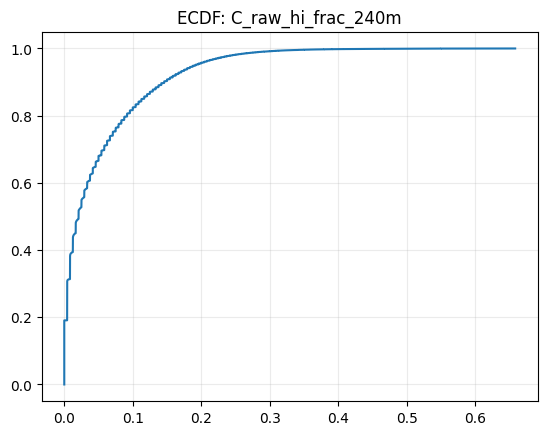

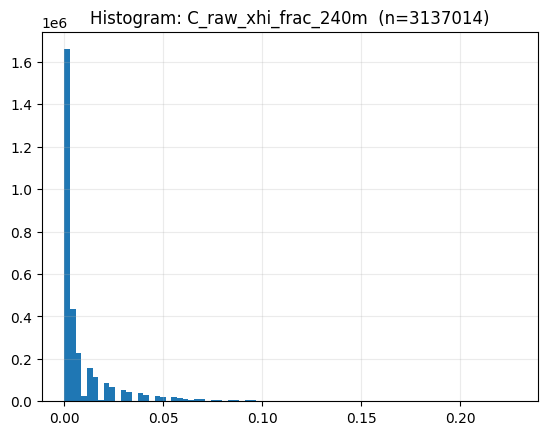

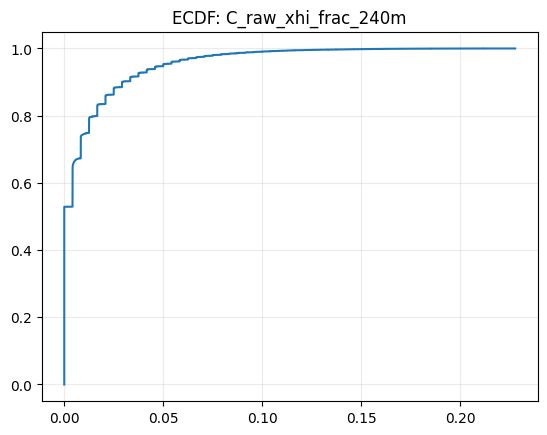

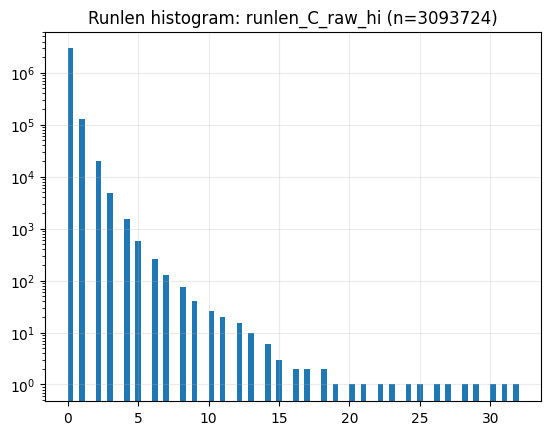

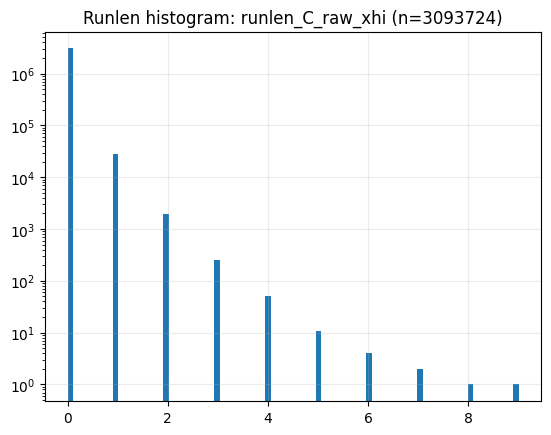

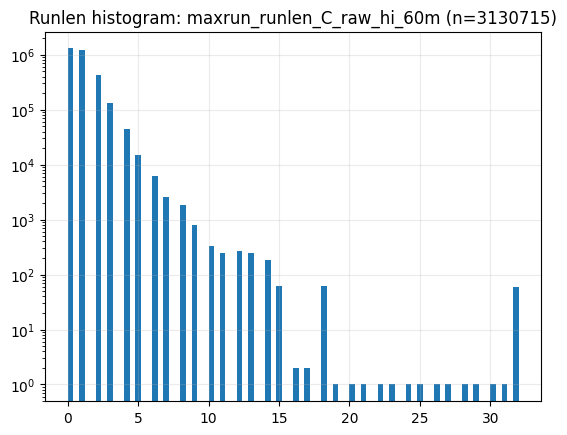

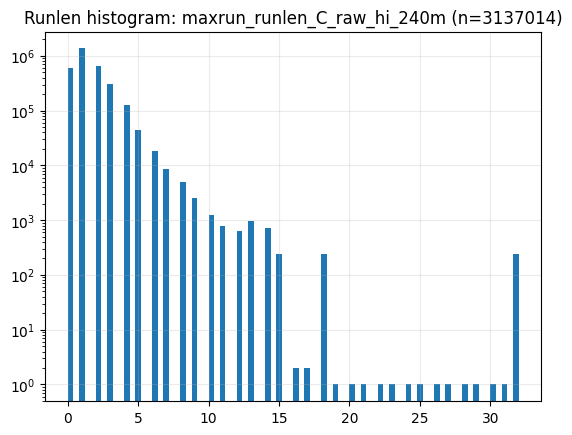

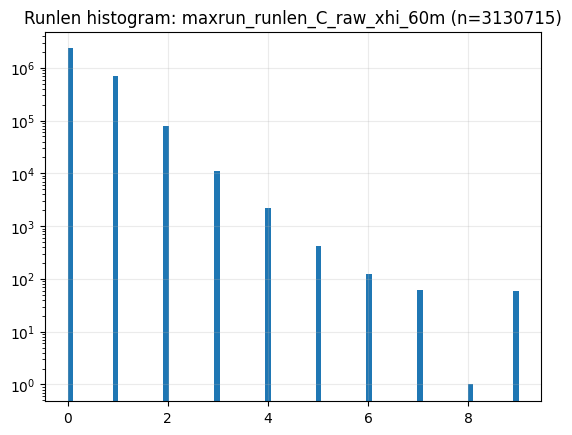

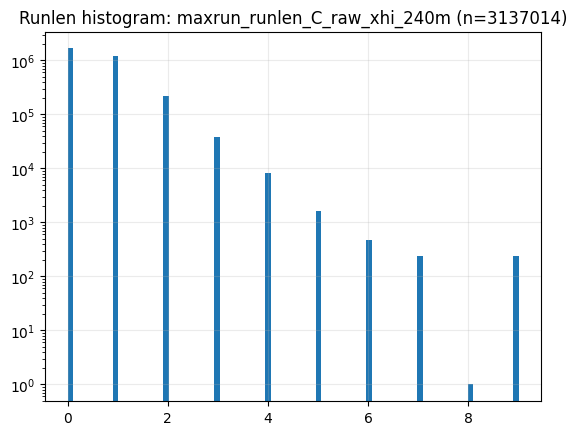

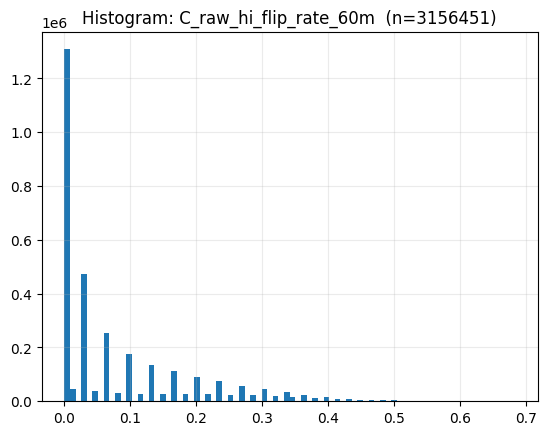

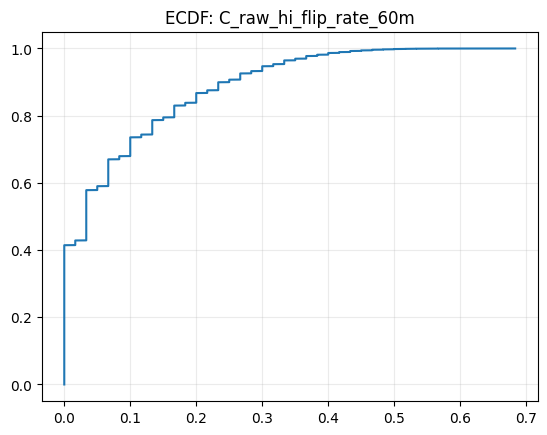

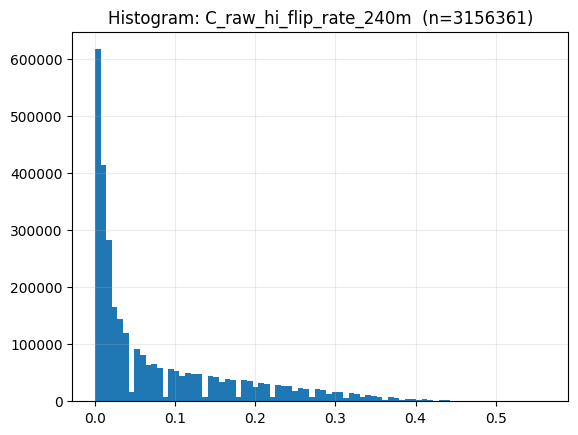

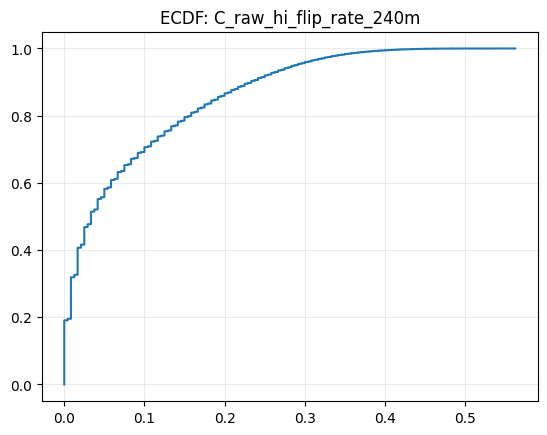

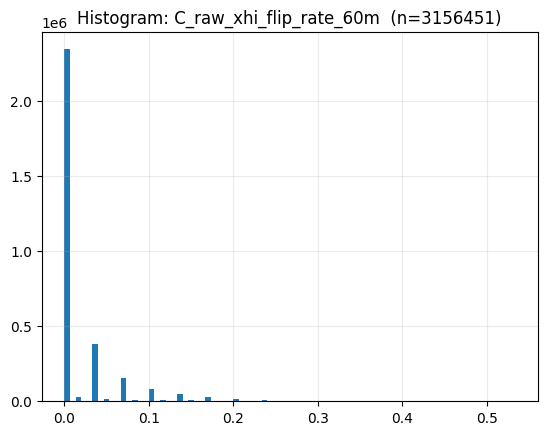

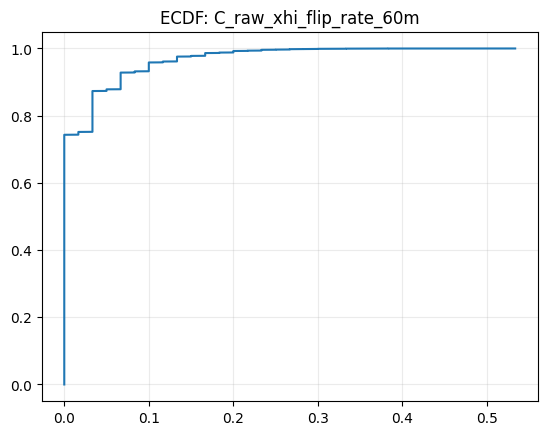

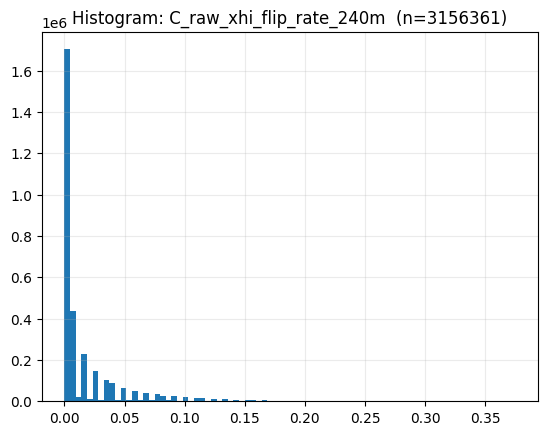

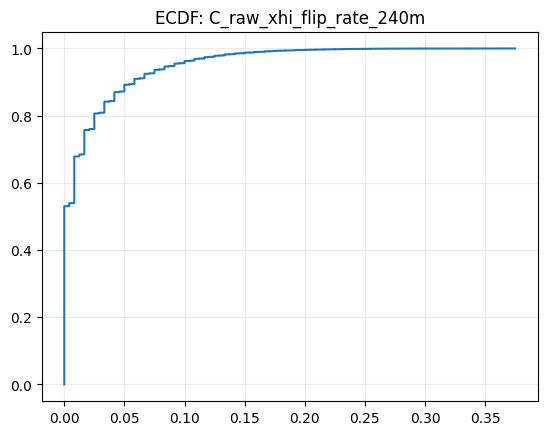

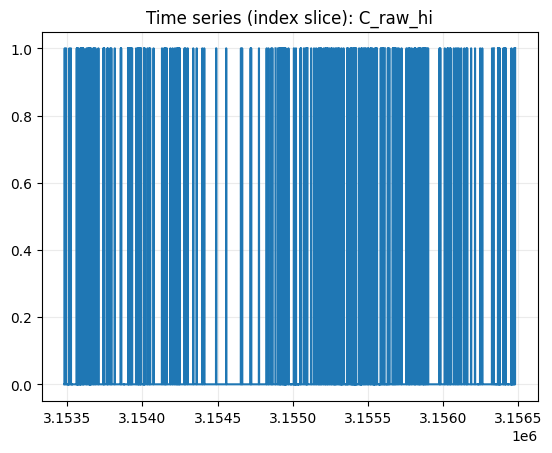

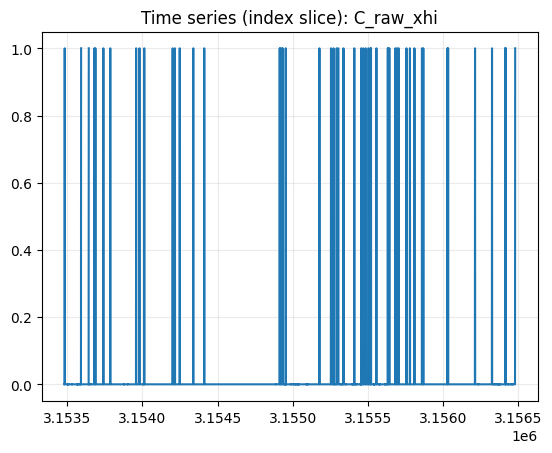

In [60]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map)

In [61]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
C_raw_mean_60m,0.999541,0.998978,0.998338,0.996872,0.992346,0.966918,0.922518,0.867604
C_raw_p90_60m,0.997359,0.994848,0.992413,0.987655,0.975993,0.927766,0.856471,0.784974
C_raw_mean_240m,0.999968,0.999927,0.999879,0.999765,0.999388,0.996895,0.991072,0.938732
C_raw_p90_240m,0.999795,0.999598,0.999402,0.999008,0.997977,0.992921,0.982960,0.903211
C_raw_hi_frac_60m,0.997857,0.995500,0.992989,0.987601,0.972485,0.898343,0.775242,0.665556
C_raw_xhi_frac_60m,0.995363,0.990462,0.985361,0.974745,0.946492,0.820774,0.620935,0.502848
C_raw_hi_frac_240m,0.999831,0.999642,0.999436,0.998983,0.997641,0.990080,0.974036,0.835184
C_raw_xhi_frac_240m,0.999576,0.999123,0.998646,0.997640,0.994872,0.981149,0.954770,0.741353
runlen_C_raw_hi,0.396765,0.261564,0.214522,0.179147,0.149106,0.113875,0.104412,0.088899


In [62]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [63]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['C_raw_hi', 'C_raw_xhi']


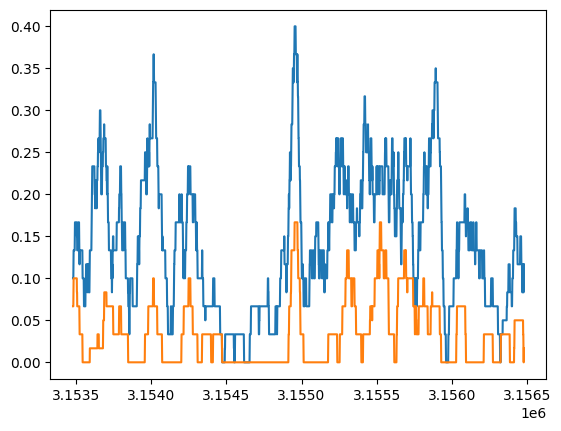

In [64]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G6_I_Impact_raw

In [65]:
group_key = "G6_I_Impact_raw"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [66]:
for abcd in ABCD_KEYS:
        if abcd not in REGISTRY[group_key]:
            continue
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
I_raw_mean_60m,3156480,3154116,0.000749,0.0,0.000016,0.000008,5.518294e-07,0.000132,0.000004,0.000006,0.000014,0.000032,0.000043
I_raw_p90_60m,3156480,3154116,0.000749,0.0,0.000040,0.000023,1.794843e-06,0.000402,0.000009,0.000014,0.000035,0.000084,0.000122
I_raw_mean_240m,3156480,3154478,0.000634,0.0,0.000016,0.000007,9.239858e-07,0.000068,0.000005,0.000007,0.000015,0.000029,0.000038
I_raw_p90_240m,3156480,3154478,0.000634,0.0,0.000037,0.000017,2.571389e-06,0.000204,0.000011,0.000016,0.000034,0.000070,0.000091



--- B_flag (1 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
I_raw_event,3156480,3154130,0.000745,0.995,0.005,2



--- C_frac (2 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
I_raw_event_frac_60m,3156480,3154116,0.000749,0.792242,0.005000,0.011571,0.0,0.166667,0.0,0.0,0.000000,0.033333,0.050000
I_raw_event_frac_240m,3156480,3154478,0.000634,0.498963,0.005001,0.007535,0.0,0.100000,0.0,0.0,0.004167,0.020833,0.033333


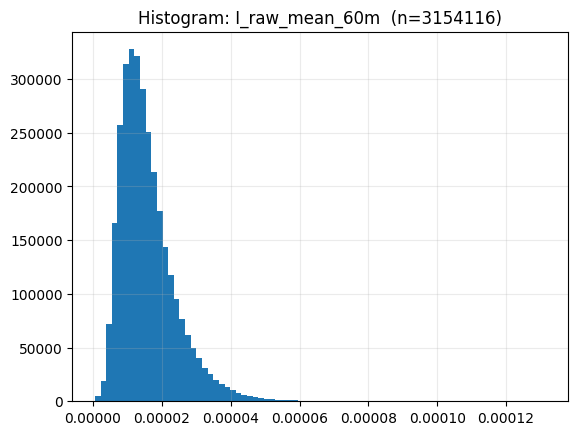

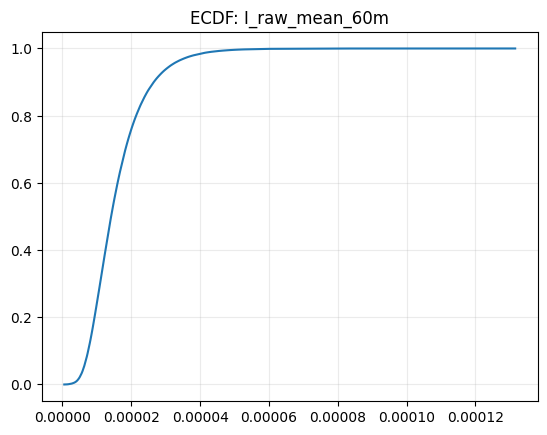

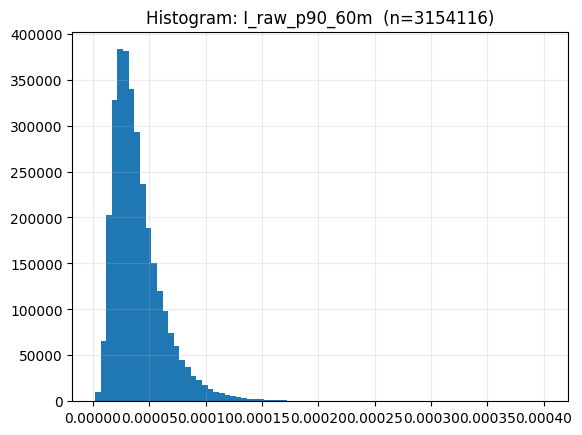

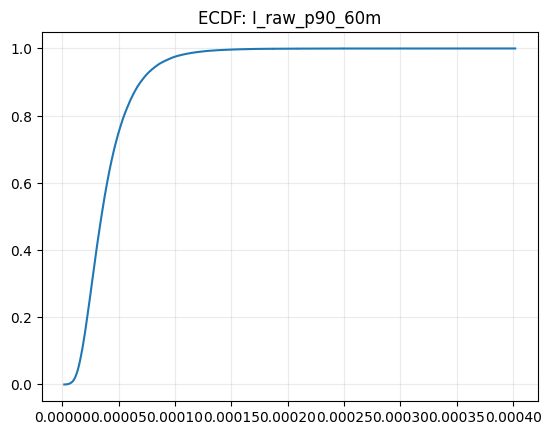

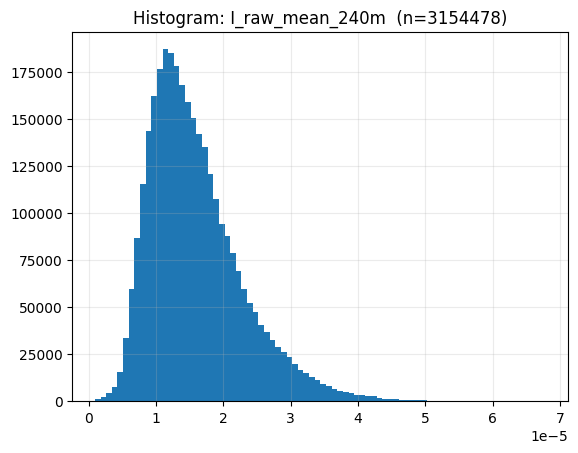

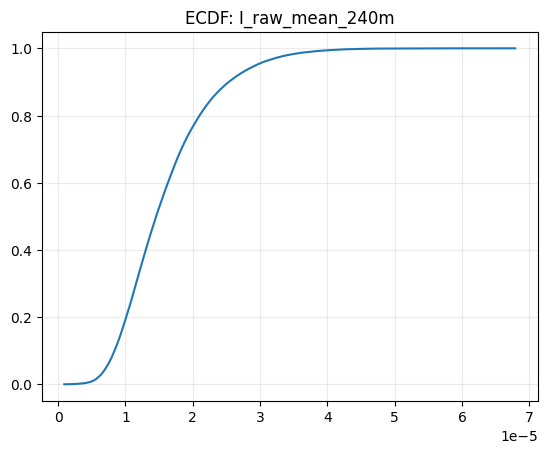

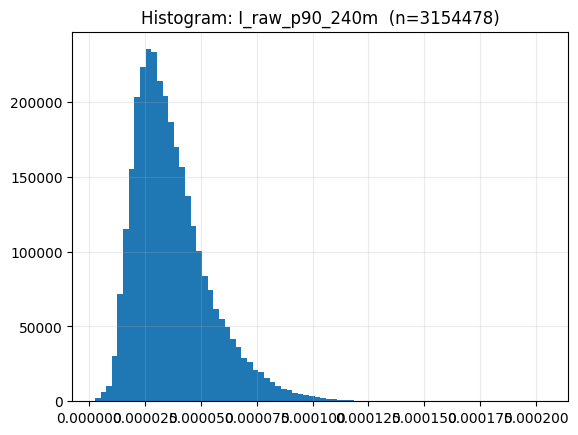

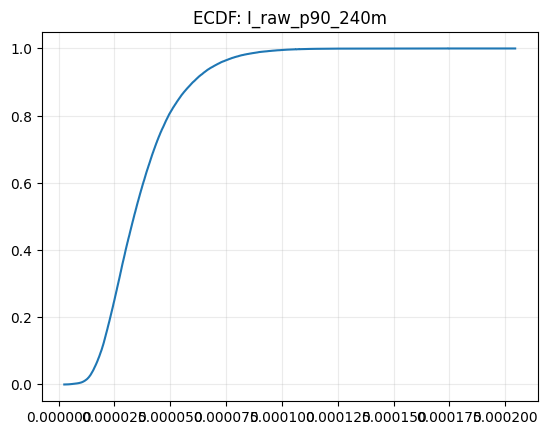

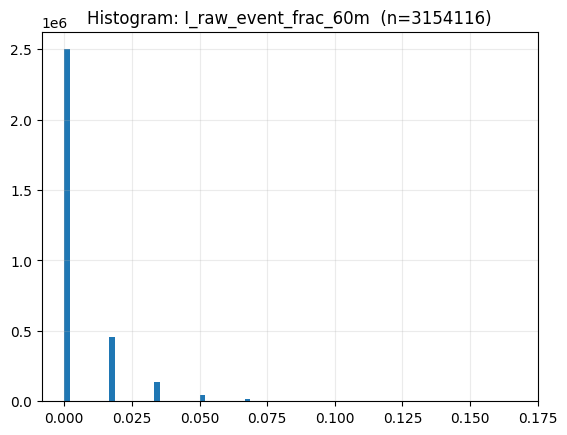

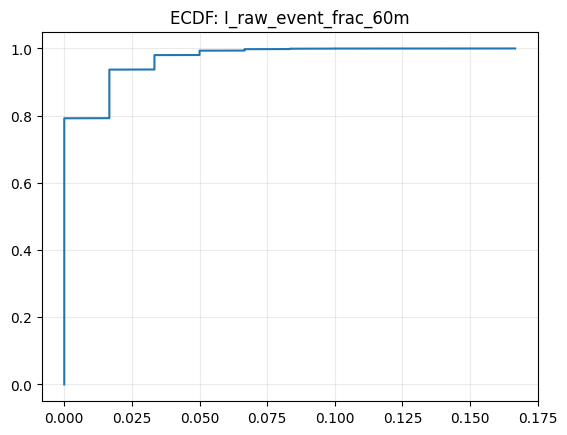

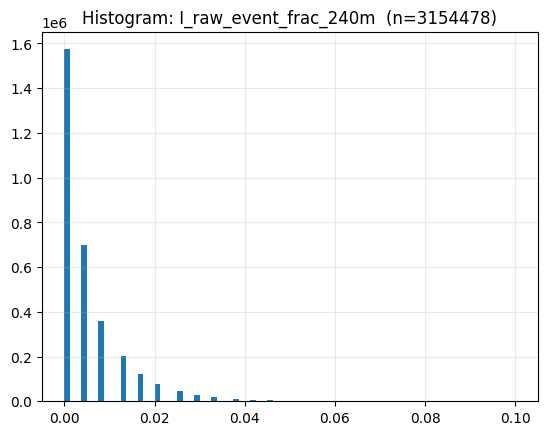

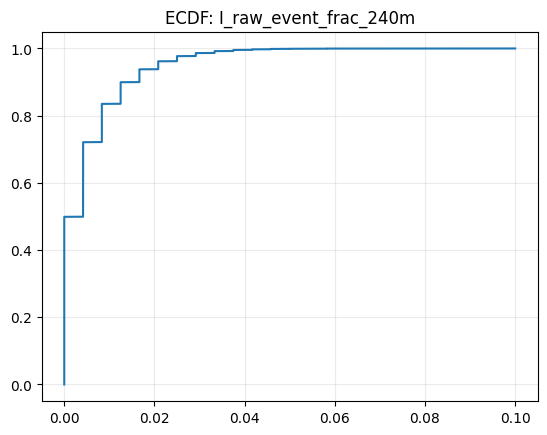

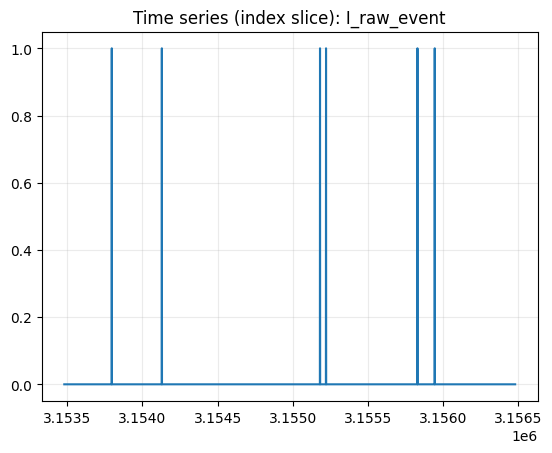

In [67]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map,plot_D=False)

In [68]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
I_raw_mean_60m,0.996138,0.991827,0.987363,0.978100,0.953468,0.842484,0.664386,0.533134
I_raw_p90_60m,0.988937,0.978106,0.967788,0.948322,0.904420,0.749853,0.546458,0.445901
I_raw_mean_240m,0.999661,0.999276,0.998872,0.998016,0.995640,0.983535,0.959329,0.758261
I_raw_p90_240m,0.998959,0.997937,0.996963,0.995097,0.990685,0.972952,0.942971,0.734265
I_raw_event_frac_60m,0.989737,0.978565,0.967264,0.944476,0.886325,0.643452,0.266618,0.165216
I_raw_event_frac_240m,0.998486,0.996833,0.995151,0.991733,0.982884,0.943854,0.876884,0.414393


In [69]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [70]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['I_raw_event']


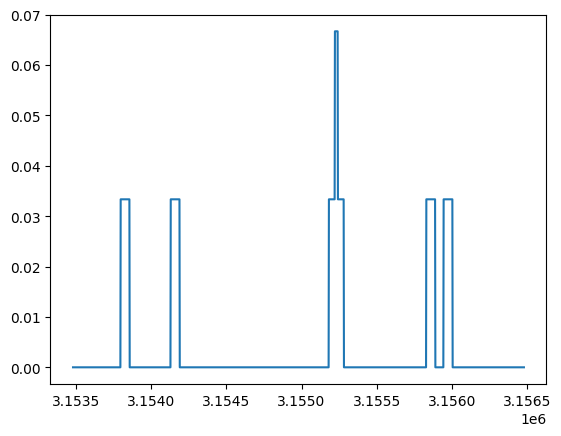

In [71]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G1_A_Activity

In [20]:
group_key = "G1_A_Activity"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [21]:
for abcd in ABCD_KEYS:
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_A_p90_60m,3156480,3148960,0.002382,0.0,0.650646,0.209238,0.169276,1.000000,0.296022,0.356503,0.615854,0.998864,1.000000
rk_slow_A_mean_60m,3156480,3148965,0.002381,0.0,0.462297,0.151052,0.116404,1.000000,0.224572,0.274616,0.427205,0.771404,0.917382
rk_slow_A_mean_240m,3156480,3149260,0.002287,0.0,0.462286,0.128247,0.146966,0.993863,0.245908,0.293166,0.437581,0.712363,0.837158
rk_slow_A_p90_240m,3156480,3149260,0.002287,0.0,0.680564,0.195187,0.210013,1.000000,0.325167,0.391266,0.660415,0.996152,0.999999



--- B_flag (3 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
rk_slow_A_lo,3156480,3148979,0.002376,0.976824,0.023176,2
rk_slow_A_xhi,3156480,3148979,0.002376,0.954482,0.045518,2
rk_slow_A_hi,3156480,3148979,0.002376,0.919788,0.080212,2



--- C_frac (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_A_xhi_frac_60m,3156480,3148965,0.002381,0.558644,0.045517,0.108260,0.0,1.000000,0.0,0.0,0.000000,0.233333,0.583333
rk_slow_A_hi_frac_60m,3156480,3148965,0.002381,0.410884,0.080211,0.153462,0.0,1.000000,0.0,0.0,0.016667,0.400000,0.800000
rk_slow_A_xhi_frac_240m,3156480,3149260,0.002287,0.203146,0.045515,0.079472,0.0,0.970833,0.0,0.0,0.016667,0.195833,0.400000
rk_slow_A_hi_frac_240m,3156480,3149260,0.002287,0.102327,0.080210,0.118022,0.0,1.000000,0.0,0.0,0.033333,0.325000,0.579167



--- D_struct (5 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
maxrun_runlen_rk_slow_A_hi_240m,3156480,3145146,0.003591,0.102278,6.652559,13.058599,0.0,319.000000,0.0,0.0,3.000000,26.000000,66.000000
maxrun_runlen_rk_slow_A_hi_60m,3156480,3148026,0.002678,0.410819,2.930499,8.429697,0.0,319.000000,0.0,0.0,1.000000,12.000000,37.000000
runlen_rk_slow_A_hi,3156480,3148979,0.002376,0.919788,0.587353,4.941157,0.0,319.000000,0.0,0.0,0.000000,1.000000,14.000000
rk_slow_A_hi_flip_rate_240m,3156480,3156241,0.000076,0.103215,0.061385,0.059329,0.0,0.450000,0.0,0.0,0.041667,0.183333,0.250000
rk_slow_A_hi_flip_rate_60m,3156480,3156421,0.000019,0.409678,0.061382,0.081036,0.0,0.633333,0.0,0.0,0.033333,0.233333,0.333333


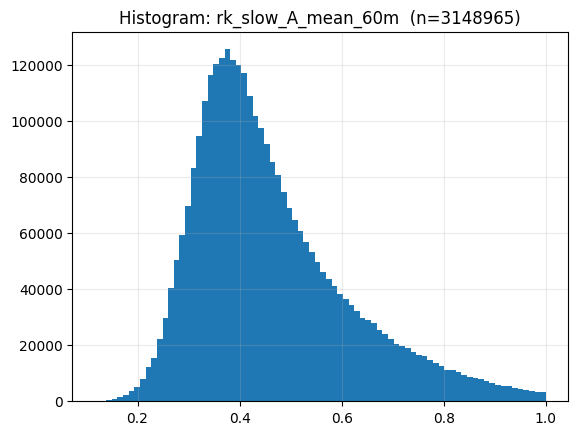

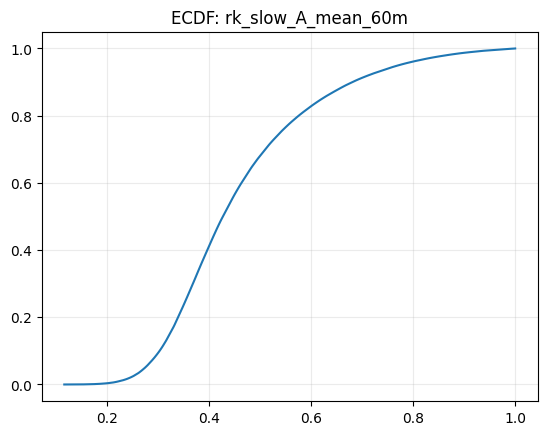

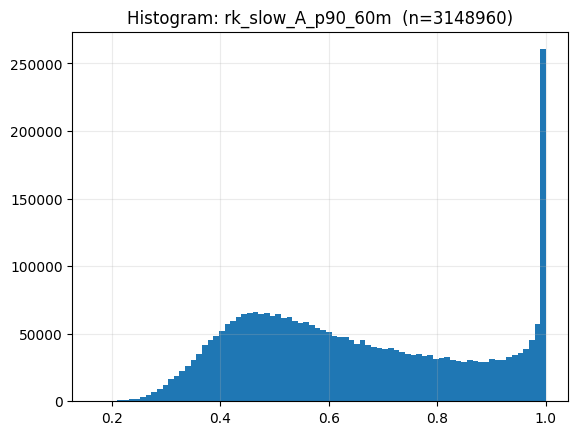

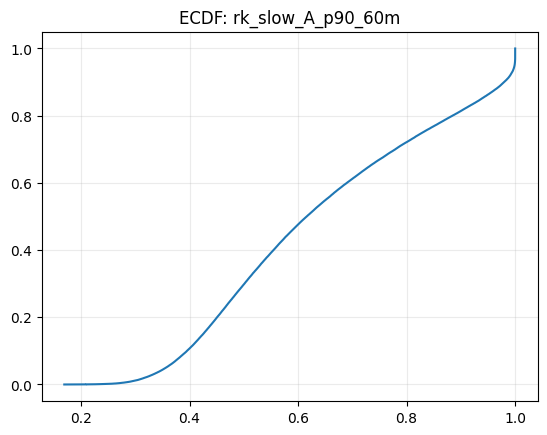

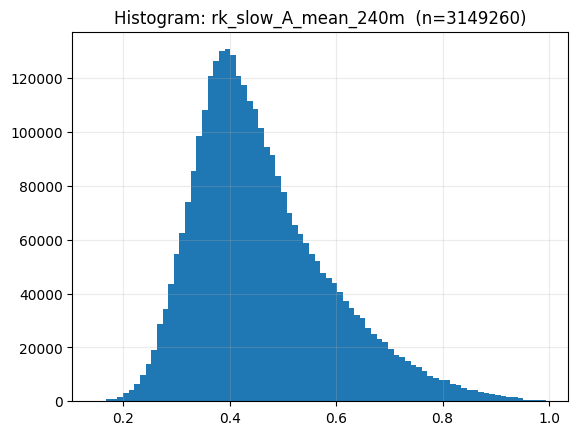

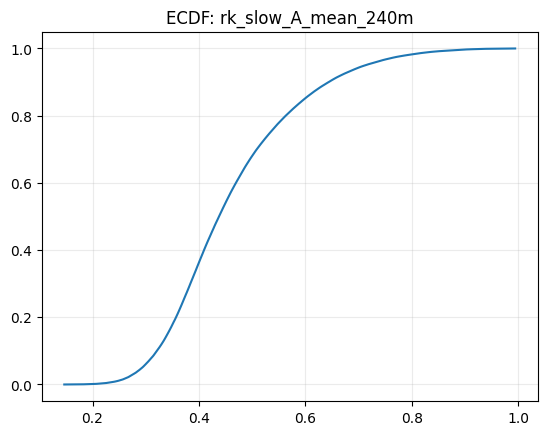

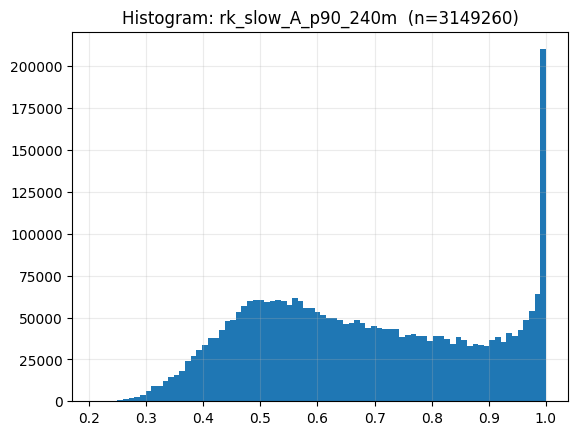

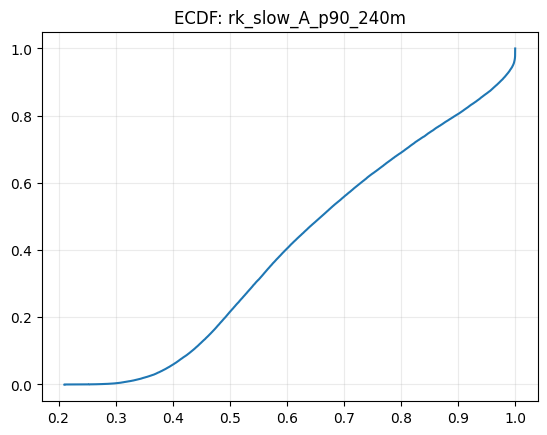

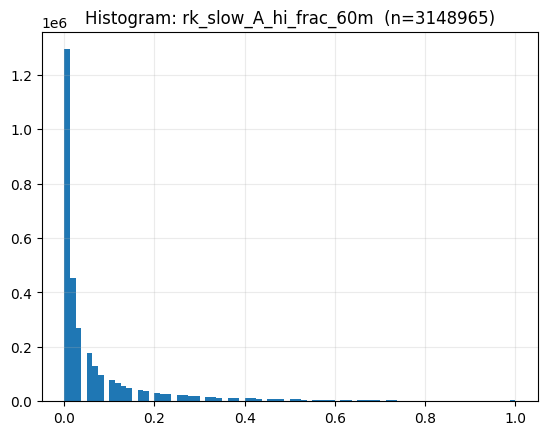

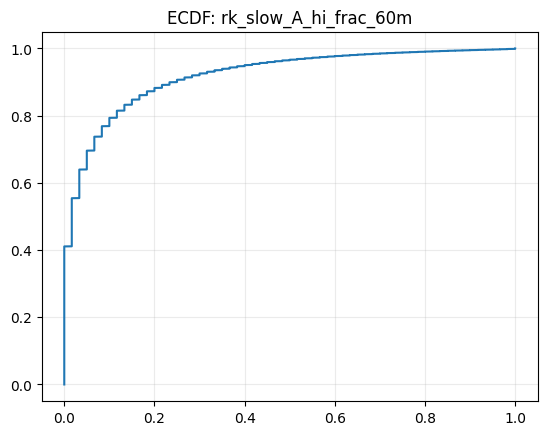

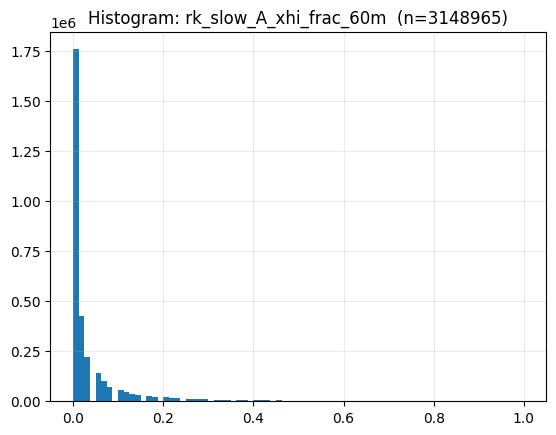

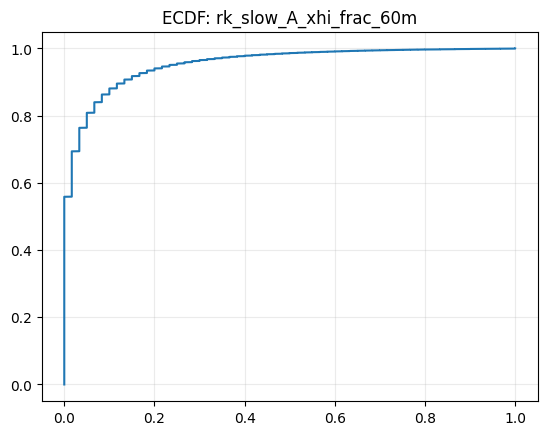

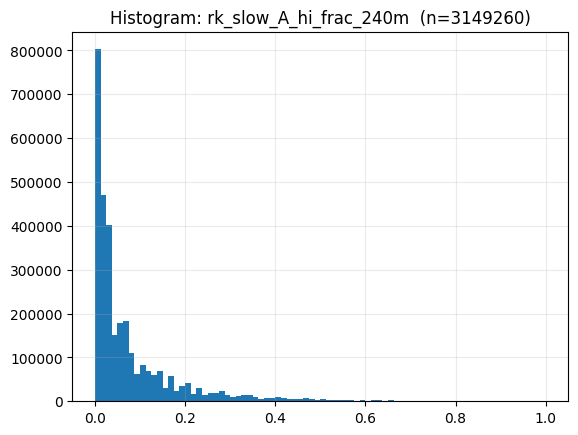

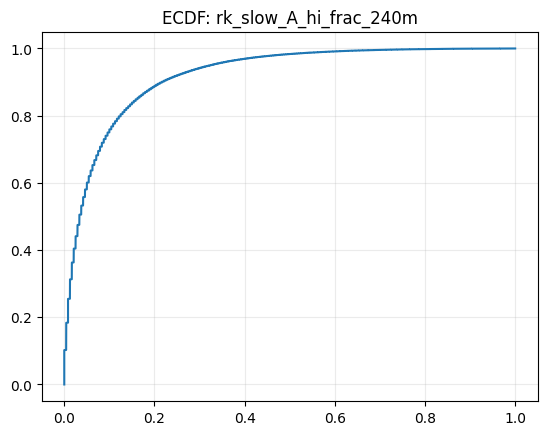

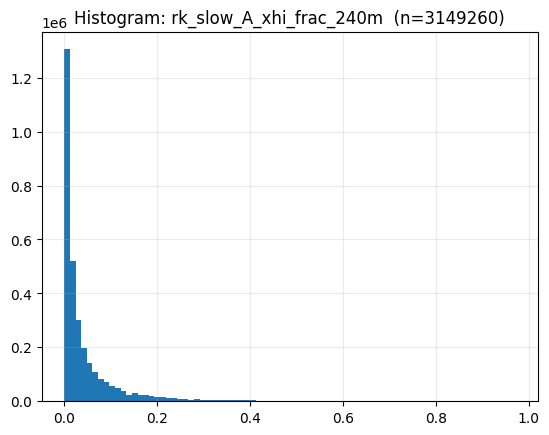

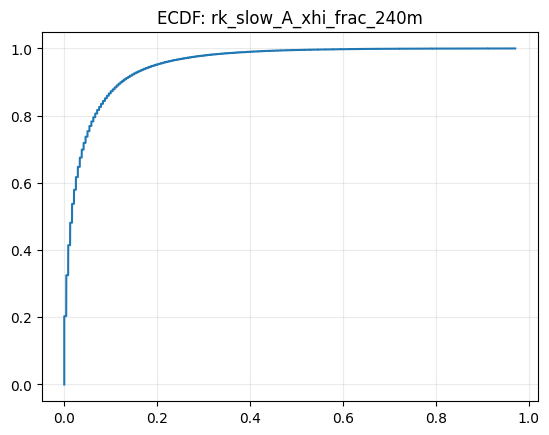

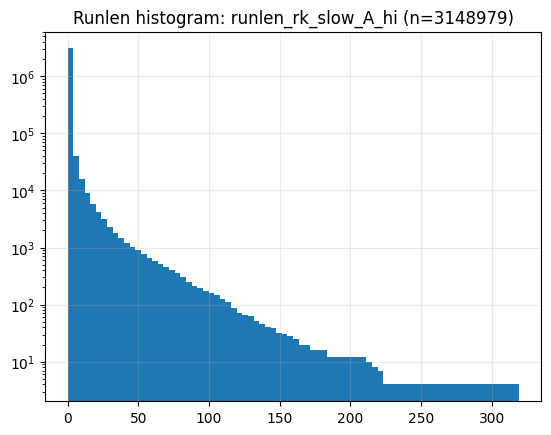

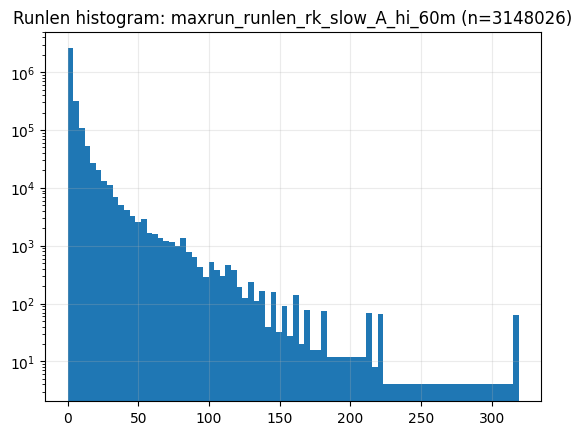

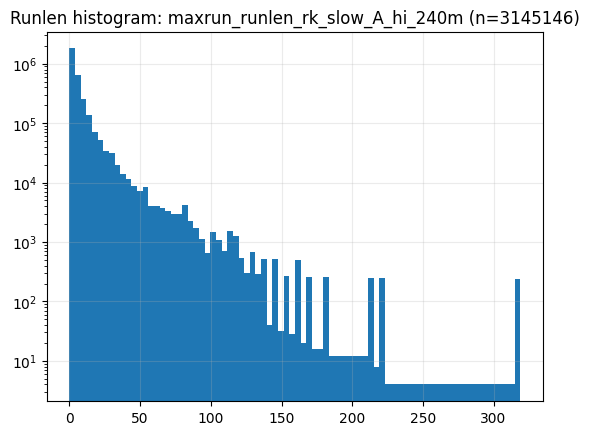

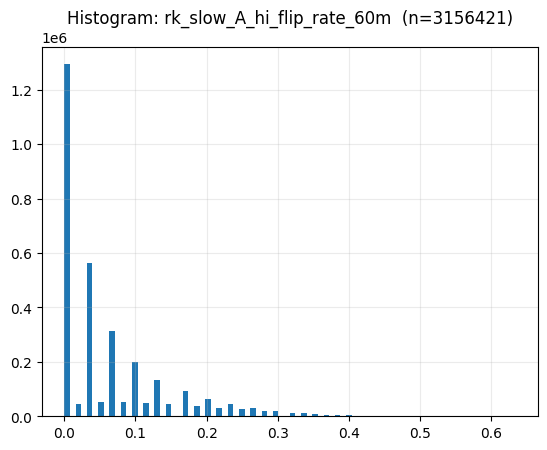

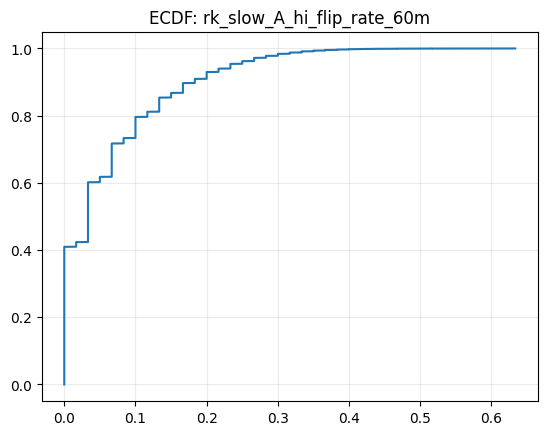

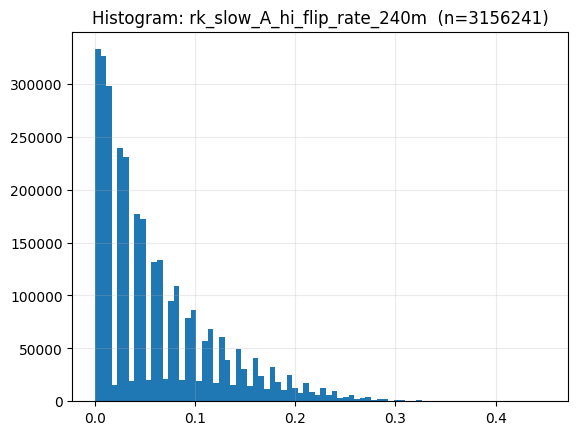

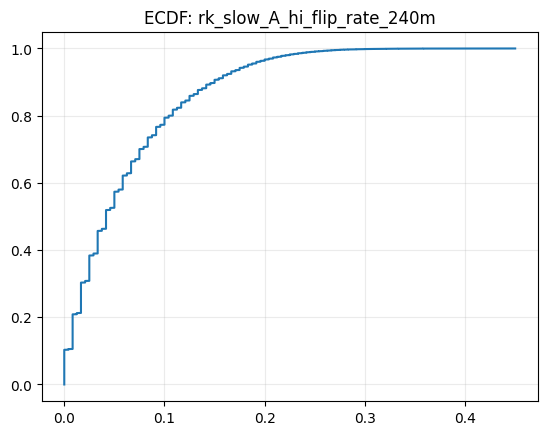

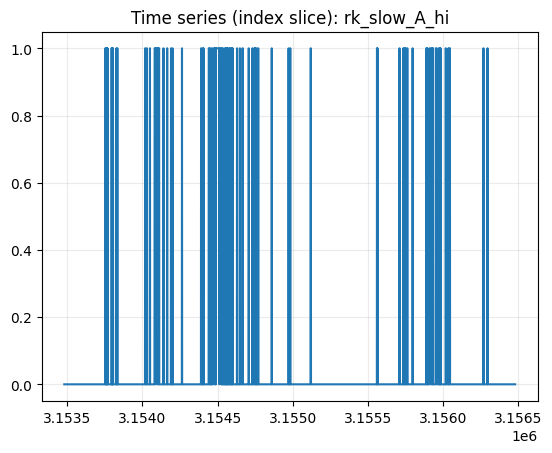

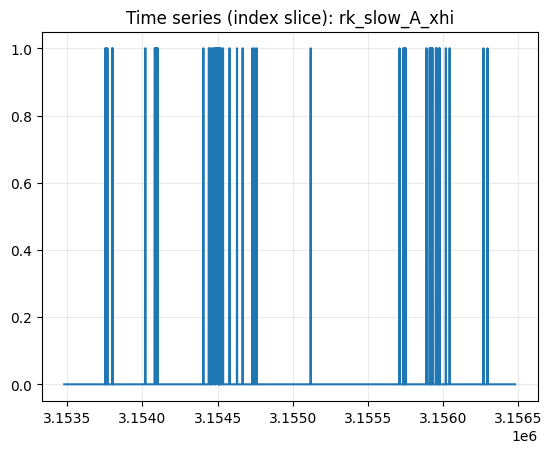

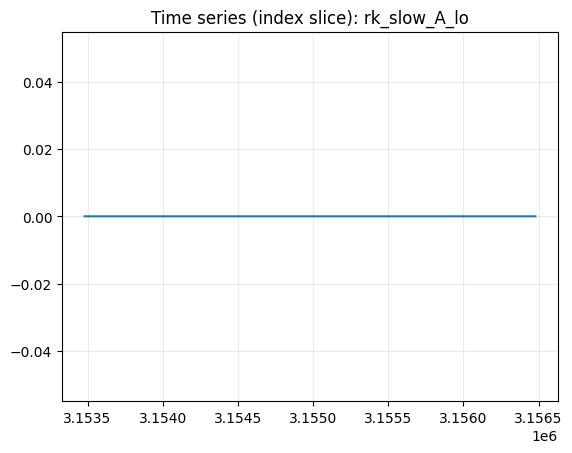

In [22]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map)

In [24]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
rk_slow_A_mean_60m,0.999690,0.998975,0.997926,0.994953,0.983298,0.897755,0.732168,0.388542
rk_slow_A_p90_60m,0.997611,0.994266,0.990264,0.980893,0.952760,0.816525,0.607942,0.314446
rk_slow_A_mean_240m,0.999965,0.999880,0.999750,0.999368,0.997773,0.984037,0.946994,0.578400
rk_slow_A_p90_240m,0.999752,0.999380,0.998905,0.997693,0.993418,0.965343,0.907272,0.491786
rk_slow_A_hi_frac_60m,0.999287,0.997865,0.995884,0.990515,0.970499,0.832668,0.577864,0.211854
rk_slow_A_xhi_frac_60m,0.999105,0.997327,0.994868,0.988269,0.964105,0.802764,0.510257,0.154199
rk_slow_A_hi_frac_240m,0.999915,0.999735,0.999477,0.998752,0.995902,0.973363,0.916760,0.419679
rk_slow_A_xhi_frac_240m,0.999886,0.999649,0.999314,0.998386,0.994822,0.967762,0.901935,0.353235
runlen_rk_slow_A_hi,0.975943,0.954270,0.934136,0.897146,0.817012,0.586589,0.377584,0.076849


In [25]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [26]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['rk_slow_A_hi', 'rk_slow_A_xhi', 'rk_slow_A_lo']


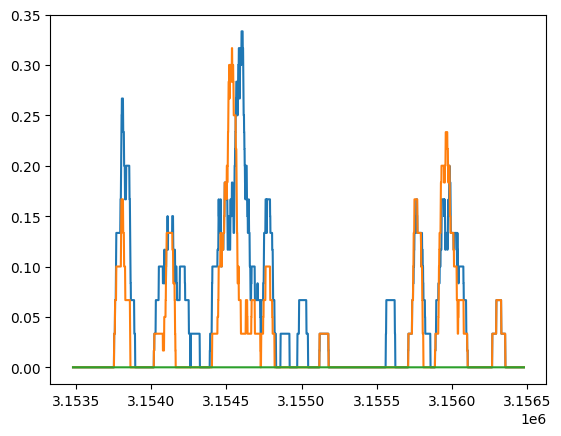

In [30]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G2_V_Volatility

In [31]:
group_key = "G2_V_Volatility"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [32]:
for abcd in ABCD_KEYS:
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_V_p90_60m,3156480,3148960,0.002382,0.0,0.607761,0.176525,0.201438,1.000000,0.344827,0.394542,0.554935,0.981106,0.999999
rk_slow_V_mean_60m,3156480,3148965,0.002381,0.0,0.466969,0.112261,0.157012,0.999945,0.271233,0.320411,0.448140,0.688778,0.847116
rk_slow_V_mean_240m,3156480,3149260,0.002287,0.0,0.466961,0.095558,0.185157,0.987828,0.290491,0.335252,0.453968,0.649143,0.772788
rk_slow_V_p90_240m,3156480,3149260,0.002287,0.0,0.623587,0.165764,0.261871,1.000000,0.368562,0.416838,0.580984,0.964621,0.999859



--- B_flag (3 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
rk_slow_V_xhi,3156480,3148975,0.002378,0.963637,0.036363,2
rk_slow_V_hi,3156480,3148975,0.002378,0.940711,0.059289,2
rk_fast_V_spike,3156480,3153255,0.001022,0.978709,0.021291,2



--- C_frac (5 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_V_xhi_frac_60m,3156480,3148965,0.002381,0.552086,0.036359,0.090053,0.0,1.000000,0.0,0.0,0.000000,0.183333,0.466667
rk_slow_V_hi_frac_60m,3156480,3148965,0.002381,0.433120,0.059284,0.123571,0.0,1.000000,0.0,0.0,0.016667,0.283333,0.666667
rk_slow_V_xhi_frac_240m,3156480,3149260,0.002287,0.208789,0.036356,0.067186,0.0,0.979167,0.0,0.0,0.012500,0.154167,0.333333
rk_slow_V_hi_frac_240m,3156480,3149260,0.002287,0.125110,0.059281,0.095853,0.0,1.000000,0.0,0.0,0.025000,0.241667,0.479167
rk_fast_V_spike_frac_60m,3156480,3153245,0.001025,0.612900,0.021288,0.049774,0.0,0.916667,0.0,0.0,0.000000,0.100000,0.250000



--- D_struct (10 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_fast_V_spike_interarrival_cv_240m,3156480,1820748,0.423171,0.000222,1.152821,0.481672,0.0,4.305792,0.079835,0.348797,1.144442,1.990065,2.405136
rk_fast_V_spike_interarrival_mean_240m,3156480,1820748,0.423171,0.000000,87.483692,85.009387,2.0,1164.500000,10.909091,17.400000,62.500000,237.000000,432.500000
maxrun_runlen_rk_slow_V_xhi_240m,3156480,3144492,0.003798,0.208937,3.078320,6.651894,0.0,123.000000,0.000000,0.000000,1.000000,11.000000,32.000000
maxrun_runlen_rk_slow_V_hi_240m,3156480,3144492,0.003798,0.125238,4.696855,10.411095,0.0,265.000000,0.000000,0.000000,2.000000,18.000000,46.000000
maxrun_runlen_rk_slow_V_xhi_60m,3156480,3147834,0.002739,0.552107,1.291414,4.105137,0.0,123.000000,0.000000,0.000000,0.000000,5.000000,16.000000
maxrun_runlen_rk_slow_V_hi_60m,3156480,3147834,0.002739,0.433134,2.081993,6.630595,0.0,265.000000,0.000000,0.000000,1.000000,8.000000,26.000000
runlen_rk_slow_V_xhi,3156480,3148975,0.002378,0.963637,0.167043,1.998951,0.0,123.000000,0.000000,0.000000,0.000000,0.000000,3.000000
runlen_rk_slow_V_hi,3156480,3148975,0.002378,0.940711,0.361867,3.860273,0.0,265.000000,0.000000,0.000000,0.000000,1.000000,7.000000
rk_slow_V_hi_flip_rate_240m,3156480,3156241,0.000076,0.125837,0.054663,0.056339,0.0,0.429167,0.000000,0.000000,0.033333,0.175000,0.241667


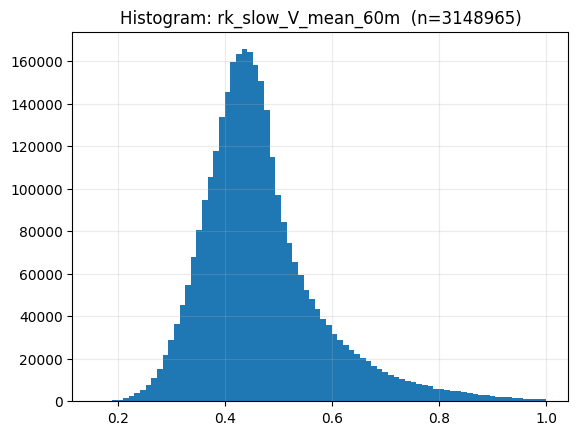

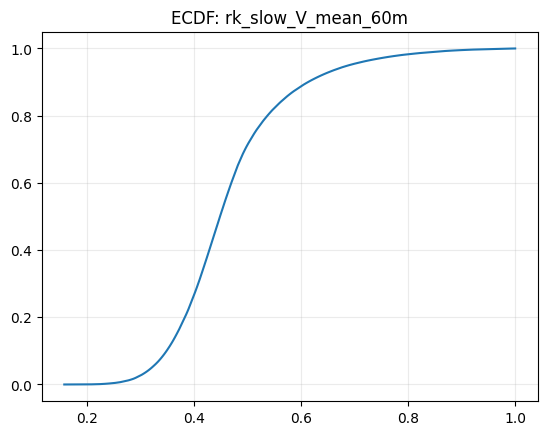

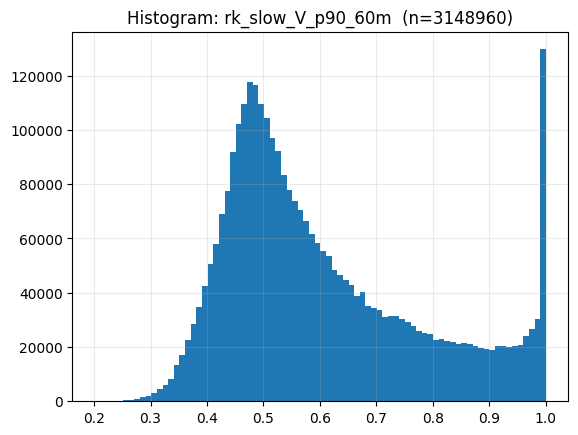

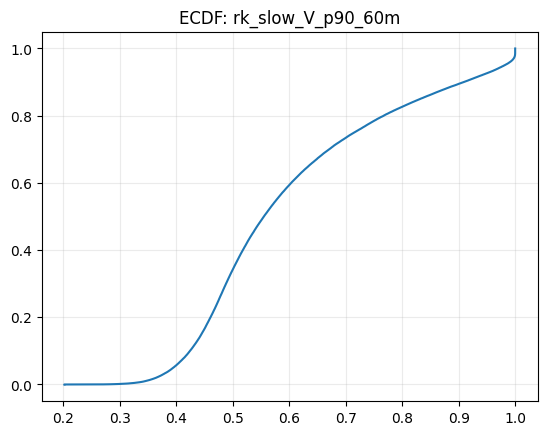

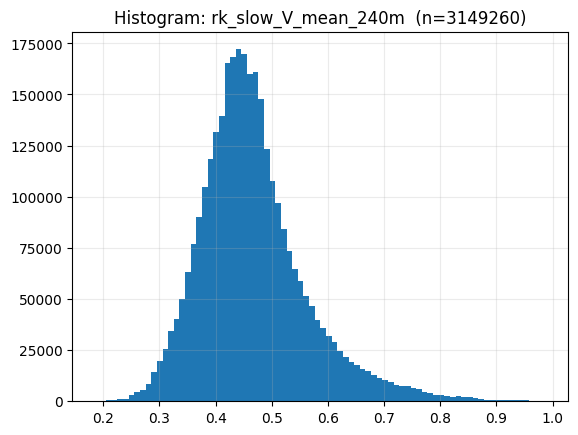

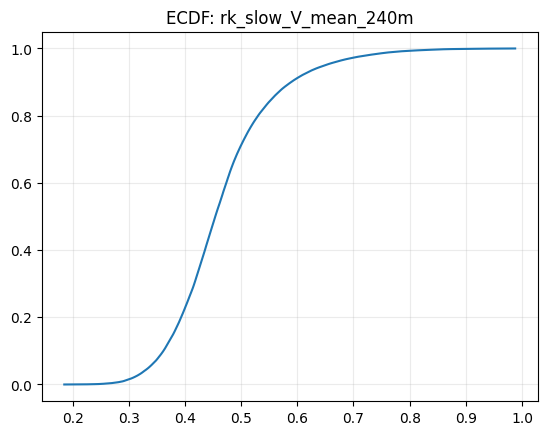

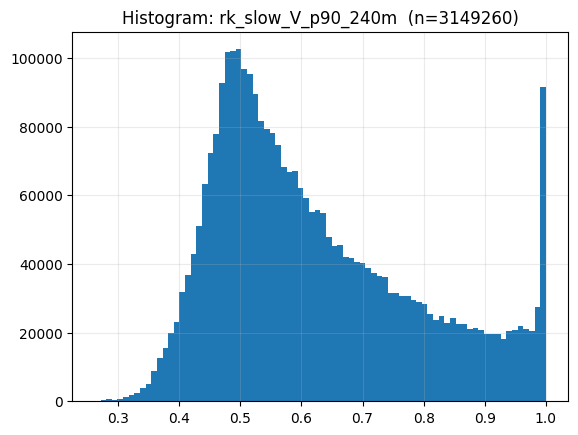

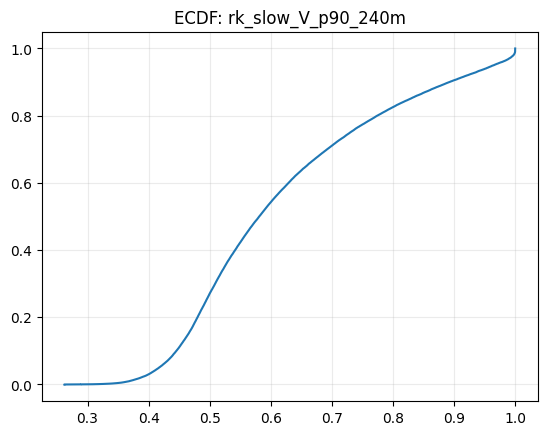

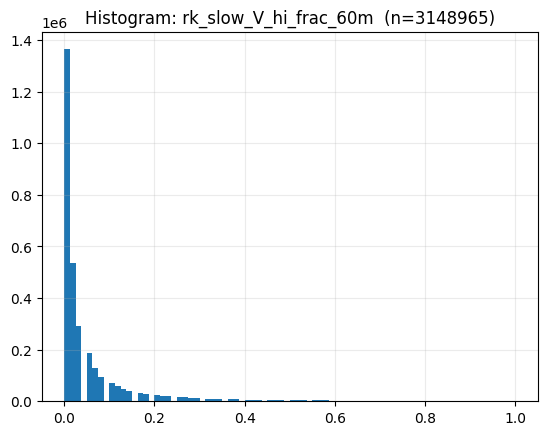

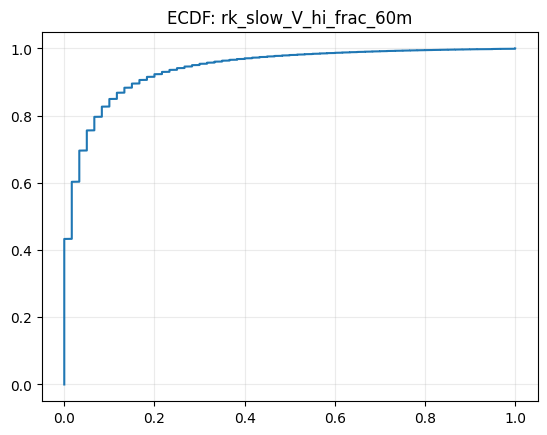

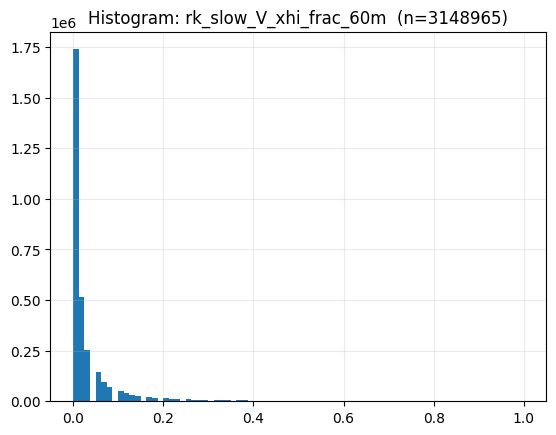

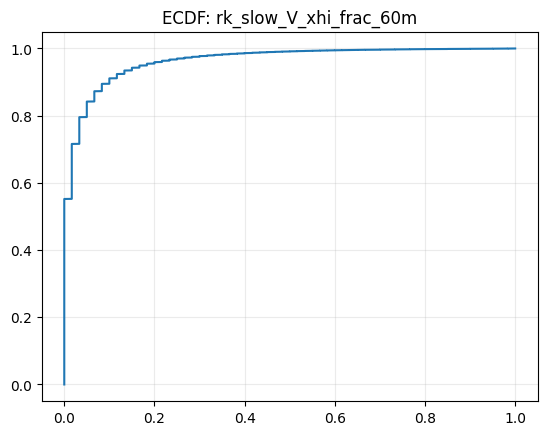

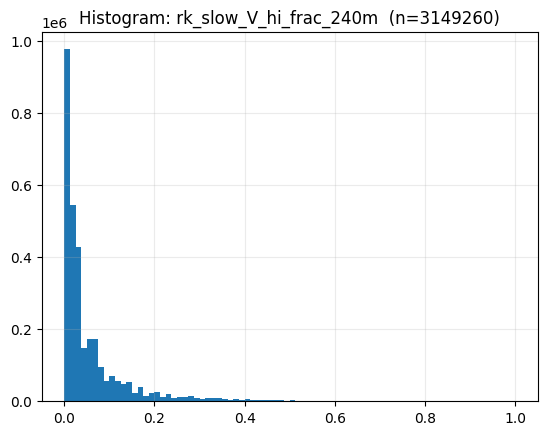

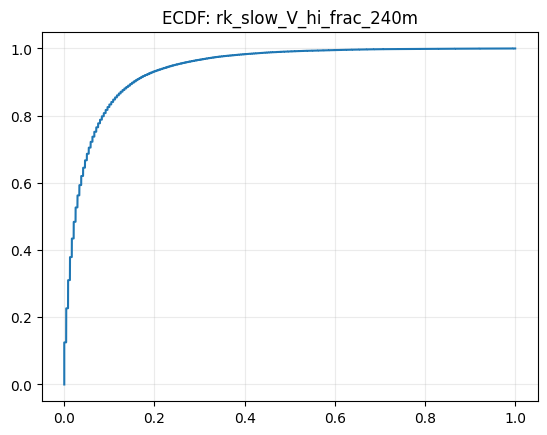

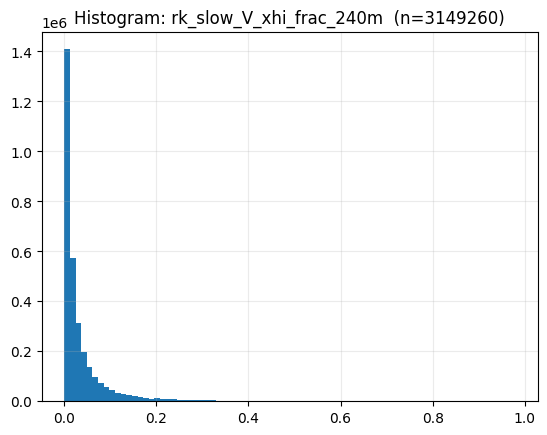

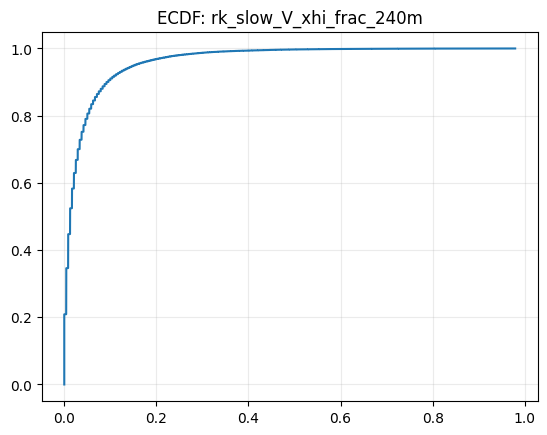

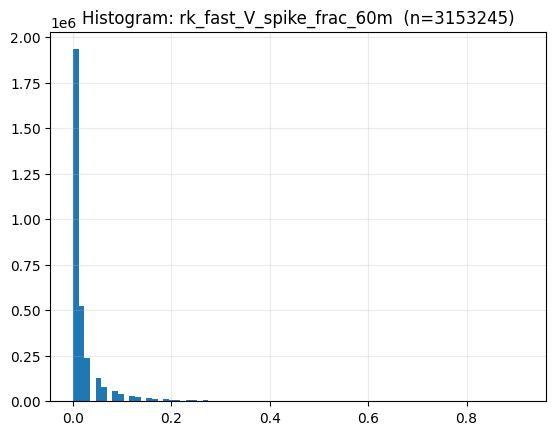

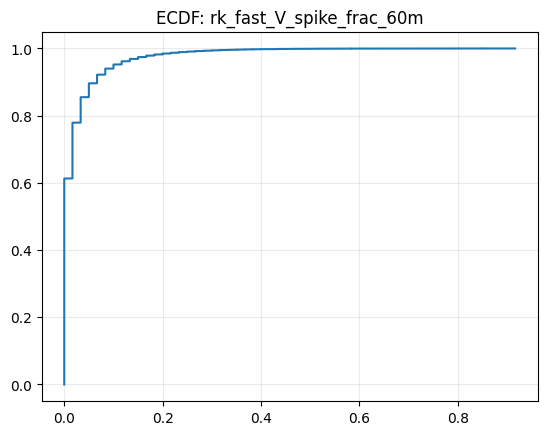

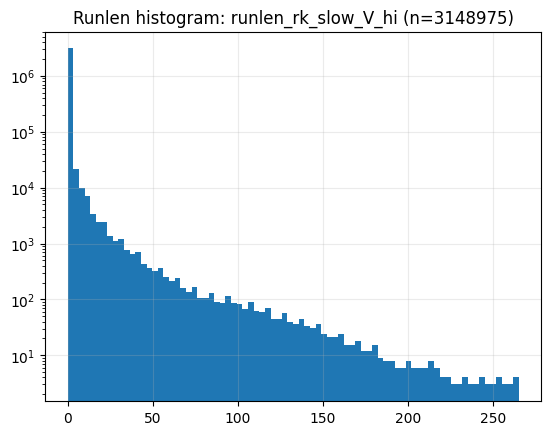

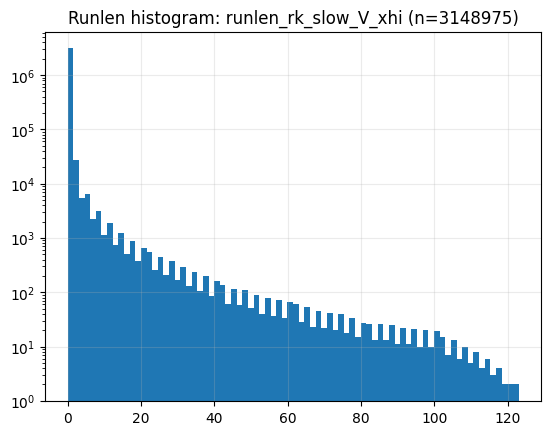

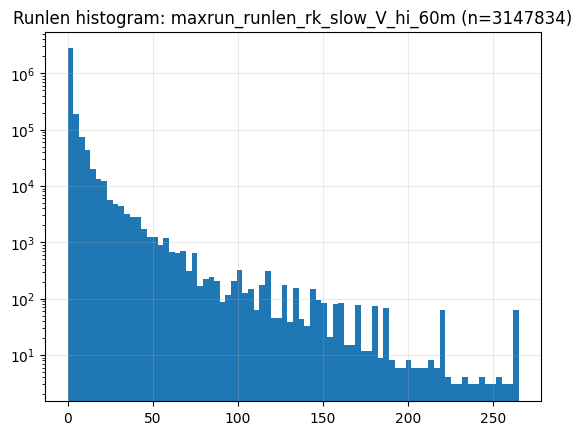

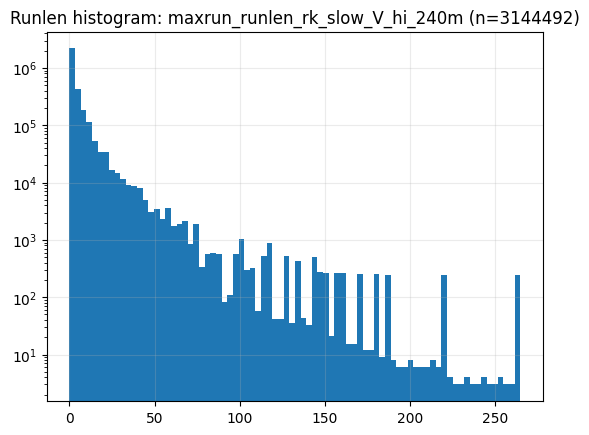

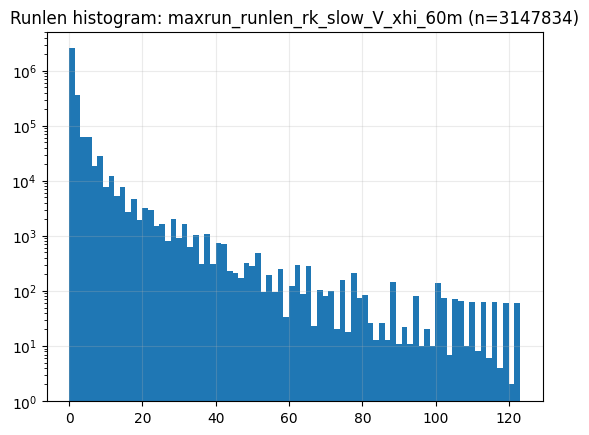

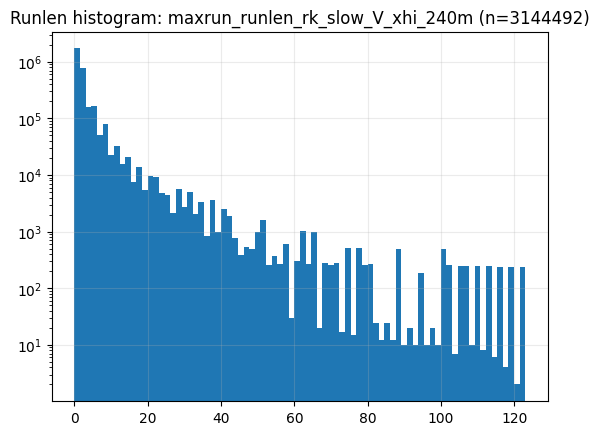

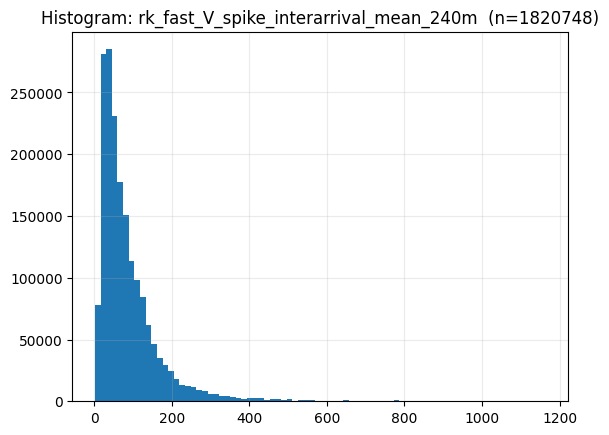

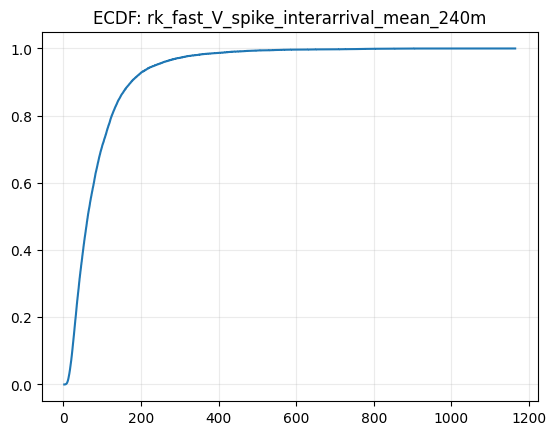

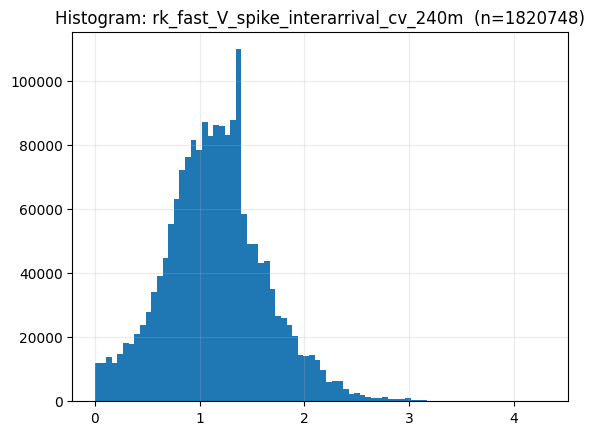

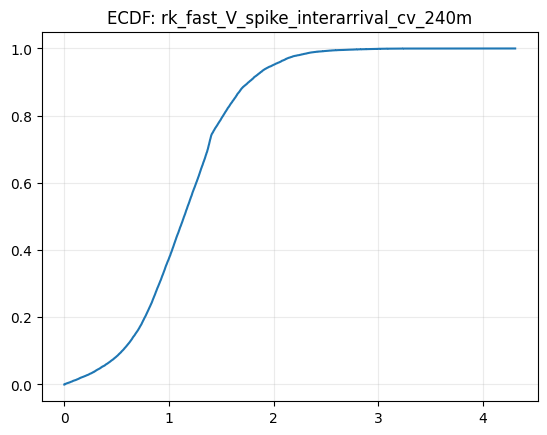

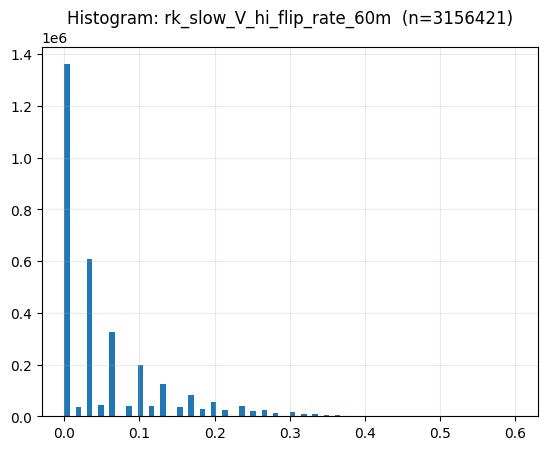

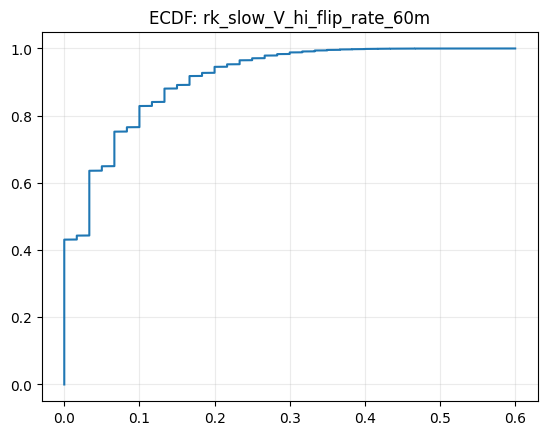

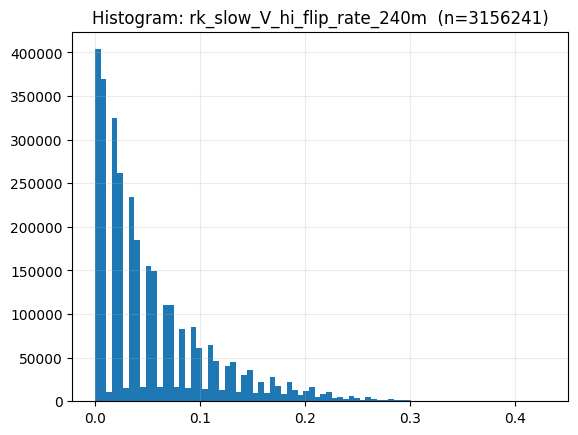

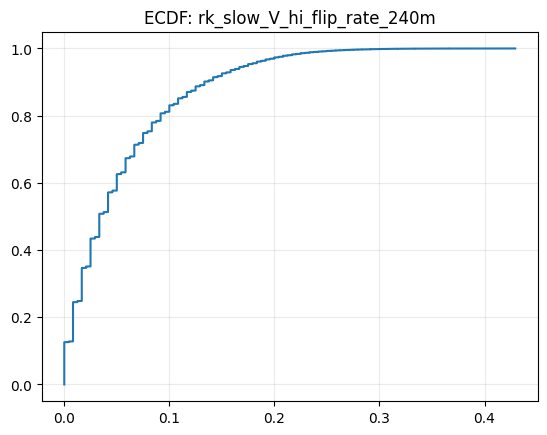

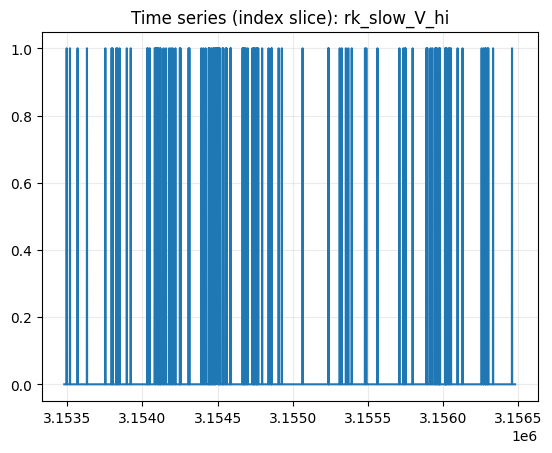

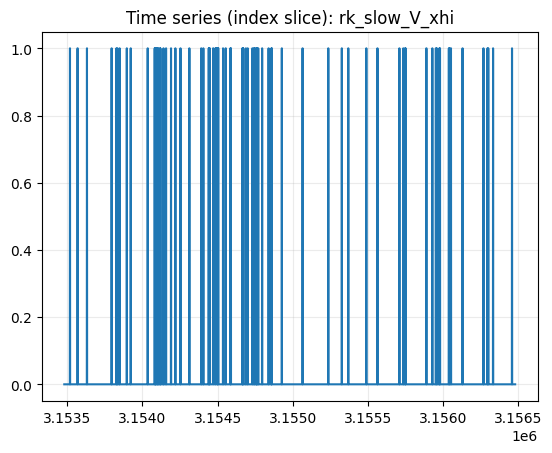

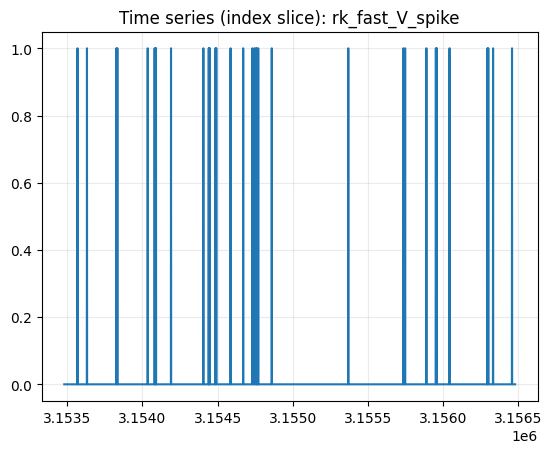

In [33]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map)

In [34]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
rk_slow_V_mean_60m,0.999631,0.998843,0.997710,0.994550,0.982379,0.894981,0.728826,0.423329
rk_slow_V_p90_60m,0.997286,0.993729,0.989591,0.980090,0.952205,0.818405,0.611319,0.345431
rk_slow_V_mean_240m,0.999961,0.999873,0.999742,0.999361,0.997803,0.984749,0.950282,0.615918
rk_slow_V_p90_240m,0.999745,0.999381,0.998928,0.997792,0.993865,0.968619,0.916356,0.527899
rk_slow_V_hi_frac_60m,0.999139,0.997550,0.995393,0.989657,0.968752,0.829302,0.577034,0.264923
rk_slow_V_xhi_frac_60m,0.998935,0.997001,0.994400,0.987554,0.963007,0.803233,0.518911,0.212614
rk_slow_V_hi_frac_240m,0.999903,0.999714,0.999450,0.998727,0.995955,0.974910,0.923698,0.487861
rk_slow_V_xhi_frac_240m,0.999872,0.999631,0.999298,0.998398,0.995023,0.970236,0.911636,0.432290
rk_fast_V_spike_frac_60m,0.997732,0.993849,0.988821,0.976132,0.933492,0.687406,0.285545,0.048435


In [35]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [36]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['rk_slow_V_hi', 'rk_slow_V_xhi', 'rk_fast_V_spike']


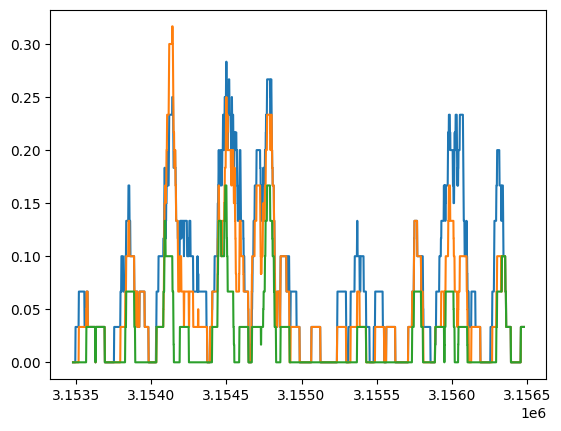

In [37]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G3_F_FlowStress

In [38]:
group_key = "G3_F_FlowStress"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [39]:
for abcd in ABCD_KEYS:
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_Fabs_p90_60m,3156480,2628832,0.167163,0.0,0.856057,0.055772,0.004618,0.996466,0.693430,0.757115,0.861915,0.935564,0.961256
rk_slow_Fabs_mean_60m,3156480,2628833,0.167163,0.0,0.520179,0.065597,0.082905,0.914882,0.354020,0.411961,0.521497,0.624046,0.673573
rk_slow_Fabs_mean_240m,3156480,2649839,0.160508,0.0,0.520295,0.048295,0.177764,0.755750,0.392667,0.439909,0.521994,0.594253,0.630722
rk_slow_Fabs_p90_240m,3156480,2649839,0.160508,0.0,0.858483,0.039838,0.483921,0.988893,0.740471,0.790392,0.862247,0.914890,0.938442



--- B_flag (3 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
rk_slow_Fabs_xhi,3156480,2539191,0.195562,0.963844,0.036156,2
rk_slow_Fabs_hi,3156480,2539191,0.195562,0.882810,0.117190,2
rk_fast_Fabs_spike,3156480,2545736,0.193489,0.998379,0.001621,2



--- C_frac (5 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_Fabs_xhi_frac_60m,3156480,2628833,0.167163,0.225555,0.036256,0.036498,0.0,0.600000,0.000000,0.000000,0.033333,0.100000,0.161290
rk_slow_Fabs_hi_frac_60m,3156480,2628833,0.167163,0.015985,0.117336,0.068686,0.0,0.866667,0.000000,0.021277,0.105263,0.241379,0.326087
rk_fast_Fabs_spike_frac_60m,3156480,2640172,0.163571,0.921726,0.001644,0.006328,0.0,0.214286,0.000000,0.000000,0.000000,0.016667,0.033333
rk_slow_Fabs_xhi_frac_240m,3156480,2649839,0.160508,0.013997,0.036319,0.023561,0.0,0.305263,0.000000,0.008333,0.033333,0.078947,0.113445
rk_slow_Fabs_hi_frac_240m,3156480,2649839,0.160508,0.000147,0.117512,0.047372,0.0,0.484211,0.025105,0.050000,0.112500,0.200000,0.255411



--- D_struct (10 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_fast_Fabs_spike_interarrival_cv_240m,3156480,181276,0.942570,0.001026,1.097407,0.398657,0.0,2.296848,0.062854,0.285271,1.199792,1.648657,1.973964
rk_fast_Fabs_spike_interarrival_mean_240m,3156480,181276,0.942570,0.000000,377.334386,470.671670,2.5,9436.500000,28.500000,54.000000,223.000000,1176.666667,2092.500000
maxrun_runlen_rk_slow_Fabs_xhi_240m,3156480,1251763,0.603431,0.020434,1.472432,0.760388,0.0,8.000000,0.000000,1.000000,1.000000,3.000000,4.000000
maxrun_runlen_rk_slow_Fabs_hi_240m,3156480,1251763,0.603431,0.000312,2.637780,1.221420,0.0,35.000000,1.000000,1.000000,2.000000,5.000000,7.000000
maxrun_runlen_rk_slow_Fabs_xhi_60m,3156480,1665959,0.472210,0.235381,0.929196,0.696430,0.0,13.000000,0.000000,0.000000,1.000000,2.000000,3.000000
maxrun_runlen_rk_slow_Fabs_hi_60m,3156480,1665959,0.472210,0.018427,1.767997,1.028085,0.0,35.000000,0.000000,1.000000,2.000000,3.000000,5.000000
runlen_rk_slow_Fabs_xhi,3156480,2539191,0.195562,0.963844,0.040790,0.226821,0.0,13.000000,0.000000,0.000000,0.000000,0.000000,1.000000
runlen_rk_slow_Fabs_hi,3156480,2539191,0.195562,0.882810,0.147435,0.471861,0.0,35.000000,0.000000,0.000000,0.000000,1.000000,2.000000
rk_slow_Fabs_hi_flip_rate_240m,3156480,3156241,0.000076,0.114870,0.145500,0.082813,0.0,0.520833,0.000000,0.000000,0.154167,0.275000,0.325000


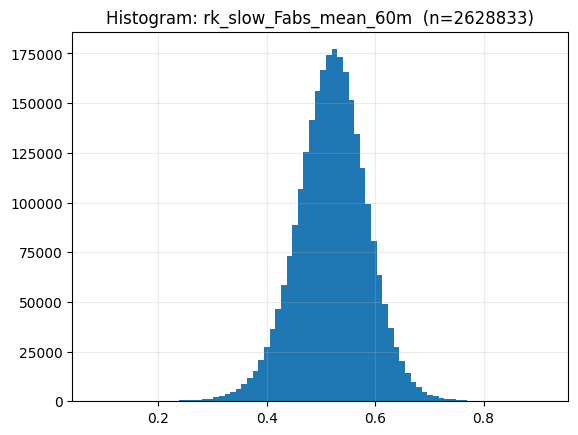

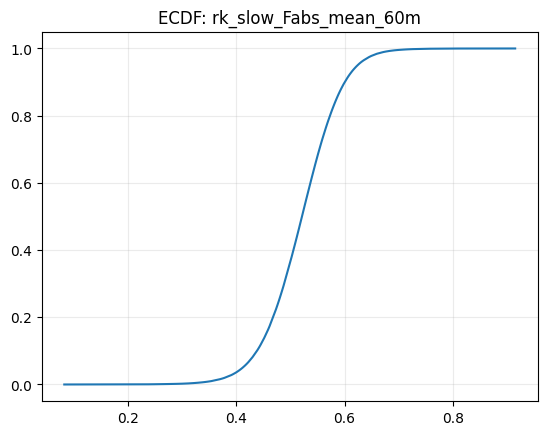

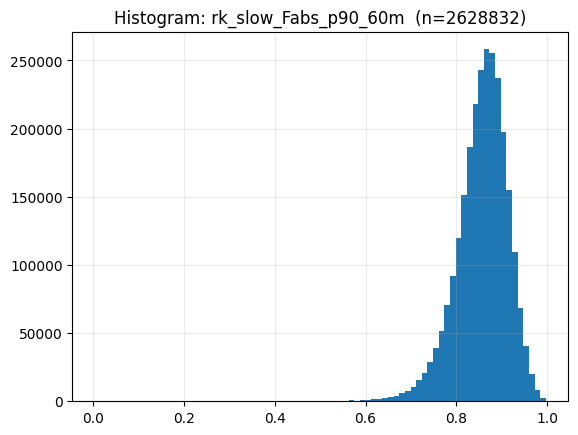

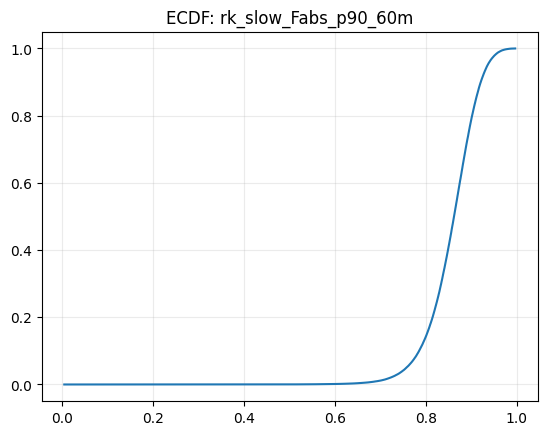

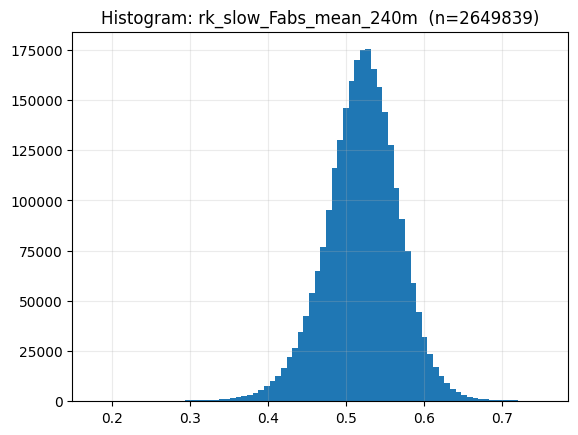

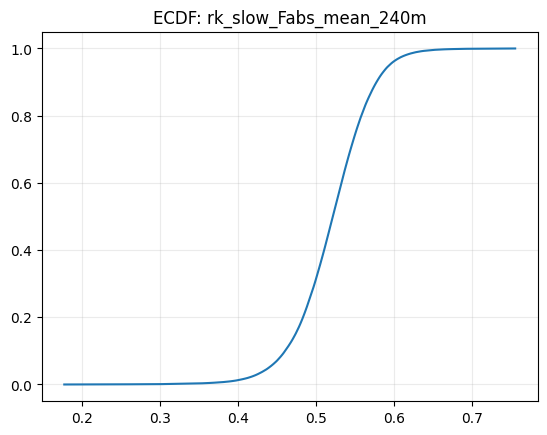

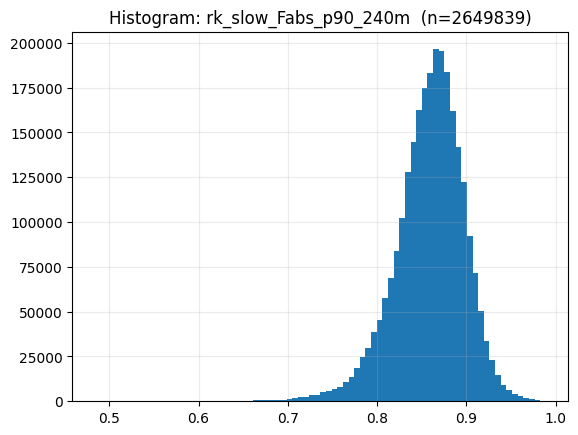

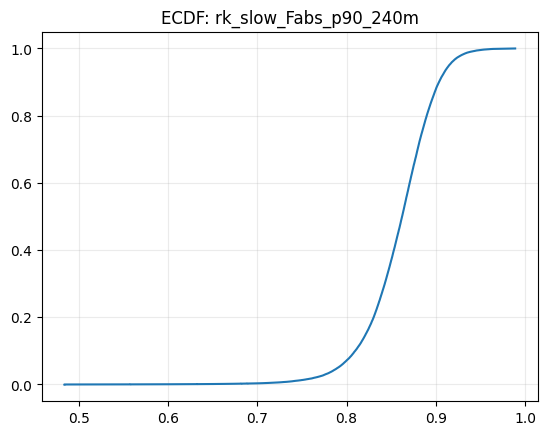

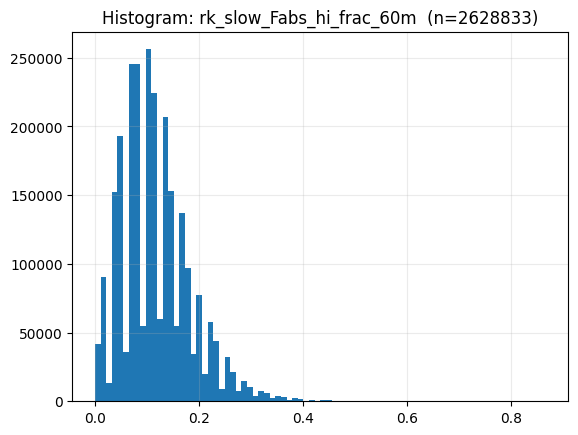

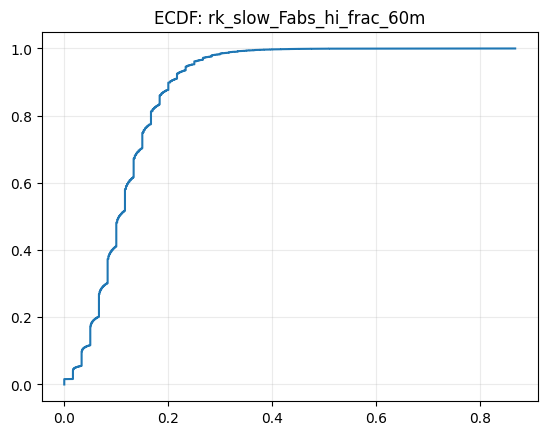

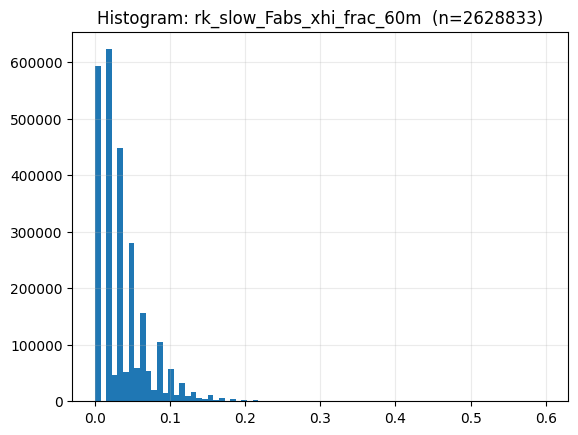

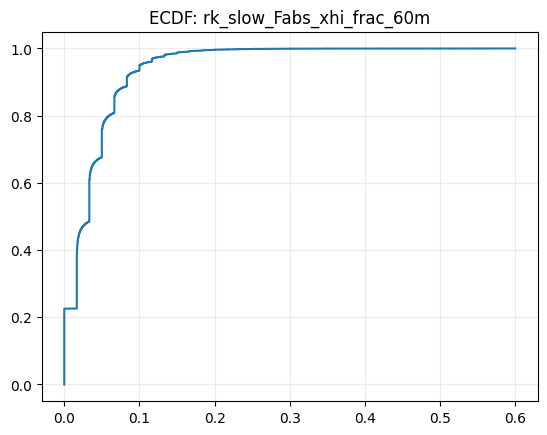

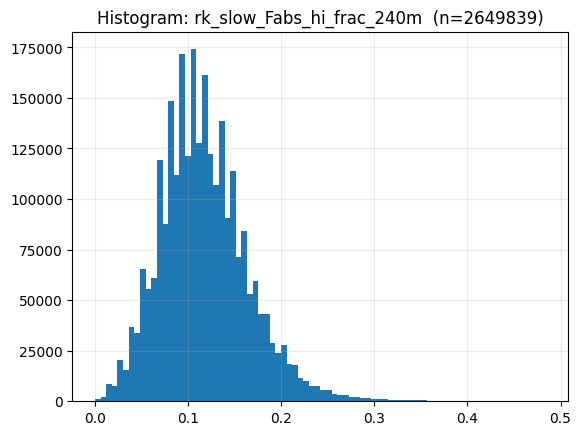

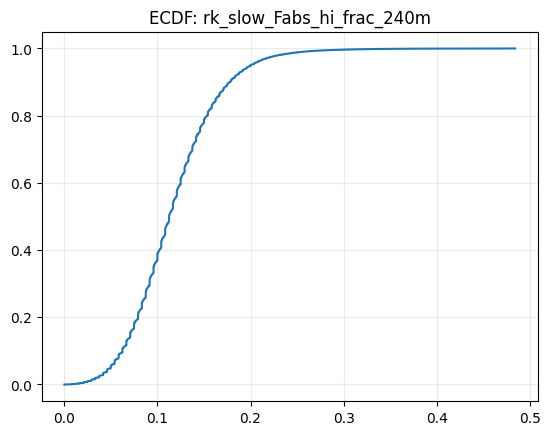

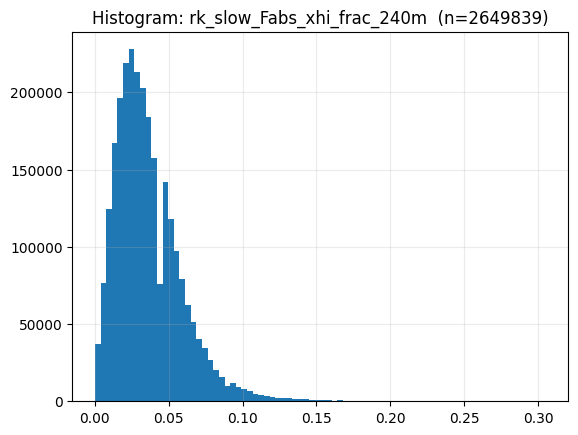

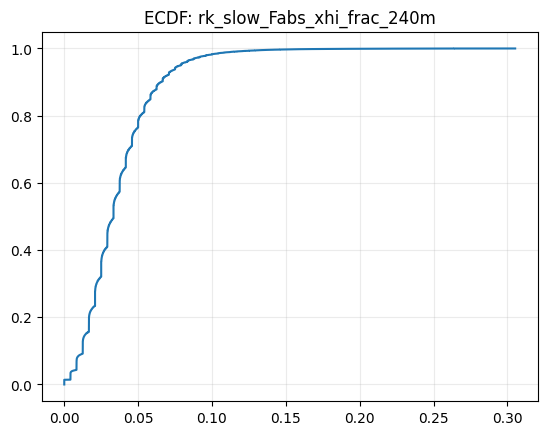

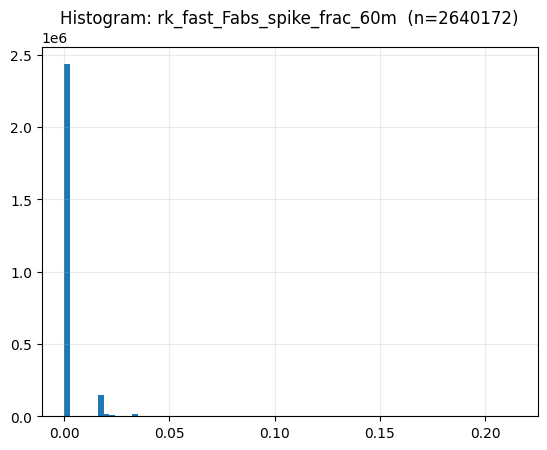

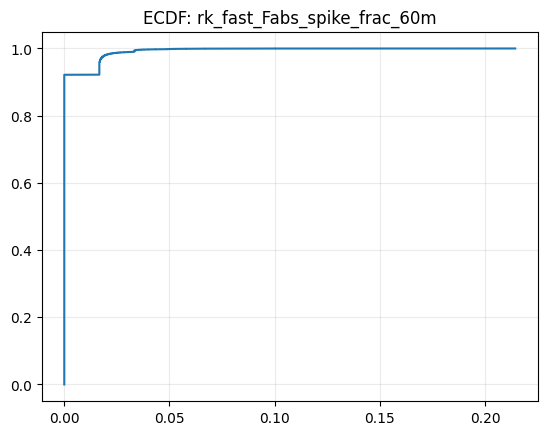

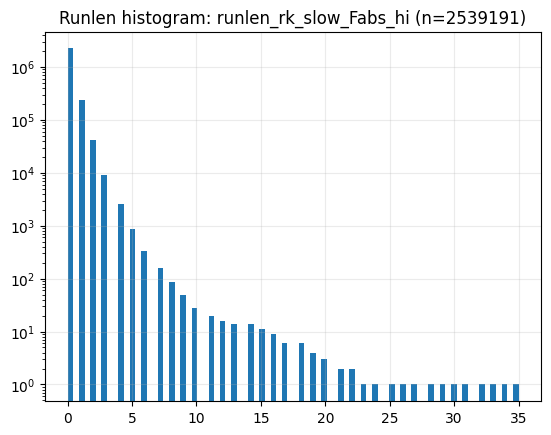

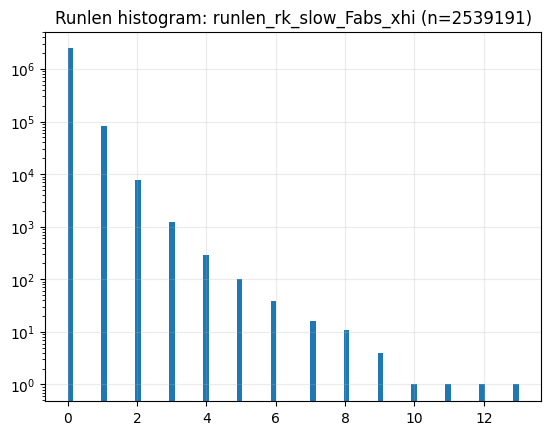

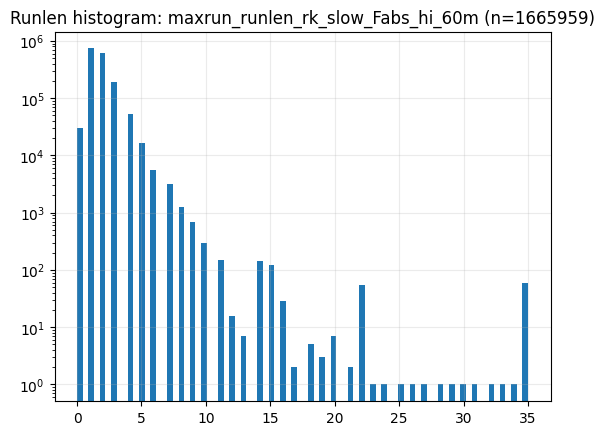

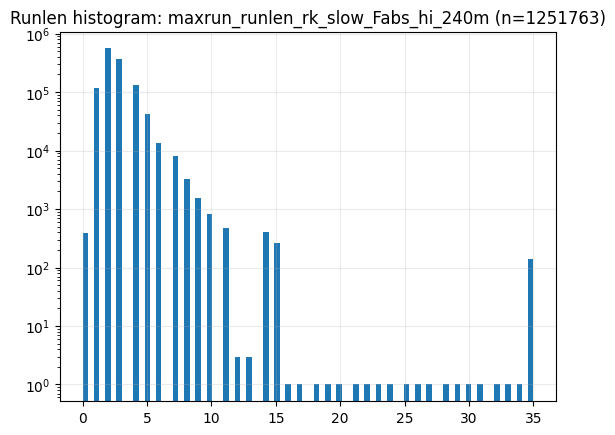

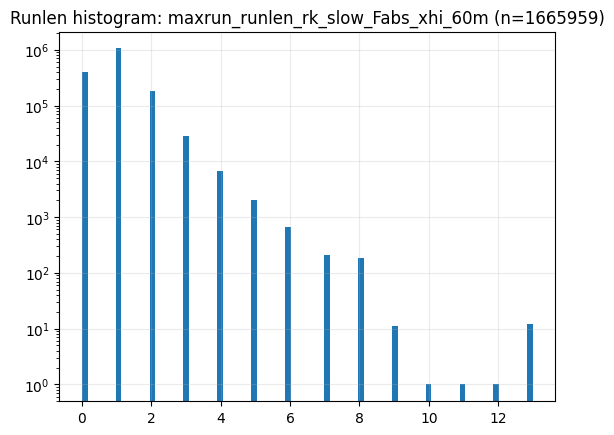

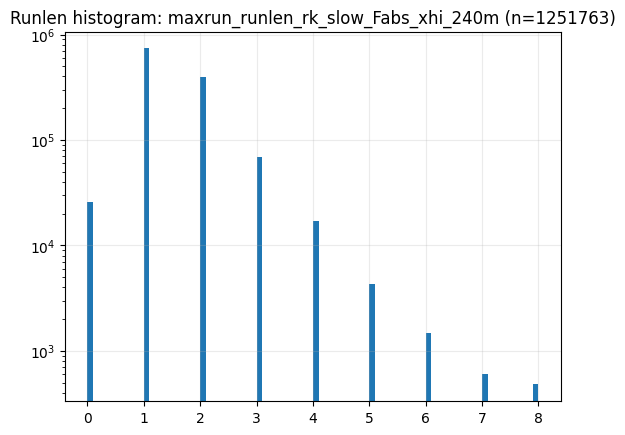

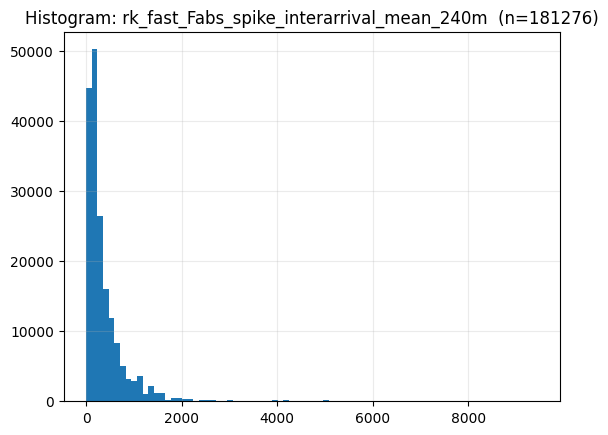

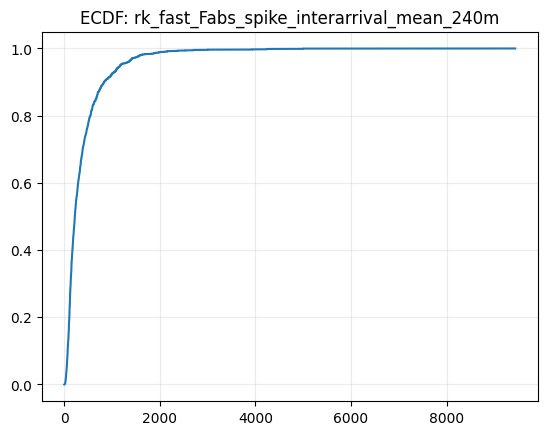

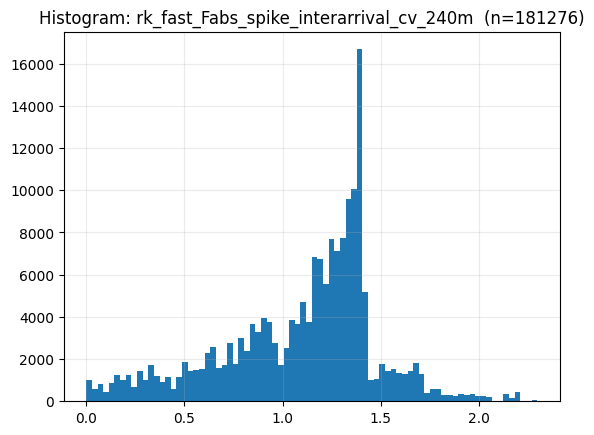

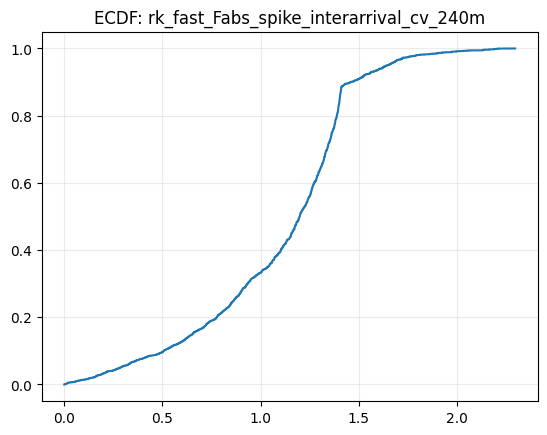

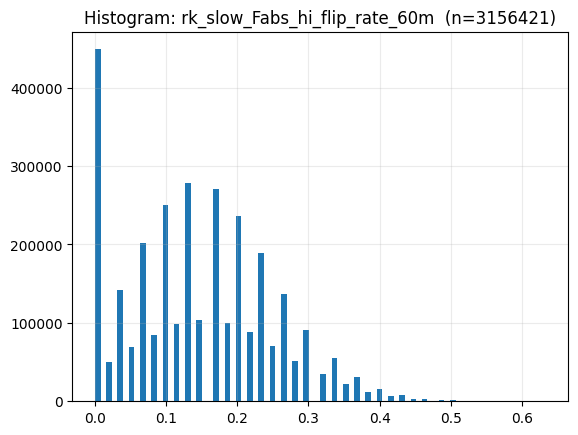

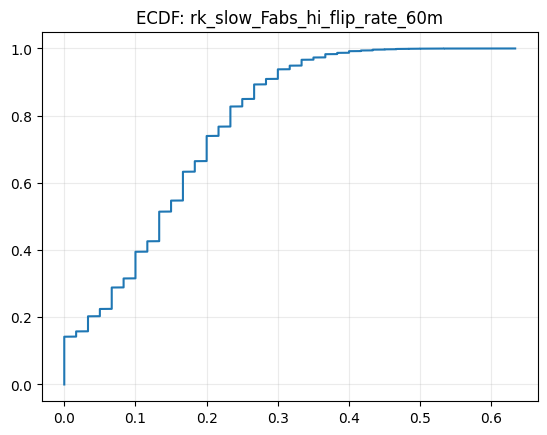

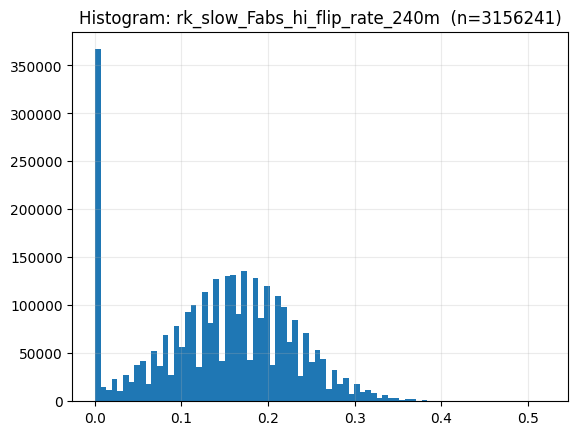

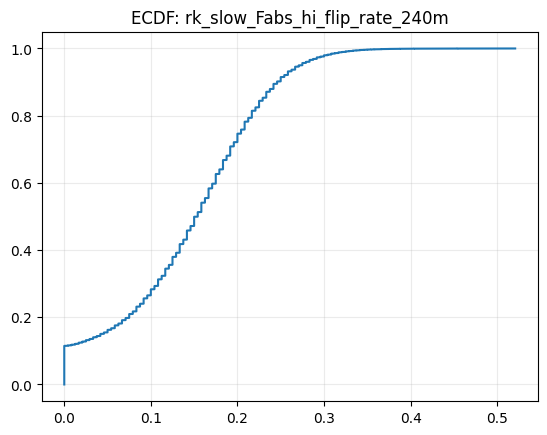

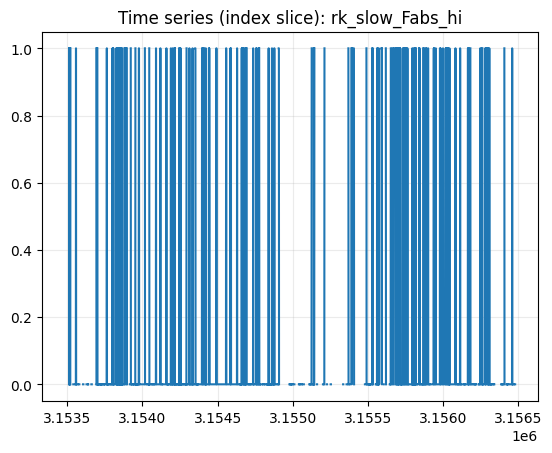

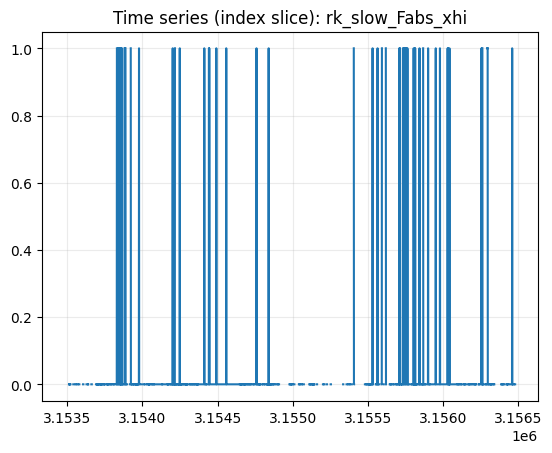

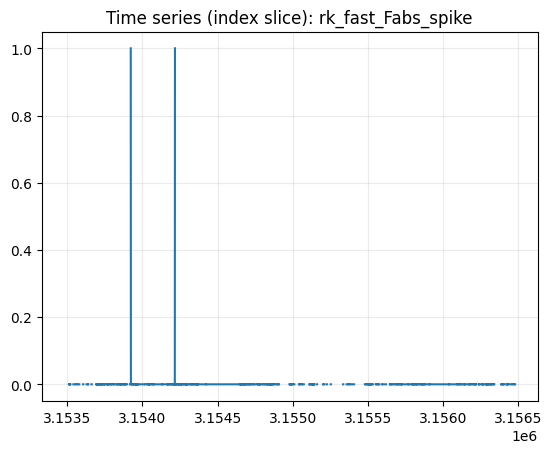

In [40]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map)

In [41]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
rk_slow_Fabs_mean_60m,0.994911,0.989193,0.983053,0.969783,0.932374,0.748706,0.449781,0.256437
rk_slow_Fabs_p90_60m,0.986024,0.973009,0.960600,0.936739,0.880267,0.665558,0.375782,0.222206
rk_slow_Fabs_mean_240m,0.999401,0.998716,0.997970,0.996328,0.991532,0.965518,0.913443,0.498115
rk_slow_Fabs_p90_240m,0.998168,0.996406,0.994702,0.991380,0.983124,0.947297,0.885291,0.467819
rk_slow_Fabs_hi_frac_60m,0.993498,0.986225,0.978452,0.961792,0.915637,0.696694,0.348282,0.192215
rk_slow_Fabs_xhi_frac_60m,0.992149,0.983417,0.974191,0.954638,0.901139,0.652838,0.262919,0.127476
rk_slow_Fabs_hi_frac_240m,0.999132,0.998151,0.997095,0.994808,0.988311,0.955143,0.892458,0.428710
rk_slow_Fabs_xhi_frac_240m,0.998807,0.997468,0.996043,0.993001,0.984533,0.942804,0.867407,0.340214
rk_fast_Fabs_spike_frac_60m,0.987363,0.974117,0.960464,0.932367,0.859368,0.551905,0.091376,0.035925


In [42]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [43]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['rk_slow_Fabs_hi', 'rk_slow_Fabs_xhi', 'rk_fast_Fabs_spike']


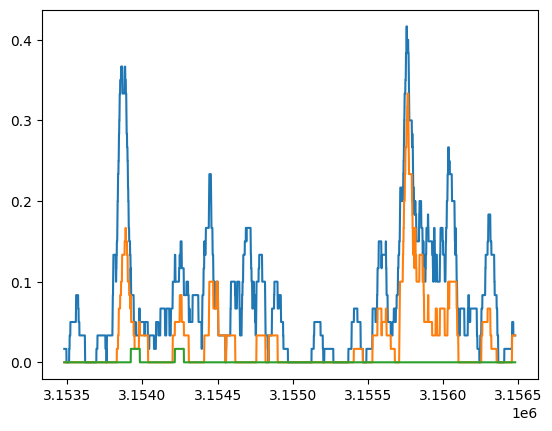

In [44]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G4_P_Persistence

In [45]:
group_key = "G4_P_Persistence"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [46]:
for abcd in ABCD_KEYS:
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_P_p90_60m,3156480,3148505,0.002527,0.0,0.839673,0.127955,0.003423,1.000000,0.450133,0.593433,0.865584,0.994184,0.999898
rk_slow_P_mean_60m,3156480,3148508,0.002526,0.0,0.478292,0.112660,0.000988,0.993561,0.232417,0.305943,0.471082,0.675821,0.772490
rk_slow_P_mean_240m,3156480,3148800,0.002433,0.0,0.478282,0.091635,0.054000,0.903635,0.268137,0.335254,0.473326,0.638869,0.712798
rk_slow_P_p90_240m,3156480,3148800,0.002433,0.0,0.851496,0.104406,0.141356,1.000000,0.524289,0.657781,0.870464,0.983812,0.998405



--- B_flag (2 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
rk_slow_P_xlo,3156480,3146752,0.003082,0.901557,0.098443,2
rk_slow_P_lo,3156480,3146752,0.003082,0.830214,0.169786,2



--- C_frac (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_P_xlo_frac_60m,3156480,3148508,0.002526,0.217258,0.098422,0.112874,0.0,1.000000,0.0,0.000000,0.066667,0.333333,0.500000
rk_slow_P_lo_frac_60m,3156480,3148508,0.002526,0.076200,0.169779,0.138615,0.0,1.000000,0.0,0.000000,0.150000,0.433333,0.600000
rk_slow_P_xlo_frac_240m,3156480,3150547,0.001880,0.087345,0.098404,0.096296,0.0,0.904167,0.0,0.000000,0.070833,0.291667,0.420833
rk_slow_P_lo_frac_240m,3156480,3150547,0.001880,0.011945,0.169767,0.115872,0.0,0.929167,0.0,0.020833,0.150000,0.391667,0.529167



--- D_struct (5 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
maxrun_runlen_rk_slow_P_lo_240m,3156480,3036701,0.037947,0.012392,3.946402,3.741538,0.0,132.000000,0.0,1.000000,3.000000,9.000000,16.000000
maxrun_runlen_rk_slow_P_lo_60m,3156480,3099568,0.018030,0.077355,2.479234,2.609772,0.0,132.000000,0.0,0.000000,2.000000,6.000000,10.000000
runlen_rk_slow_P_lo,3156480,3146752,0.003082,0.830214,0.294843,1.263274,0.0,132.000000,0.0,0.000000,0.000000,2.000000,4.000000
rk_slow_P_lo_flip_rate_240m,3156480,3156241,0.000076,0.013584,0.227409,0.117107,0.0,0.566667,0.0,0.033333,0.225000,0.420833,0.470833
rk_slow_P_lo_flip_rate_60m,3156480,3156421,0.000019,0.077051,0.227403,0.144401,0.0,0.750000,0.0,0.000000,0.233333,0.466667,0.533333


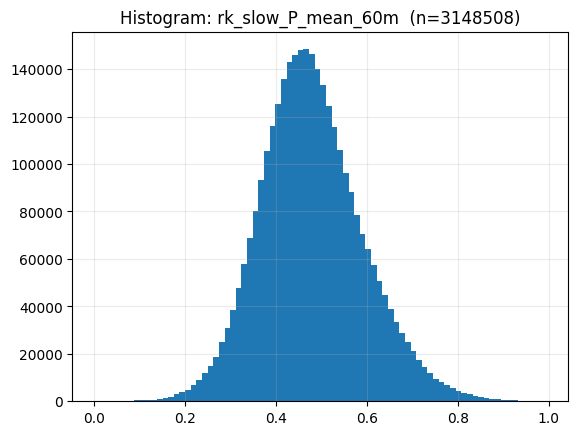

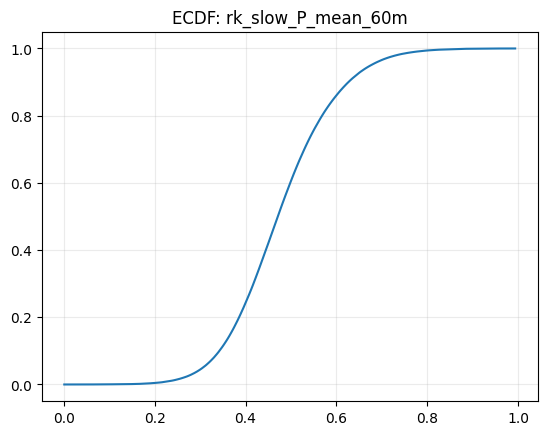

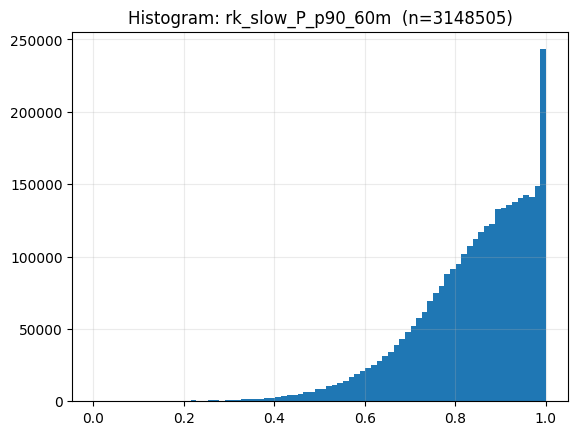

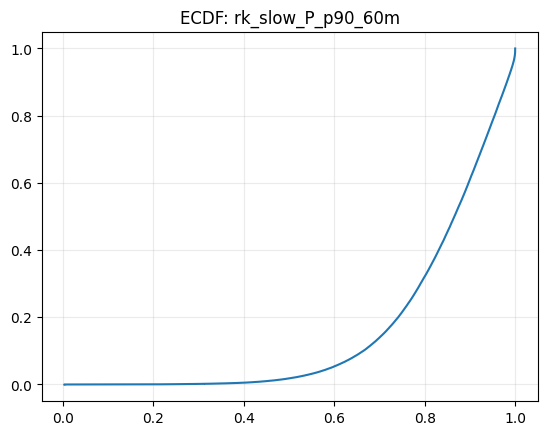

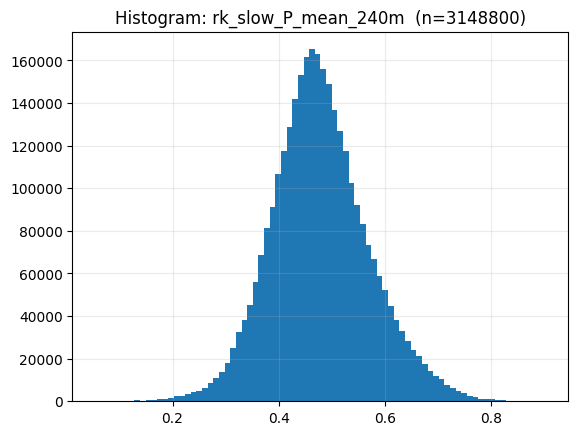

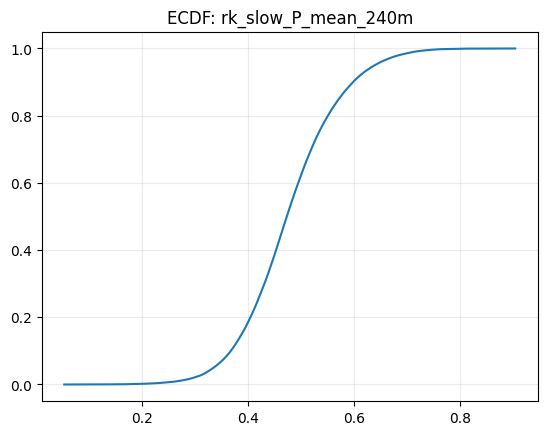

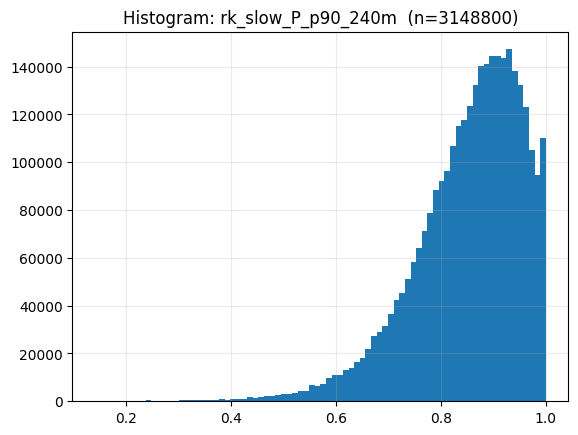

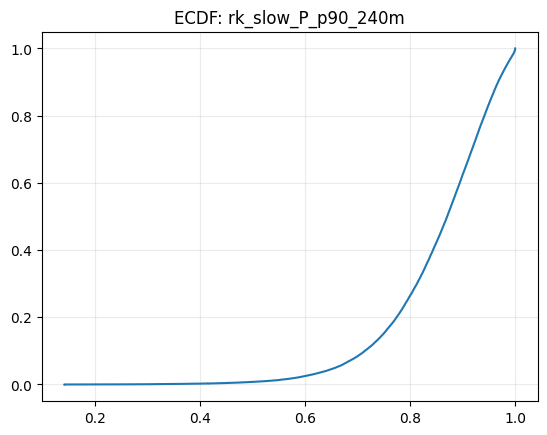

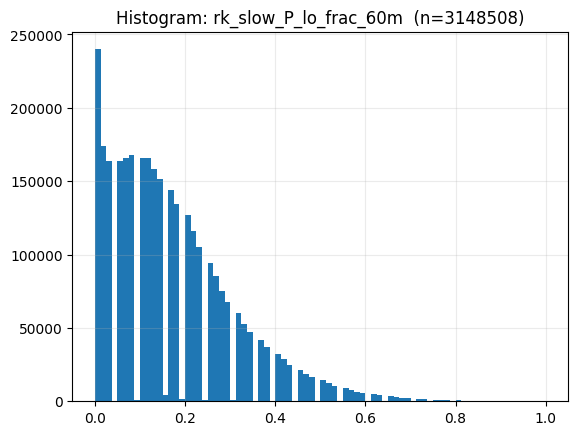

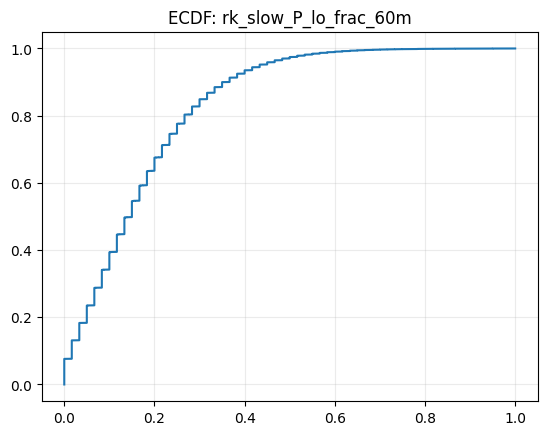

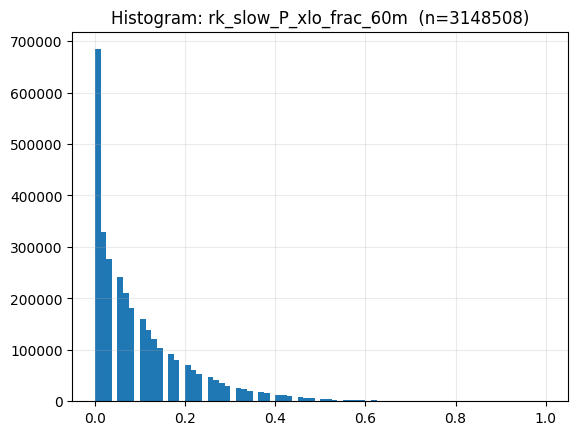

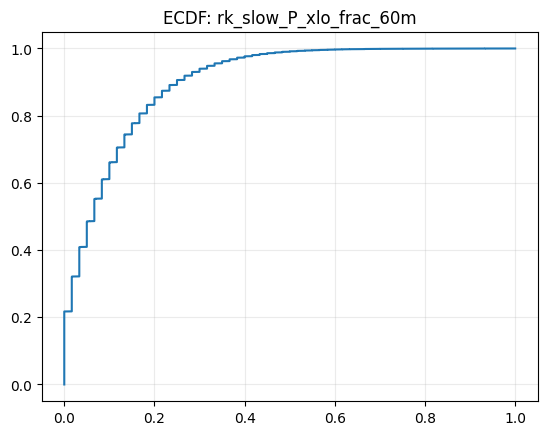

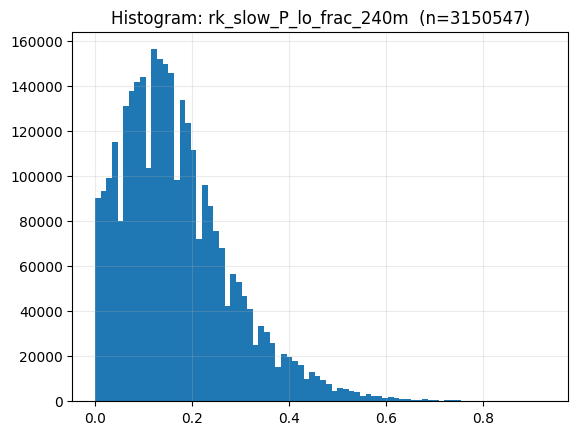

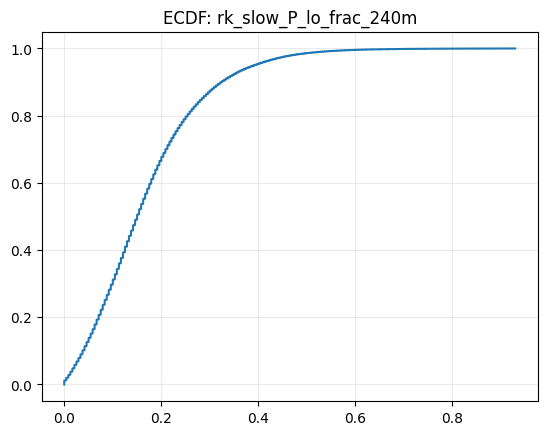

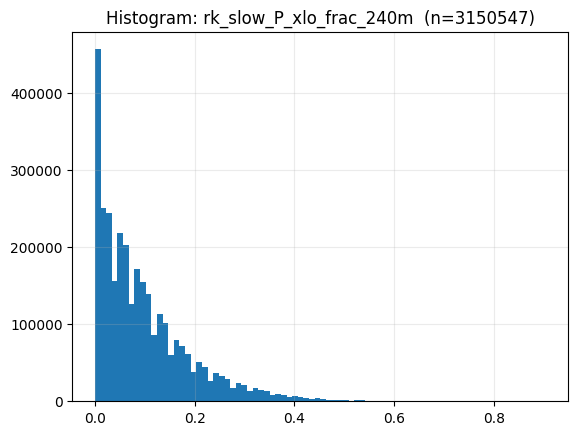

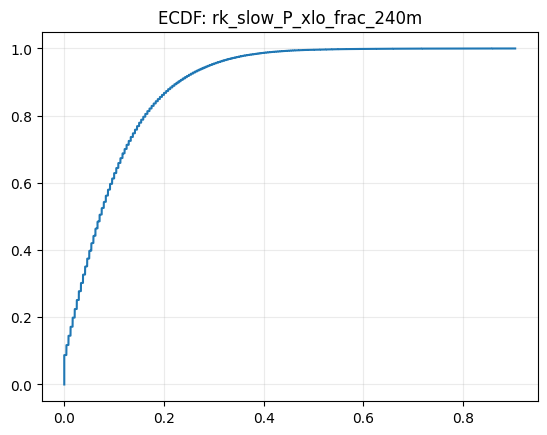

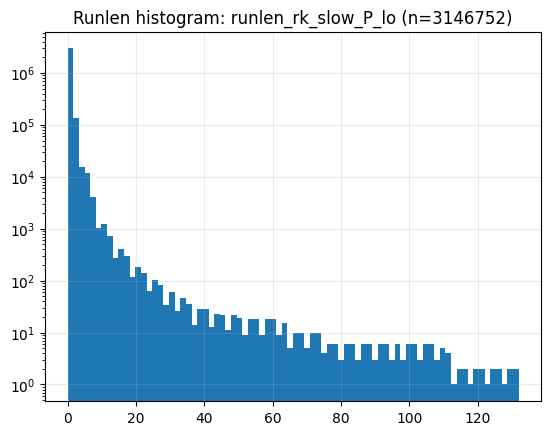

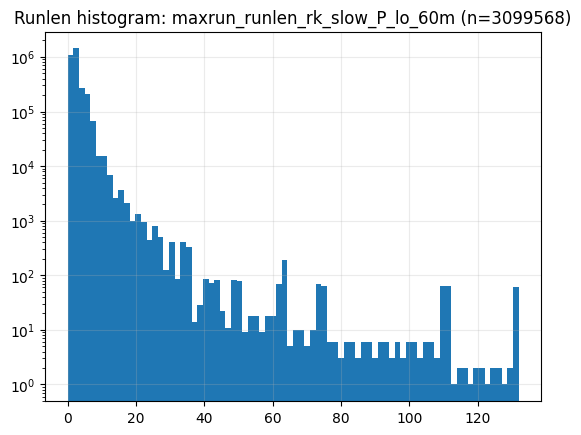

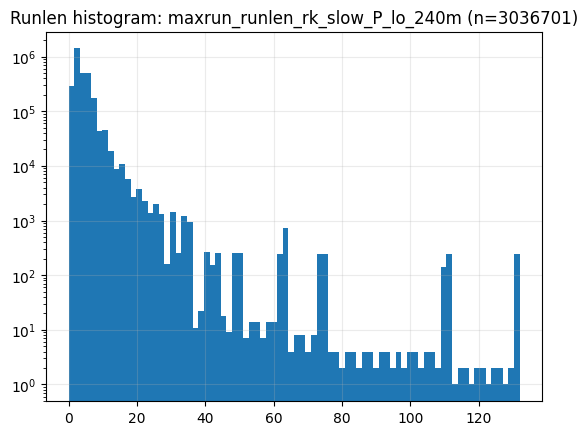

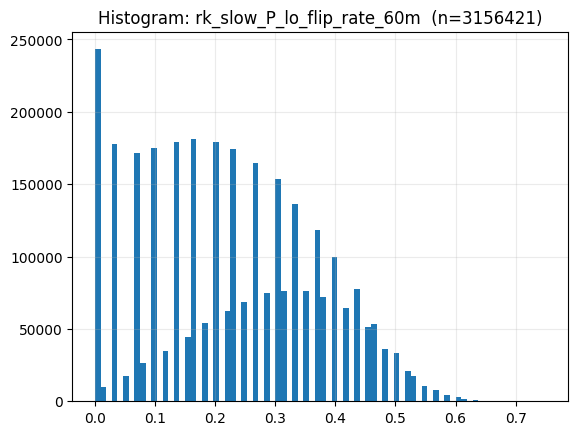

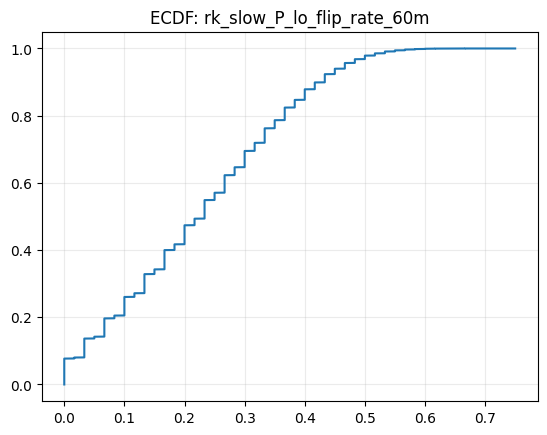

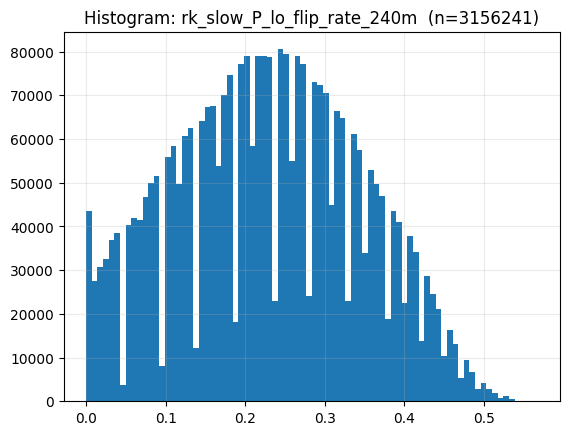

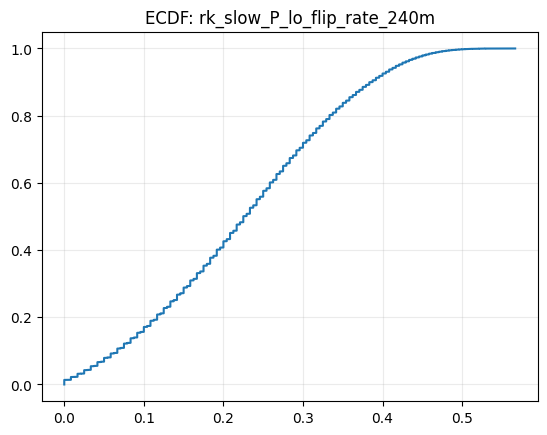

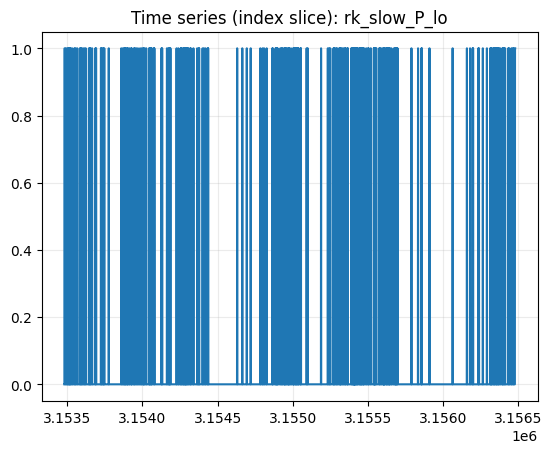

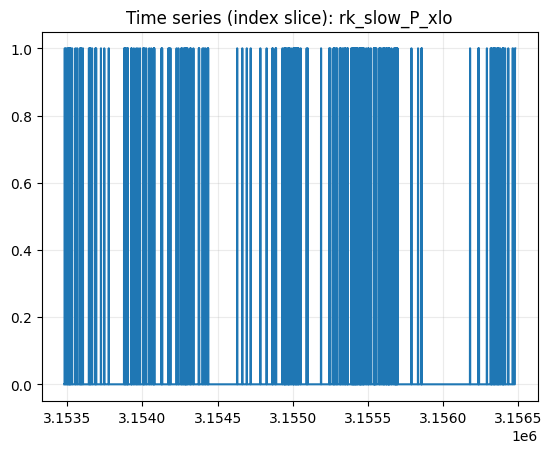

In [47]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map)

In [48]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
rk_slow_P_mean_60m,0.998627,0.996732,0.994429,0.988815,0.970020,0.853205,0.643144,0.343503
rk_slow_P_p90_60m,0.992677,0.985270,0.977832,0.962801,0.924331,0.763998,0.542590,0.325968
rk_slow_P_mean_240m,0.999863,0.999662,0.999408,0.998763,0.996448,0.979534,0.937992,0.559312
rk_slow_P_p90_240m,0.999217,0.998388,0.997513,0.995636,0.990193,0.959944,0.900879,0.507694
rk_slow_P_lo_frac_60m,0.998160,0.995925,0.993389,0.987562,0.969407,0.864750,0.679561,0.411929
rk_slow_P_xlo_frac_60m,0.998273,0.996201,0.993860,0.988498,0.971875,0.877248,0.710267,0.469886
rk_slow_P_lo_frac_240m,0.999828,0.999608,0.999349,0.998725,0.996621,0.982167,0.947328,0.622886
rk_slow_P_xlo_frac_240m,0.999845,0.999650,0.999421,0.998871,0.997027,0.984483,0.954442,0.675297
runlen_rk_slow_P_lo,0.815295,0.732574,0.684729,0.627578,0.543484,0.365824,0.221675,0.078677


In [49]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [50]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['rk_slow_P_lo', 'rk_slow_P_xlo']


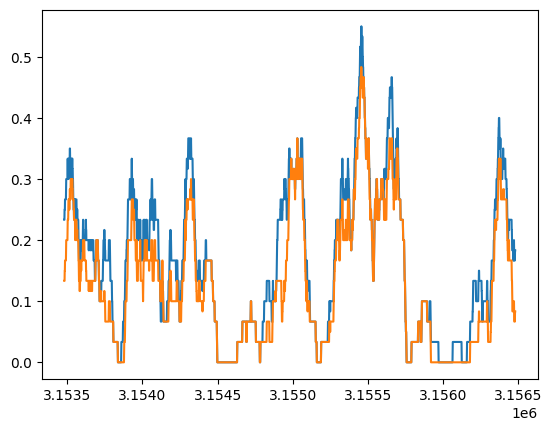

In [51]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## G5_C_Concentration

In [52]:
group_key = "G5_C_Concentration"
quantiles=(0.01,0.05,0.5,0.95,0.99)
bins=80
lags=(1,2,3,5,10,30,60,240)
clip_map=None

In [53]:
for abcd in ABCD_KEYS:
        cols = _present_cols(df, REGISTRY[group_key][abcd])
        if not cols:
            continue
        print(f"\n--- {abcd} ({len(cols)} cols) ---")
        display(summarize_distribution(df, cols, quantiles=quantiles))


--- A_state (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_C_mean_60m,3156480,3126053,0.009640,0.0,0.476848,0.096967,0.018013,0.933915,0.234209,0.317383,0.477492,0.632885,0.709043
rk_slow_C_p90_60m,3156480,3126053,0.009640,0.0,0.869457,0.118460,0.035564,0.999999,0.460634,0.632917,0.902419,0.992029,0.998622
rk_slow_C_mean_240m,3156480,3132267,0.007671,0.0,0.476764,0.078594,0.052601,0.878765,0.269661,0.347619,0.477993,0.601343,0.662357
rk_slow_C_p90_240m,3156480,3132267,0.007671,0.0,0.879212,0.094838,0.098459,0.999928,0.537846,0.698232,0.901676,0.983085,0.994623



--- B_flag (2 cols) ---


,n,n_nonnull,nan_frac,zero_frac,flag_mean,unique
col,,,,,,
rk_slow_C_xhi,3156480,3088725,0.021465,0.946880,0.053120,2
rk_slow_C_hi,3156480,3088725,0.021465,0.892632,0.107368,2



--- C_frac (4 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
rk_slow_C_xhi_frac_60m,3156480,3126053,0.00964,0.172005,0.053388,0.050629,0.0,0.650000,0.000000,0.000000,0.035714,0.150000,0.216667
rk_slow_C_hi_frac_60m,3156480,3126053,0.00964,0.053003,0.107776,0.078259,0.0,0.800000,0.000000,0.000000,0.100000,0.250000,0.350000
rk_slow_C_xhi_frac_240m,3156480,3146128,0.00328,0.023622,0.053440,0.037947,0.0,0.485232,0.000000,0.004167,0.045833,0.125000,0.175000
rk_slow_C_hi_frac_240m,3156480,3146128,0.00328,0.005108,0.107821,0.060470,0.0,0.687764,0.004167,0.025000,0.100000,0.216667,0.287500



--- D_struct (5 cols) ---


,n,n_nonnull,nan_frac,zero_frac,mean,std,min,max,q01,q05,q50,q95,q99
col,,,,,,,,,,,,,
maxrun_runlen_rk_slow_C_hi_240m,3156480,2607893,0.173797,0.006162,2.480248,1.246971,0.0,16.000000,1.000000,1.000000,2.000000,5.000000,7.000000
maxrun_runlen_rk_slow_C_hi_60m,3156480,2781764,0.118713,0.058753,1.641097,1.036080,0.0,16.000000,0.000000,0.000000,1.000000,3.000000,5.000000
runlen_rk_slow_C_hi,3156480,3088725,0.021465,0.892632,0.134333,0.440712,0.0,16.000000,0.000000,0.000000,0.000000,1.000000,2.000000
rk_slow_C_hi_flip_rate_240m,3156480,3156241,0.000076,0.008188,0.168931,0.082919,0.0,0.554167,0.008333,0.041667,0.162500,0.316667,0.383333
rk_slow_C_hi_flip_rate_60m,3156480,3156421,0.000019,0.056070,0.168924,0.107583,0.0,0.683333,0.000000,0.000000,0.166667,0.366667,0.450000


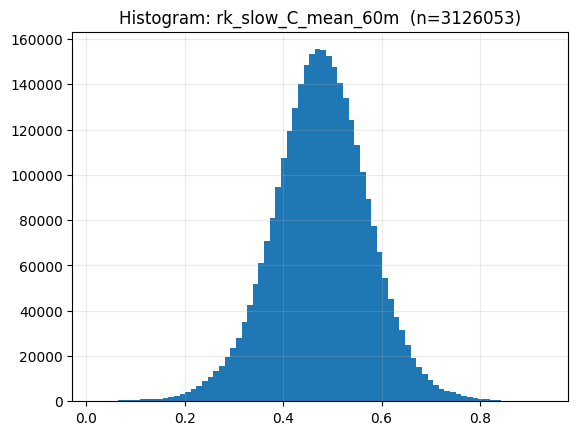

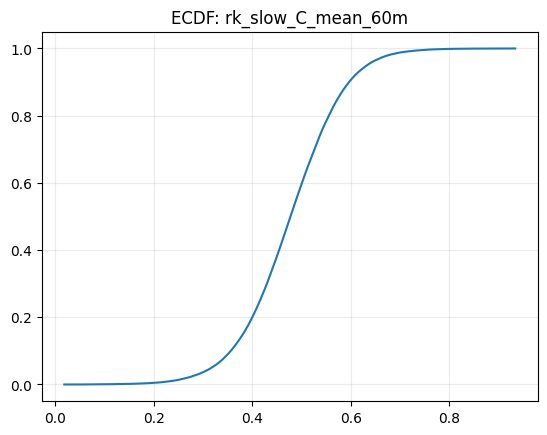

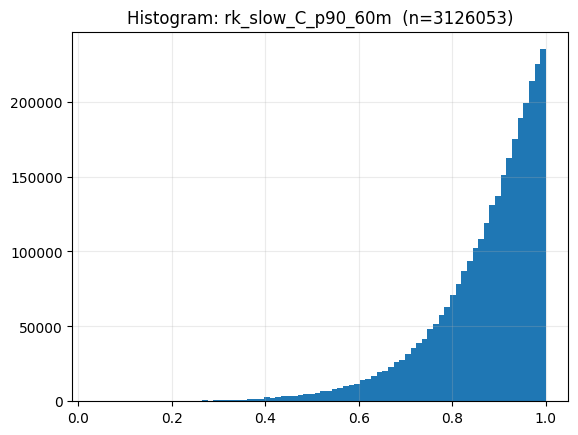

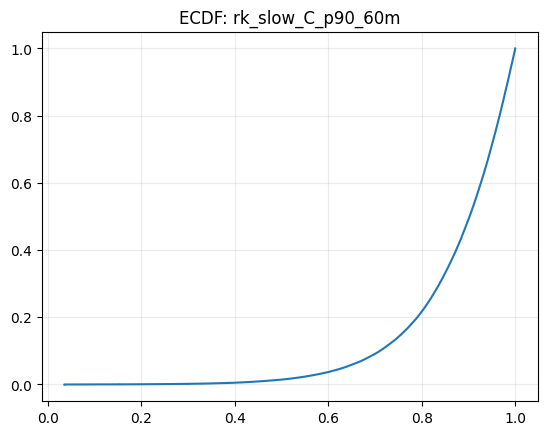

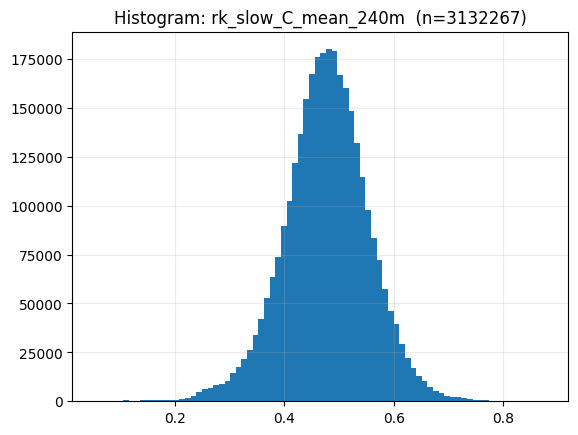

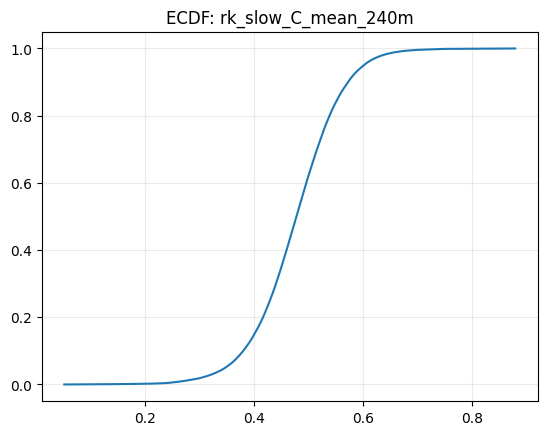

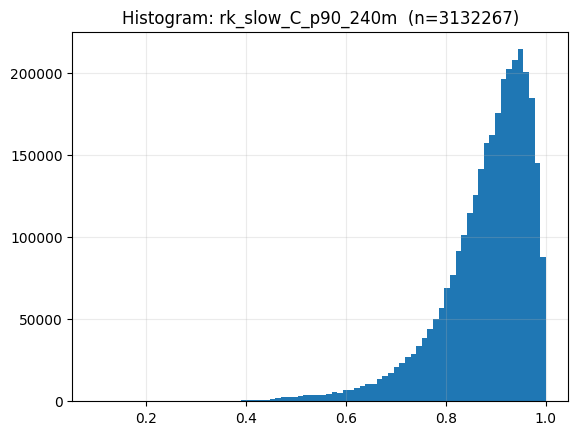

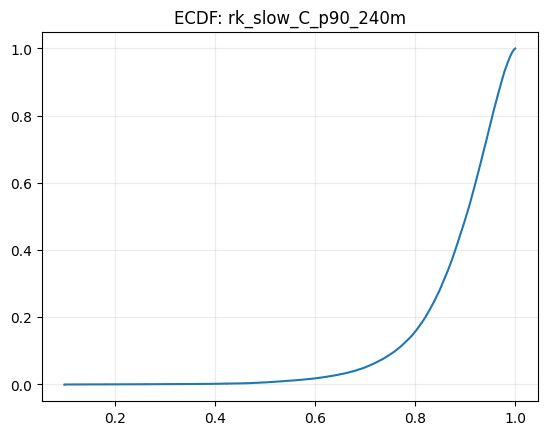

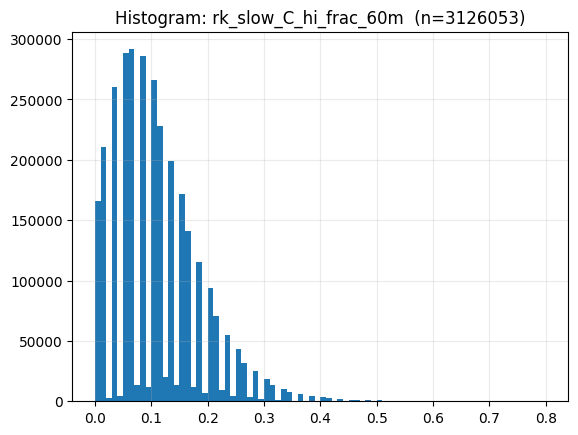

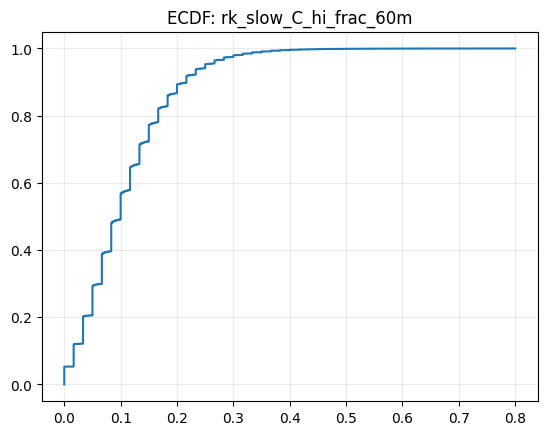

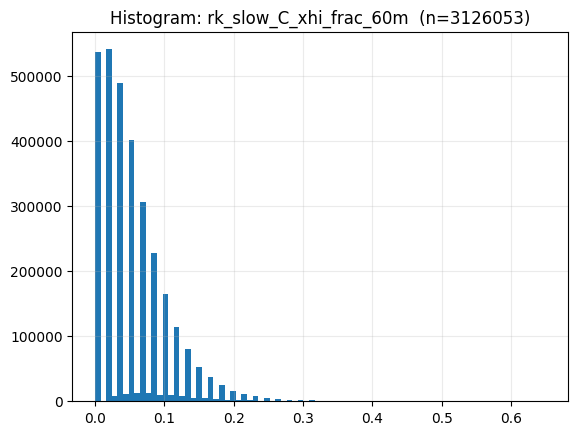

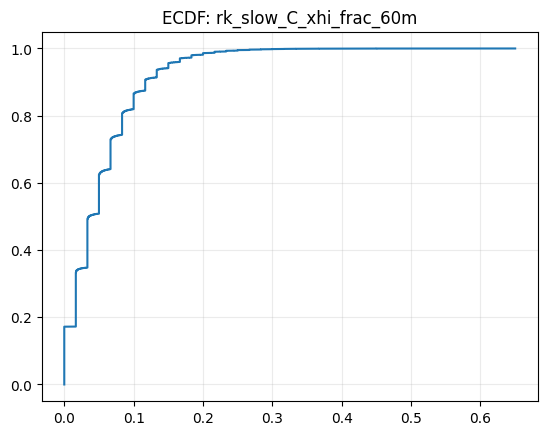

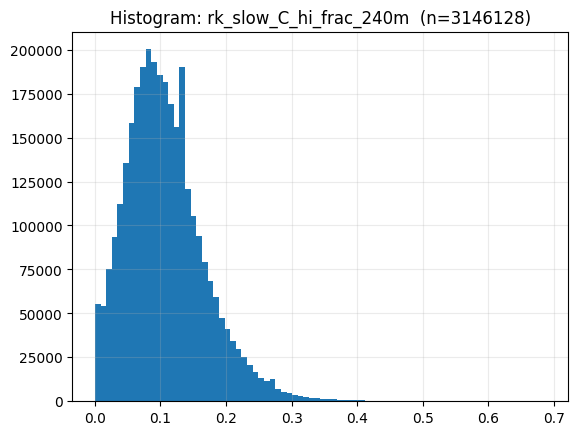

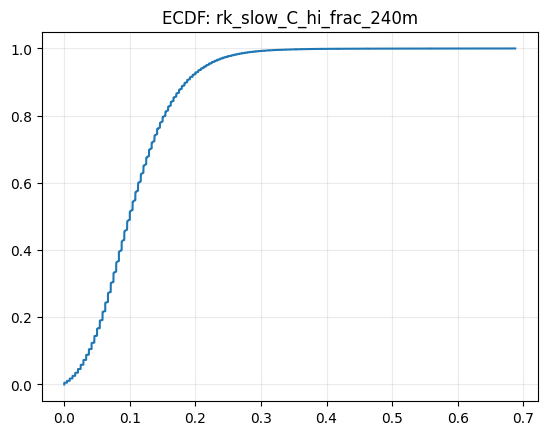

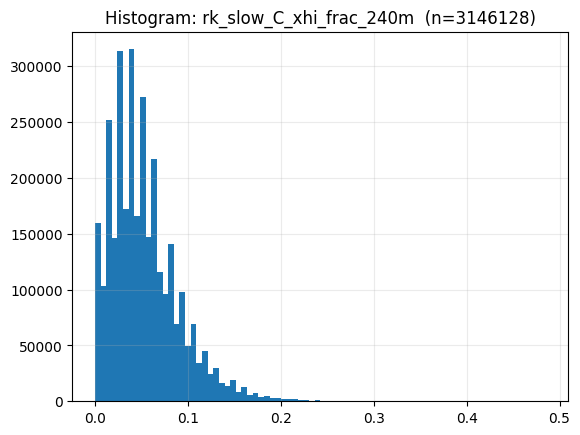

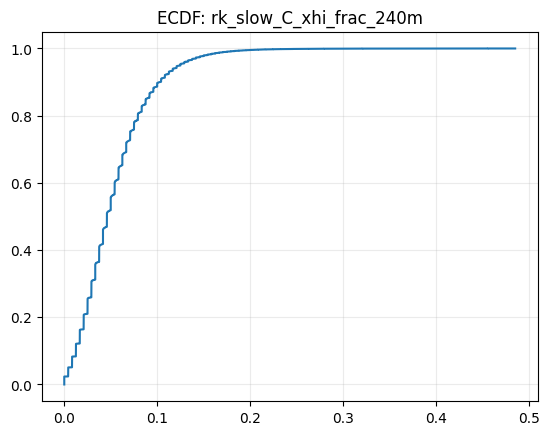

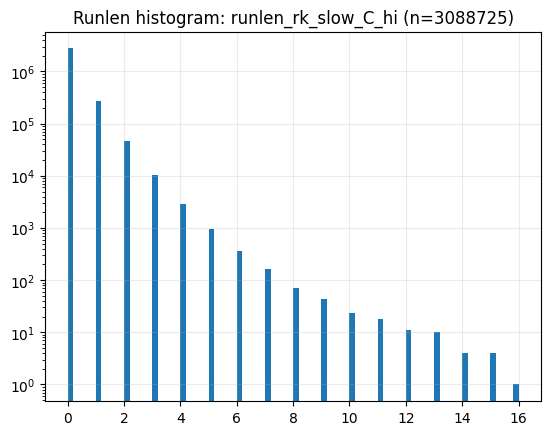

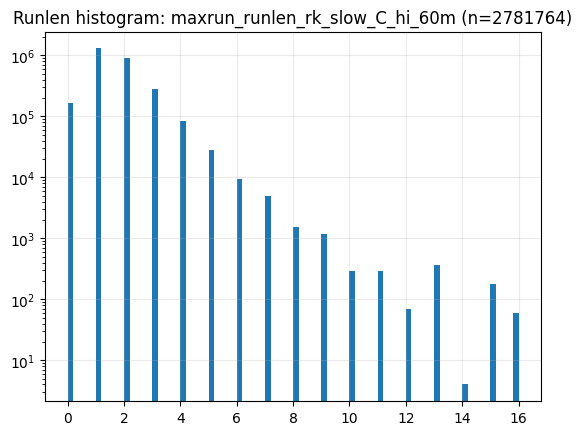

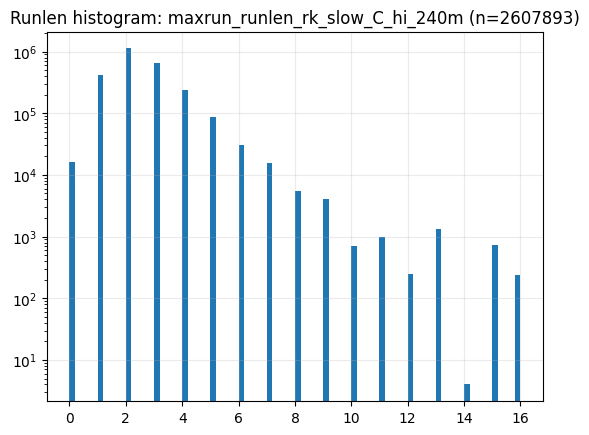

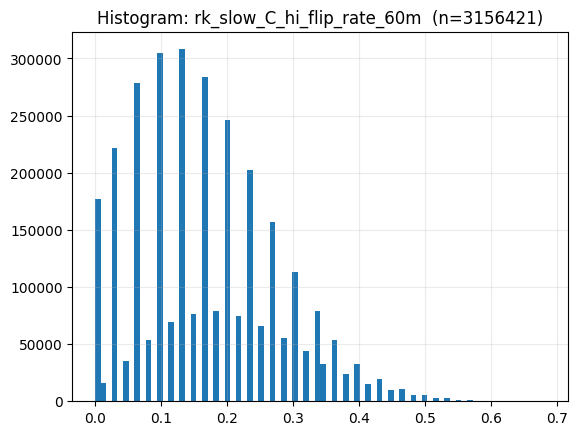

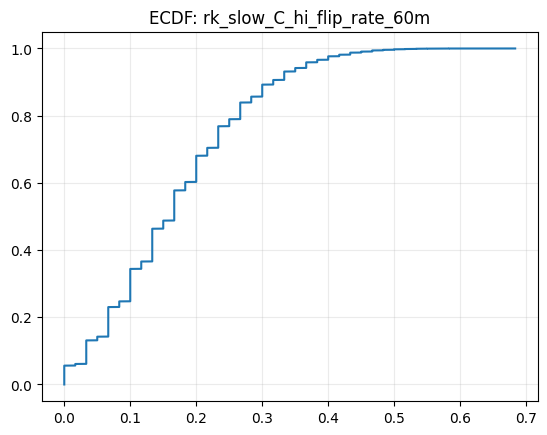

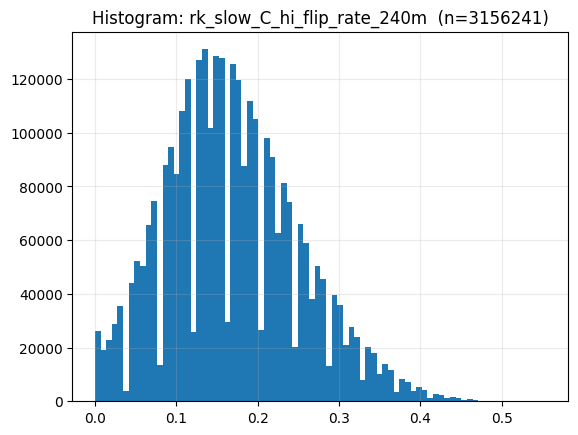

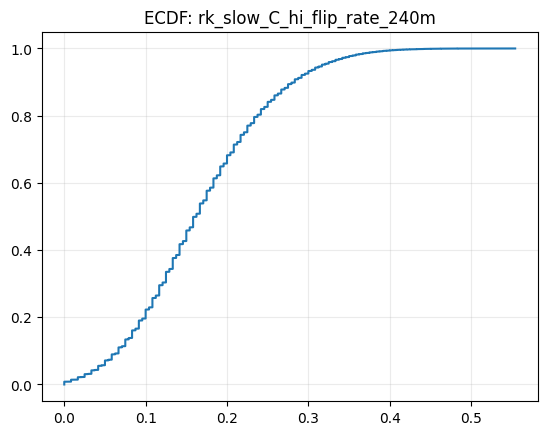

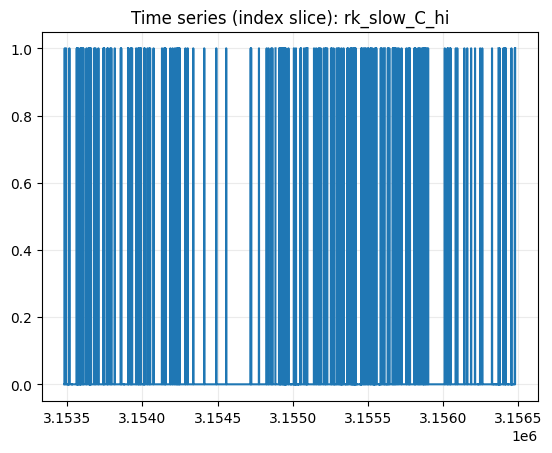

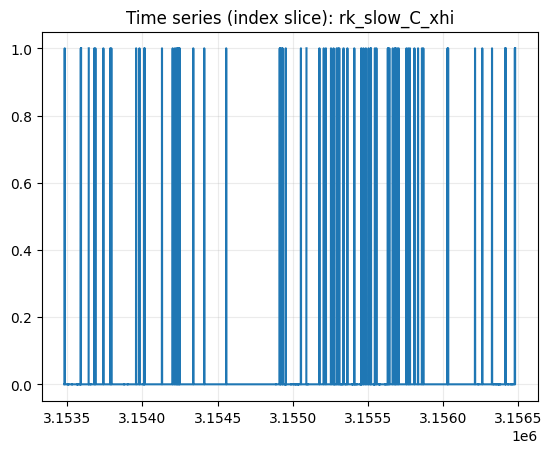

In [54]:
step2_plots_by_group(df, group_key, bins=bins, clip_map=clip_map)

In [55]:
pr = step3_persistence_by_group(df, group_key, lags=lags, include_flags=False)
if pr is not None:
  display(pr)

,acf_1,acf_2,acf_3,acf_5,acf_10,acf_30,acf_60,acf_240
col,,,,,,,,
rk_slow_C_mean_60m,0.997855,0.995208,0.992189,0.985236,0.963670,0.841394,0.627233,0.364620
rk_slow_C_p90_60m,0.992313,0.984962,0.977808,0.963781,0.928810,0.783789,0.579507,0.354509
rk_slow_C_mean_240m,0.999789,0.999517,0.999198,0.998433,0.995898,0.979027,0.939509,0.588796
rk_slow_C_p90_240m,0.999166,0.998356,0.997547,0.995900,0.991500,0.969063,0.924238,0.584717
rk_slow_C_hi_frac_60m,0.995681,0.990910,0.985807,0.974797,0.943643,0.789412,0.533744,0.314909
rk_slow_C_xhi_frac_60m,0.994512,0.988582,0.982349,0.969141,0.932833,0.760336,0.479770,0.283680
rk_slow_C_hi_frac_240m,0.999536,0.999013,0.998443,0.997184,0.993439,0.972356,0.927863,0.553487
rk_slow_C_xhi_frac_240m,0.999375,0.998688,0.997956,0.996377,0.991858,0.967903,0.919716,0.529307
runlen_rk_slow_C_hi,0.309479,0.162934,0.117087,0.089392,0.072840,0.052363,0.041703,0.027439


In [56]:
flip = step4_flip_sanity_by_group(df, group_key, L=60)

In [57]:
print("Computed flip series for flags:", list(flip.keys()))

Computed flip series for flags: ['rk_slow_C_hi', 'rk_slow_C_xhi']


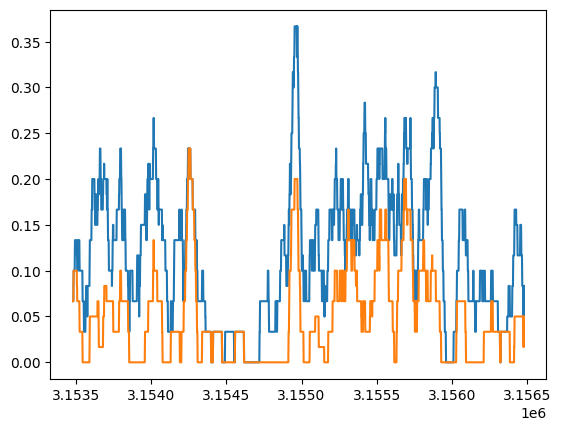

In [58]:
for flag in list(flip.keys()):
  flip[flag].iloc[-3000:].plot()

## Feature Grouping (Language Compression)
ลด dimensionality ทางความคิด

หลักการจัดกลุ่ม (Rules)

เราจะไม่จัดกลุ่มตาม:
- สูตร
- ชื่อคอลัมน์
- fast/slow

แต่จัดตาม:
- คำถามเชิงพฤติกรรมที่ feature ตอบ

# Hypothesis Testing

## Utilities: สร้าง future windows (ahead) ด้วย rolling แบบ shift

In [4]:
import polars as pl

def _bars(L_minutes: int, bar_seconds: int = 60) -> int:
    return max(1, int((L_minutes * 60 + bar_seconds - 1) // bar_seconds))

def add_future_mean(
    df: pl.DataFrame,
    *,
    src_col: str,
    out_col: str,
    horizon_minutes: int,
    bar_seconds: int = 60,
    min_periods: int | None = None,
) -> pl.DataFrame:
    """
    future_mean(t) = mean(src_col over t+1 .. t+H)
    (uses rolling on shifted series)
    """
    w = _bars(horizon_minutes, bar_seconds)
    if min_periods is None:
        min_periods = w

    return df.with_columns(
        pl.col(src_col)
        .shift(-1)  # start from next bar
        .rolling_mean(window_size=w, min_periods=min_periods)
        .alias(out_col)
    )

def add_future_quantile(
    df: pl.DataFrame,
    *,
    src_col: str,
    out_col: str,
    horizon_minutes: int,
    q: float,
    bar_seconds: int = 60,
    min_periods: int | None = None,
    interpolation: str = "nearest",
) -> pl.DataFrame:
    """
    future_q(t) = quantile(src_col over t+1 .. t+H)
    """
    w = _bars(horizon_minutes, bar_seconds)
    if min_periods is None:
        min_periods = w

    return df.with_columns(
        pl.col(src_col)
        .shift(-1)
        .rolling_quantile(q, window_size=w, min_periods=min_periods, interpolation=interpolation)
        .alias(out_col)
    )

## Utility: สรุป distribution แยกตาม condition

In [20]:
def summarize_by_condition(
    df: pl.DataFrame,
    *,
    cond_col: str,          # boolean or 0/1
    value_cols: list[str],  # outcomes
) -> pl.DataFrame:
    """
    Returns a long table:
    cond, metric, mean, std, p10, p50, p90, count, null_count
    """
    # normalize cond to 0/1
    d0 = df.with_columns(
        pl.col(cond_col).cast(pl.Int8).fill_null(0).alias("__cond")
    )

    out = []
    for c in value_cols:
        out.append(
            d0.group_by("__cond")
              .agg([
                  pl.count().alias("rows"),
                  pl.col(c).count().alias("count"),
                  pl.col(c).null_count().alias("null_count"),
                  pl.col(c).mean().alias("mean"),
                  pl.col(c).std().alias("std"),
                  pl.col(c).quantile(0.10, "nearest").alias("p10"),
                  pl.col(c).quantile(0.50, "nearest").alias("p50"),
                  pl.col(c).quantile(0.90, "nearest").alias("p90"),
              ])
              .with_columns(pl.lit(c).alias("metric"))
        )

    return pl.concat(out, how="vertical").rename({"__cond": "cond"}).select(
        ["metric", "cond", "rows", "count", "null_count", "mean", "std", "p10", "p50", "p90"]
    )

## KS test

In [6]:
def ks_test_cond_vs_base(
    df: pl.DataFrame,
    *,
    cond_col: str,
    value_col: str,
):
    """
    KS test between cond=1 vs cond=0 for a single value_col.
    """
    try:
        from scipy.stats import ks_2samp
    except Exception as e:
        raise RuntimeError("Install scipy to use KS test") from e

    x1 = df.filter(pl.col(cond_col) == 1).select(value_col).to_series().drop_nulls().to_list()
    x0 = df.filter(pl.col(cond_col) == 0).select(value_col).to_series().drop_nulls().to_list()

    if len(x1) < 50 or len(x0) < 50:
        return {"value_col": value_col, "n1": len(x1), "n0": len(x0), "ks_stat": None, "pvalue": None}

    stat, p = ks_2samp(x1, x0)
    return {"value_col": value_col, "n1": len(x1), "n0": len(x0), "ks_stat": stat, "pvalue": p}

## Test

In [7]:
BAR_SECONDS = 60
H = 60              # horizon minutes for forward outcomes (ปรับได้: 30/60/240)
MINP = 30           # min_periods for forward outcomes (ปรับตาม H)
Q_TAIL = 0.90       # tail quantile

In [8]:
df = df.with_columns([
    pl.col("signed_quote").abs().alias("abs_signed_quote"),
    pl.col("imbalance").abs().alias("abs_imbalance"),
    pl.col("ret_cc").abs().alias("abs_ret_cc"),
    pl.col("ret_inbar").abs().alias("abs_ret_inbar"),
])

results = {}

# Standalone-Group Hypothesis Test

## 🧠 H1 — Activity Group Validity

**Group:** Activity & Participation

**Condition:**

* `rk_slow_A_hi == 1`
  หรือ
* `rk_slow_A_hi_frac_240m > 0.5`

**Outcome:**

* future `trade_count` (30–120m)
* future `active_ms`

**Hypothesis:**

> High activity regime
> → future participation distribution shifts upward

**ถ้าไม่เกิด:**
→ A group ไม่ capture “participation persistence”

In [38]:
df = df.with_columns((pl.col("rk_slow_A_hi") == 1).cast(pl.Int8).alias("cond_H1_A_hi"))
df = add_future_mean(df, src_col="trade_count", out_col=f"H1_fwd_trade_count_mean_{H}m", horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(df, src_col="active_ms",   out_col=f"H1_fwd_active_ms_mean_{H}m",   horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(df, src_col="A_t",         out_col=f"H1_fwd_A_t_mean_{H}m",         horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)

results["H1"] = summarize_by_condition(
    df,
    cond_col="cond_H1_A_hi",
    value_cols=[f"H1_fwd_trade_count_mean_{H}m", f"H1_fwd_active_ms_mean_{H}m", f"H1_fwd_A_t_mean_{H}m"]
)

/tmp/ipython-input-3038258366.py:26: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=w, min_periods=min_periods)
/tmp/ipython-input-1981444484.py:21: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("rows"),


In [39]:
results["H1"]

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H1_fwd_trade_count_mean_60m""",1,252586,252540,46,1215.659426,1332.282452,242.516667,838.516667,2607.916667
"""H1_fwd_trade_count_mean_60m""",0,2903894,2901576,2318,497.979186,473.156081,123.516667,356.883333,1025.366667
"""H1_fwd_active_ms_mean_60m""",0,2903894,2901424,2470,291.26892,225.477952,96.95,227.85,555.65
"""H1_fwd_active_ms_mean_60m""",1,252586,252540,46,663.45671,576.897607,182.016667,509.516667,1306.1
"""H1_fwd_A_t_mean_60m""",1,252586,252540,46,0.011058,0.009615,0.003034,0.008492,0.021768
"""H1_fwd_A_t_mean_60m""",0,2903894,2901424,2470,0.004854,0.003758,0.001616,0.003797,0.009261


## 💥 H2 — Volatility Group Validity

**Group:** Volatility Regime

**Condition:**

* `rk_slow_V_xhi == 1`

**Outcome:**

* future `realized_var_inbar`
* future `rk_slow_V_mean_60m`

**Hypothesis:**

> Extreme volatility regime
> → volatility remains elevated (fat right tail)

**ถ้าไม่เกิด:**
→ V group เป็น reactive metric เท่านั้น

In [40]:
df = df.with_columns((pl.col("rk_slow_V_xhi") == 1).cast(pl.Int8).alias("cond_H2_V_xhi"))
df = add_future_mean(df, src_col="realized_var_inbar", out_col=f"H2_fwd_RV_mean_{H}m", horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_quantile(df, src_col="V_t", out_col=f"H2_fwd_V_p{int(Q_TAIL*100)}_{H}m", horizon_minutes=H, q=Q_TAIL, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(df, src_col="rk_slow_V_mean_60m", out_col=f"H2_fwd_rkVmean60_mean_{H}m", horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)

results["H2"] = summarize_by_condition(
    df,
    cond_col="cond_H2_V_xhi",
    value_cols=[f"H2_fwd_RV_mean_{H}m", f"H2_fwd_V_p{int(Q_TAIL*100)}_{H}m", f"H2_fwd_rkVmean60_mean_{H}m"]
)

/tmp/ipython-input-3038258366.py:26: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=w, min_periods=min_periods)
/tmp/ipython-input-3038258366.py:51: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_quantile(q, window_size=w, min_periods=min_periods, interpolation=interpolation)
/tmp/ipython-input-1981444484.py:21: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("rows"),


In [41]:
results["H2"]

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H2_fwd_RV_mean_60m""",0,3041975,3039535,2440,0.000002,0.000101,1.4248e-8,2.0769e-7,0.000002
"""H2_fwd_RV_mean_60m""",1,114505,114429,76,0.000057,0.00065,1.3740e-7,0.000002,0.000035
"""H2_fwd_V_p90_60m""",0,3041975,3039532,2443,0.000992,0.001717,0.000156,0.000588,0.002096
"""H2_fwd_V_p90_60m""",1,114505,114429,76,0.004238,0.011421,0.000411,0.001812,0.008394
"""H2_fwd_rkVmean60_mean_60m""",1,114505,114407,98,0.590009,0.161443,0.403971,0.561097,0.833348
"""H2_fwd_rkVmean60_mean_60m""",0,3041975,3034545,7430,0.46233,0.103145,0.350344,0.447173,0.595495


## 🌊 H3 — Flow Stress Group Validity

**Group:** Flow Intensity & Stress

**Condition:**

* `rk_slow_Fabs_xhi == 1`

**Outcome:**

* future `imbalance`
* future `signed_quote` magnitude

**Hypothesis:**

> Flow stress regime
> → capital pressure persists short-term

**ถ้าไม่เกิด:**
→ Fabs group ไม่ใช่ stress proxy

In [24]:
df = df.with_columns(
    (pl.col("rk_slow_Fabs_xhi") == 1)
    .cast(pl.Int8).fill_null(0)
    .alias("cond_H3_Fabs_xhi")
)

df = add_future_mean(df, src_col="abs_signed_quote", out_col=f"H3_fwd_abs_signed_quote_mean_{H}m", horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(df, src_col="abs_imbalance",    out_col=f"H3_fwd_abs_imbalance_mean_{H}m",    horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(df, src_col="A_t",             out_col=f"H3_fwd_A_mean_{H}m",                horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(
    df,
    src_col="rk_fast_I_spike",
    out_col="H3_fwd_I_spike_rate_60m",
    horizon_minutes=H,
    min_periods=MINP,
)

df = add_future_mean(
    df,
    src_col="I_t",
    out_col="H3_fwd_I_mean_60m",
    horizon_minutes=H,
    min_periods=MINP,
)

results["H3"] = summarize_by_condition(
    df,
    cond_col="cond_H3_Fabs_xhi",
    value_cols=[f"H3_fwd_abs_signed_quote_mean_{H}m", f"H3_fwd_abs_imbalance_mean_{H}m", f"H3_fwd_V_mean_{H}m","H3_fwd_I_spike_rate_60m", "H3_fwd_I_mean_60m"]
)

/tmp/ipython-input-3038258366.py:26: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=w, min_periods=min_periods)
/tmp/ipython-input-1981444484.py:21: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("rows"),


In [25]:
results["H3"]

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H3_fwd_abs_signed_quote_mean_6…",1,91806,91788,18,299844.978515,247076.095886,98554.675904,231943.971405,572252.296299
"""H3_fwd_abs_signed_quote_mean_6…",0,3064674,3062328,2346,228429.28457,223975.458345,42520.260205,168645.851899,471138.991114
"""H3_fwd_abs_imbalance_mean_60m""",0,3064674,3062178,2496,0.30907,0.091472,0.197232,0.300199,0.435257
"""H3_fwd_abs_imbalance_mean_60m""",1,91806,91788,18,0.313271,0.083793,0.209686,0.305631,0.427735
"""H3_fwd_V_mean_60m""",0,3064674,3062176,2498,0.000676,0.001333,0.000103,0.000383,0.001412
"""H3_fwd_V_mean_60m""",1,91806,91788,18,0.000583,0.000996,0.000112,0.000319,0.001275
"""H3_fwd_I_spike_rate_60m""",0,3064674,3061610,3064,0.028691,0.027291,0.0,0.016667,0.066667
"""H3_fwd_I_spike_rate_60m""",1,91806,91788,18,0.026608,0.026106,0.0,0.016667,0.066667
"""H3_fwd_I_mean_60m""",0,3064674,3062136,2538,0.000016,0.000008,0.000008,0.000014,0.000027


## 🧲 H4 — Flow Persistence Group Validity

**Group:** Flow Persistence

**Condition:**

* `rk_slow_P_lo == 1`

**Outcome:**

* future `flip_rate`
* future `runlen` (same sign)

**Hypothesis:**

> Low persistence regime
> → future flow remains choppy

**ถ้าไม่เกิด:**
→ P group ไม่ encode coordination


In [26]:
df = df.with_columns(
    (pl.col("rk_slow_P_lo") == 1)
    .cast(pl.Int8).fill_null(0)
    .alias("cond_H4_P_lo")
)
df = add_future_mean(df, src_col="sign_entropy", out_col=f"H4_fwd_sign_entropy_mean_{H}m", horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(df, src_col="run_mean",     out_col=f"H4_fwd_run_mean_mean_{H}m",     horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(df, src_col="flip_count",   out_col=f"H4_fwd_flip_count_mean_{H}m",   horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(
    df,
    src_col="rk_slow_P_lo_flip_rate_60m",
    out_col="H4_fwd_Plo_flip_rate_mean_60m",
    horizon_minutes=60,
    min_periods=30,
)

results["H4"] = summarize_by_condition(
    df,
    cond_col="cond_H4_P_lo",
    value_cols=[f"H4_fwd_sign_entropy_mean_{H}m", f"H4_fwd_run_mean_mean_{H}m", f"H4_fwd_flip_count_mean_{H}m","H4_fwd_Plo_flip_rate_mean_60m"]
)

/tmp/ipython-input-3038258366.py:26: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=w, min_periods=min_periods)
/tmp/ipython-input-1981444484.py:21: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("rows"),


In [27]:
results["H4"]

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H4_fwd_sign_entropy_mean_60m""",1,534274,534220,54,1.199072,0.114788,1.007392,1.248602,1.302739
"""H4_fwd_sign_entropy_mean_60m""",0,2622206,2619724,2482,1.175241,0.123725,0.969205,1.229291,1.288181
"""H4_fwd_run_mean_mean_60m""",1,534274,534220,54,4.545094,2.3508,2.794391,3.551198,8.144952
"""H4_fwd_run_mean_mean_60m""",0,2622206,2619724,2482,5.250146,3.192683,2.999604,3.852692,10.057254
"""H4_fwd_flip_count_mean_60m""",1,534274,534220,54,89.771124,87.856793,33.833333,70.3,156.883333
"""H4_fwd_flip_count_mean_60m""",0,2622206,2619724,2482,108.720108,101.34589,36.033333,82.1,202.083333
"""H4_fwd_Plo_flip_rate_mean_60m""",1,534274,534274,0,0.299387,0.123933,0.125556,0.308333,0.455278
"""H4_fwd_Plo_flip_rate_mean_60m""",0,2622206,2622119,87,0.212736,0.134255,0.030556,0.207778,0.398333


## 🐋 H5 — Concentration Group Validity

**Group:** Concentration / Dominance

**Condition:**

* `rk_slow_C_hi == 1`

**Outcome:**

* future `I_t`
* future `max_up/down_move`

**Hypothesis:**

> High concentration
> → price impact distribution widens

**ถ้าไม่เกิด:**
→ C group ไม่ proxy dominance risk

In [28]:
df = df.with_columns((pl.col("rk_slow_C_hi") == 1).cast(pl.Int8).alias("cond_H5_C_hi"))
df = add_future_quantile(df, src_col="I_t",          out_col=f"H5_fwd_I_p{int(Q_TAIL*100)}_{H}m",      horizon_minutes=H, q=Q_TAIL, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_quantile(df, src_col="max_up_move",  out_col=f"H5_fwd_max_up_p{int(Q_TAIL*100)}_{H}m", horizon_minutes=H, q=Q_TAIL, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_quantile(df, src_col="max_down_move",out_col=f"H5_fwd_max_dn_p{int(Q_TAIL*100)}_{H}m", horizon_minutes=H, q=Q_TAIL, min_periods=MINP, bar_seconds=BAR_SECONDS)

results["H5"] = summarize_by_condition(
    df,
    cond_col="cond_H5_C_hi",
    value_cols=[f"H5_fwd_I_p{int(Q_TAIL*100)}_{H}m", f"H5_fwd_max_up_p{int(Q_TAIL*100)}_{H}m", f"H5_fwd_max_dn_p{int(Q_TAIL*100)}_{H}m"]
)

/tmp/ipython-input-3038258366.py:51: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_quantile(q, window_size=w, min_periods=min_periods, interpolation=interpolation)
/tmp/ipython-input-1981444484.py:21: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("rows"),


In [29]:
results["H5"]

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H5_fwd_I_p90_60m""",0,2824850,2822353,2497,0.000039,0.000022,0.000017,0.000034,0.000067
"""H5_fwd_I_p90_60m""",1,331630,331571,59,0.000038,0.000022,0.000016,0.000033,0.000065
"""H5_fwd_max_up_p90_60m""",0,2824850,2822391,2459,0.551252,0.903626,0.09,0.32,1.19
"""H5_fwd_max_up_p90_60m""",1,331630,331572,58,0.474335,1.042744,0.08,0.25,1.04
"""H5_fwd_max_dn_p90_60m""",1,331630,331572,58,-0.125999,0.223389,-0.38,-0.05,-0.01
"""H5_fwd_max_dn_p90_60m""",0,2824850,2822392,2458,-0.143195,0.195784,-0.4,-0.07,-0.01


In [30]:
A_med = df.select(pl.col("rk_slow_A_mean_60m").median()).item()

df = df.with_columns(
    (pl.col("rk_slow_A_mean_60m") >= A_med)
    .cast(pl.Int8)
    .alias("hi_activity")
)

df = df.with_columns(
    ((pl.col("rk_slow_C_hi") == 1) & (pl.col("hi_activity") == 1))
    .cast(pl.Int8).fill_null(0)
    .alias("cond_H5_C_hi_hiA")
)

df = add_future_quantile(
    df,
    src_col="I_t",
    out_col="H5_fwd_I_p90_60m",
    horizon_minutes=60,
    q=0.90,
    min_periods=30,
)

df = add_future_quantile(
    df,
    src_col="abs_ret_cc",
    out_col="H5_fwd_abs_retcc_p90_60m",
    horizon_minutes=60,
    q=0.90,
    min_periods=30,
)

summary_H5_v2 = summarize_by_condition(
    df,
    cond_col="cond_H5_C_hi_hiA",
    value_cols=["H5_fwd_I_p90_60m", "H5_fwd_abs_retcc_p90_60m"]
)

/tmp/ipython-input-3038258366.py:51: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_quantile(q, window_size=w, min_periods=min_periods, interpolation=interpolation)
/tmp/ipython-input-1981444484.py:21: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("rows"),


In [31]:
summary_H5_v2

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H5_fwd_I_p90_60m""",0,3028629,3026073,2556,0.000039,0.000022,0.000017,0.000034,0.000067
"""H5_fwd_I_p90_60m""",1,127851,127851,0,0.000036,0.000021,0.000016,0.000032,0.000063
"""H5_fwd_abs_retcc_p90_60m""",0,3028629,3026249,2380,0.0015,0.001168,0.000582,0.001238,0.002629
"""H5_fwd_abs_retcc_p90_60m""",1,127851,127851,0,0.001756,0.001689,0.000655,0.001463,0.002928


## ⚡ H6 — Impact & Fragility Group Validity

**Group:** Impact / Fragility

**Condition:**

* `rk_slow_I_xhi == 1`

**Outcome:**

* future `ret_inbar` tails
* future `V_t`

**Hypothesis:**

> Fragile market regime
> → small flows cause large price responses

**ถ้าไม่เกิด:**
→ I group unstable / mis-specified


In [32]:
df = df.with_columns((pl.col("rk_slow_I_xhi") == 1).cast(pl.Int8).alias("cond_H6_I_xhi"))
df = add_future_quantile(df, src_col="abs_ret_cc",        out_col=f"H6_fwd_abs_retcc_p{int(Q_TAIL*100)}_{H}m", horizon_minutes=H, q=Q_TAIL, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_quantile(df, src_col="V_t",               out_col=f"H6_fwd_V_p{int(Q_TAIL*100)}_{H}m",         horizon_minutes=H, q=Q_TAIL, min_periods=MINP, bar_seconds=BAR_SECONDS)
df = add_future_mean(df,     src_col="realized_var_inbar",out_col=f"H6_fwd_RV_mean_{H}m",                       horizon_minutes=H, min_periods=MINP, bar_seconds=BAR_SECONDS)

results["H6"] = summarize_by_condition(
    df,
    cond_col="cond_H6_I_xhi",
    value_cols=[f"H6_fwd_abs_retcc_p{int(Q_TAIL*100)}_{H}m", f"H6_fwd_V_p{int(Q_TAIL*100)}_{H}m", f"H6_fwd_RV_mean_{H}m"]
)

/tmp/ipython-input-3038258366.py:51: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_quantile(q, window_size=w, min_periods=min_periods, interpolation=interpolation)
/tmp/ipython-input-3038258366.py:26: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=w, min_periods=min_periods)
/tmp/ipython-input-1981444484.py:21: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("rows"),


In [33]:
results["H6"]

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H6_fwd_abs_retcc_p90_60m""",1,101370,101347,23,0.001618,0.001375,0.000652,0.001322,0.002772
"""H6_fwd_abs_retcc_p90_60m""",0,3055110,3052753,2357,0.001507,0.001188,0.000581,0.001244,0.002637
"""H6_fwd_V_p90_60m""",0,3055110,3052613,2497,0.001107,0.002795,0.000157,0.00061,0.002244
"""H6_fwd_V_p90_60m""",1,101370,101348,22,0.001197,0.003444,0.000171,0.000652,0.002306
"""H6_fwd_RV_mean_60m""",1,101370,101348,22,0.000006,0.000177,1.7773e-8,2.5827e-7,0.000003
"""H6_fwd_RV_mean_60m""",0,3055110,3052616,2494,0.000004,0.000158,1.4600e-8,2.2492e-7,0.000003


In [34]:
df = df.with_columns(
    ((pl.col("rk_slow_I_xhi") == 1) & (pl.col("rk_slow_Fabs_hi") == 1))
    .cast(pl.Int8).fill_null(0)
    .alias("cond_H6_Ixhi_Fhi")
)

df = add_future_quantile(
    df,
    src_col="abs_ret_cc",
    out_col="H6_fwd_abs_retcc_p90_60m",
    horizon_minutes=60,
    q=0.90,
    min_periods=30,
)

df = add_future_mean(
    df,
    src_col="rk_fast_I_spike",
    out_col="H6_fwd_I_spike_rate_60m",
    horizon_minutes=60,
    min_periods=30,
)

summary_H6_v2 = summarize_by_condition(
    df,
    cond_col="cond_H6_Ixhi_Fhi",
    value_cols=["H6_fwd_abs_retcc_p90_60m", "H6_fwd_I_spike_rate_60m"]
)

/tmp/ipython-input-3038258366.py:51: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_quantile(q, window_size=w, min_periods=min_periods, interpolation=interpolation)
/tmp/ipython-input-3038258366.py:26: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=w, min_periods=min_periods)
/tmp/ipython-input-1981444484.py:21: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("rows"),


In [35]:
summary_H6_v2

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H6_fwd_abs_retcc_p90_60m""",0,3156480,3154100,2380,0.00151,0.001195,0.000584,0.001246,0.002641
"""H6_fwd_I_spike_rate_60m""",0,3156480,3153398,3082,0.02863,0.027259,0.0,0.016667,0.066667


## ⏱️ H7 — Temporal Stability Group Validity

**Group:** Stability & Choppiness

**Condition:**

* `flip_rate_240m < q25`

**Outcome:**

* regime lifetime
* transition probability

**Hypothesis:**

> Low flip regime
> → states persist longer

**ถ้าไม่เกิด:**
→ flip_rate meaningless


In [36]:
df = df.with_columns(
    (pl.col("rk_slow_V_hi_flip_rate_240m") < pl.col("rk_slow_V_hi_flip_rate_240m").quantile(0.25, "nearest"))
    .cast(pl.Int8)
    .alias("cond_H7_low_flip_Vhi")
)

results["H7_sanity"] = summarize_by_condition(
    df,
    cond_col="cond_H7_low_flip_Vhi",
    value_cols=["runlen_rk_slow_V_hi", "maxrun_runlen_rk_slow_V_hi_240m", "rk_slow_V_hi_frac_240m"]
)

/tmp/ipython-input-1981444484.py:21: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("rows"),


In [37]:
results["H7_sanity"]

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""runlen_rk_slow_V_hi""",1,783451,777858,5593,0.045711,2.028343,0.0,0.0,0.0
"""runlen_rk_slow_V_hi""",0,2373029,2371117,1912,0.465584,4.289181,0.0,0.0,0.0
"""maxrun_runlen_rk_slow_V_hi_240…",1,783451,776700,6751,0.672539,3.114641,0.0,0.0,1.0
"""maxrun_runlen_rk_slow_V_hi_240…",0,2373029,2367792,5237,6.01694,11.563253,1.0,3.0,13.0
"""rk_slow_V_hi_frac_240m""",1,783451,777671,5780,0.002808,0.012811,0.0,0.0,0.004167
"""rk_slow_V_hi_frac_240m""",0,2373029,2371589,1440,0.077799,0.103721,0.0125,0.041667,0.1875


## Test Result

In [17]:
for k, tbl in results.items():
    print("\n" + "="*80)
    display(k)
    display(tbl)

'H1'

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H1_fwd_trade_count_mean_60m""",null,7501,5557,1944,79.567055,83.33736,36.066667,50.816667,138.55
"""H1_fwd_trade_count_mean_60m""",1,252586,252540,46,1215.659426,1332.282452,242.516667,838.516667,2607.916667
"""H1_fwd_trade_count_mean_60m""",0,2896393,2896019,374,498.782053,473.240281,124.366667,357.533333,1026.266667
"""H1_fwd_active_ms_mean_60m""",null,7501,5405,2096,66.563735,66.585332,32.233333,44.233333,109.783333
"""H1_fwd_active_ms_mean_60m""",0,2896393,2896019,374,291.6883,225.460655,97.483333,228.183333,556.066667
"""H1_fwd_active_ms_mean_60m""",1,252586,252540,46,663.45671,576.897607,182.016667,509.516667,1306.1
"""H1_fwd_A_t_mean_60m""",1,252586,252540,46,0.011058,0.009615,0.003034,0.008492,0.021768
"""H1_fwd_A_t_mean_60m""",0,2896393,2896019,374,0.004861,0.003758,0.001625,0.003803,0.009268
"""H1_fwd_A_t_mean_60m""",null,7501,5405,2096,0.001109,0.00111,0.000537,0.000737,0.00183


'H2'

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H2_fwd_RV_mean_60m""",0,3034470,3034126,344,0.000002,0.000101,1.4228e-8,2.0643e-7,0.000002
"""H2_fwd_RV_mean_60m""",1,114505,114429,76,0.000057,0.00065,1.3740e-7,0.000002,0.000035
"""H2_fwd_RV_mean_60m""",null,7505,5409,2096,0.000002,0.000003,4.5725e-7,7.0549e-7,0.000003
"""H2_fwd_V_p90_60m""",0,3034470,3034123,347,0.000991,0.001718,0.000156,0.000586,0.002096
"""H2_fwd_V_p90_60m""",1,114505,114429,76,0.004238,0.011421,0.000411,0.001812,0.008394
"""H2_fwd_V_p90_60m""",null,7505,5409,2096,0.001521,0.000884,0.000959,0.001216,0.002354
"""H2_fwd_rkVmean60_mean_60m""",1,114505,114407,98,0.590009,0.161443,0.403971,0.561097,0.833348
"""H2_fwd_rkVmean60_mean_60m""",0,3034470,3033656,814,0.462345,0.103134,0.350379,0.44719,0.595501
"""H2_fwd_rkVmean60_mean_60m""",null,7505,889,6616,0.41007,0.123123,0.301328,0.366949,0.572549


'H3'

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H3_fwd_abs_signed_quote_mean_6…",1,91806,91788,18,299844.978515,247076.095886,98554.675904,231943.971405,572252.296299
"""H3_fwd_abs_signed_quote_mean_6…",null,617289,615251,2038,67265.750369,62205.115948,15927.847671,49520.337163,137813.035249
"""H3_fwd_abs_signed_quote_mean_6…",0,2447385,2447077,308,268949.474813,231586.913775,84260.028309,204651.242555,519454.898734
"""H3_fwd_abs_imbalance_mean_60m""",0,2447385,2447077,308,0.290708,0.083327,0.18983,0.28142,0.40575
"""H3_fwd_abs_imbalance_mean_60m""",1,91806,91788,18,0.313271,0.083793,0.209686,0.305631,0.427735
"""H3_fwd_abs_imbalance_mean_60m""",null,617289,615101,2188,0.382118,0.085756,0.273928,0.375961,0.500217
"""H3_fwd_V_mean_60m""",null,617289,615099,2190,0.000585,0.00063,0.000072,0.00046,0.001245
"""H3_fwd_V_mean_60m""",1,91806,91788,18,0.000583,0.000996,0.000112,0.000319,0.001275
"""H3_fwd_V_mean_60m""",0,2447385,2447077,308,0.000699,0.001456,0.000114,0.000367,0.001469


... (4 outputs left out)

'H6'

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""H6_fwd_abs_retcc_p90_60m""",null,7349,5405,1944,0.001144,0.000524,0.000692,0.001005,0.001704
"""H6_fwd_abs_retcc_p90_60m""",1,101370,101347,23,0.001618,0.001375,0.000652,0.001322,0.002772
"""H6_fwd_abs_retcc_p90_60m""",0,3047761,3047348,413,0.001508,0.001189,0.000581,0.001245,0.002638
"""H6_fwd_V_p90_60m""",null,7349,5253,2096,0.001512,0.000862,0.00096,0.001216,0.002354
"""H6_fwd_V_p90_60m""",1,101370,101348,22,0.001197,0.003444,0.000171,0.000652,0.002306
"""H6_fwd_V_p90_60m""",0,3047761,3047360,401,0.001106,0.002797,0.000157,0.000608,0.002244
"""H6_fwd_RV_mean_60m""",null,7349,5253,2096,0.000002,0.000003,4.5738e-7,7.0290e-7,0.000003
"""H6_fwd_RV_mean_60m""",0,3047761,3047363,398,0.000004,0.000159,1.4579e-8,2.2362e-7,0.000003
"""H6_fwd_RV_mean_60m""",1,101370,101348,22,0.000006,0.000177,1.7773e-8,2.5827e-7,0.000003


'H7_sanity'

metric,cond,rows,count,null_count,mean,std,p10,p50,p90
str,i8,u32,u32,u32,f64,f64,f64,f64,f64
"""runlen_rk_slow_V_hi""",0,2372790,2371117,1673,0.465584,4.289181,0.0,0.0,0.0
"""runlen_rk_slow_V_hi""",null,239,0,239,null,null,null,null,null
"""runlen_rk_slow_V_hi""",1,783451,777858,5593,0.045711,2.028343,0.0,0.0,0.0
"""maxrun_runlen_rk_slow_V_hi_240…",0,2372790,2367792,4998,6.01694,11.563253,1.0,3.0,13.0
"""maxrun_runlen_rk_slow_V_hi_240…",1,783451,776700,6751,0.672539,3.114641,0.0,0.0,1.0
"""maxrun_runlen_rk_slow_V_hi_240…",null,239,0,239,null,null,null,null,null
"""rk_slow_V_hi_frac_240m""",1,783451,777671,5780,0.002808,0.012811,0.0,0.0,0.004167
"""rk_slow_V_hi_frac_240m""",0,2372790,2371589,1201,0.077799,0.103721,0.0125,0.041667,0.1875
"""rk_slow_V_hi_frac_240m""",null,239,0,239,null,null,null,null,null
